# SUV Research Notebook

**What the app does:** it helps people buying a new SUV in India, and the car reviewers who advise them, find the right car and the right variant at a fair price.

This notebook is the research behind the web app. Each step saves files into the `app_data/` folder, and the app reads those files.

### The app's 3 main pages

| Page | The question it answers | Research step |
|---|---|---|
| Must-Have Finder | "Which SUVs have all my must-have features within my budget?" | Step 6 |
| Trim Picker | "Which variant of this model should I buy?" | Step 5 |
| Fair Price Check | "Is this variant fairly priced for what it offers?" | Step 4 |

A buyer uses them in that order: find a shortlist, pick the variant, then check its price.

### The data

- **Source:** CarDekho (cardekho.com), an Indian car-buying website.
- **Size:** 1,399 variants of 136 SUV models from 25 brands.
- **Features:** about 130 features and specifications per variant, in 12 groups (engine, safety, comfort and so on).
- **Prices:** New Delhi prices, collected on 20 Nov 2026.
  - The **ex-showroom price** is the car's list price.
  - The **on-road price** is the ex-showroom price plus registration, insurance and other charges.

### Indian money words

| Word | Value |
|---|---|
| 1 lakh | ₹1,00,000 (one hundred thousand rupees) |
| 1 crore | ₹1,00,00,000 (ten million rupees) = 100 lakh |

Indian numbers are grouped differently. For example, ₹17,70,000 = ₹17.7 lakh = 1.77 million rupees.

### How the notebook is organised

0. Get ready
1. Load the data and put it together
2. Clean the features
3. A quick look at the data
4. Fair Price research
5. Trim Picker research
6. Must-Have Finder research
7. Limits and summary
8. Final check

## Step 0: Get ready

**Why the app needs this:** every later step uses the libraries, file paths and settings set here. The random seed is fixed, so every run gives the same numbers. That way, the files the app reads only change when the data changes.

The libraries are installed in the project's virtual environment, `env-suv-sales-analyis`. Everything installed for the project is listed in `installation-list.txt`.

In [1]:
# Step 0: imports, file paths and settings for the whole notebook.
# Later steps add their imports here too, so all imports stay in one place.

import difflib
import hashlib
import itertools
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules
from tqdm import TqdmWarning
# shap uses tqdm, which warns that Jupyter widgets aren't installed.
# Progress bars still work as plain text, so we hide that one warning.
warnings.filterwarnings("ignore", category=TqdmWarning)
import shap
# seaborn 0.13 uses a matplotlib option that is being renamed; the warning does not affect the charts.
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)

# Fixed random seed, so every run gives the same numbers.
RANDOM_SEED = 42
RUN_STARTED = time.time()   # Step 8 checks that every app file was rebuilt after this
rng = np.random.default_rng(RANDOM_SEED)

# File paths. The notebook sits in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"                       # the scraped CarDekho data
FEATURES_DIR = DATA_DIR / "new-variant-features"      # one CSV file per variant
PRICES_FILE = DATA_DIR / "new_variant_prices.csv"     # one row per variant
APP_DATA_DIR = PROJECT_DIR / "app_data"               # files the web app reads

# Display settings
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", font="DejaVu Sans")  # DejaVu Sans has the ₹ sign

# Check the data is where we expect it.
assert FEATURES_DIR.is_dir(), f"Folder not found: {FEATURES_DIR}"
assert PRICES_FILE.is_file(), f"File not found: {PRICES_FILE}"
APP_DATA_DIR.mkdir(exist_ok=True)

n_feature_files = len(list(FEATURES_DIR.glob("*.csv")))
print(f"Feature files found: {n_feature_files}")
print(f"Prices file found:   {PRICES_FILE.name}")
print(f"Output folder:       {APP_DATA_DIR.name}/")
print()
print("Library versions:")
for lib in [np, pd, matplotlib, sns, sklearn, statsmodels, mlxtend, shap]:
    print(f"  {lib.__name__:<12} {lib.__version__}")

Feature files found: 1399
Prices file found:   new_variant_prices.csv
Output folder:       app_data/

Library versions:
  numpy        2.5.4
  pandas       3.1.1
  matplotlib   3.11.2
  seaborn      0.13.2
  sklearn      1.9.1
  statsmodels  0.15.0
  mlxtend      0.25.0
  shap         0.54.1


## Step 1: Load the data and put it together

**Why the app needs this:** every page of the app needs one table where each variant has its features and its price.

We have two sources:
- `data/new-variant-features/`: one file per variant, with one row per feature.
- `data/new_variant_prices.csv`: one row per variant, with its prices.

In this step we load both and join them. Then we check the result:
- Does every variant get exactly one price?
- Are there duplicates?
- Do the prices make sense?
- Is any variant missing a lot of features?

### 1.1 Load the feature files

We start the normal way: read each file with pandas' default settings and stack them into one long table.

In [2]:
KEY = ["company", "model", "variant"]  # together, these three columns name one variant

feature_files = sorted(FEATURES_DIR.glob("*.csv"))
features_raw = pd.concat([pd.read_csv(f) for f in feature_files], ignore_index=True)

print(f"Files read: {len(feature_files):,}")
print(f"Rows:       {len(features_raw):,}")
features_raw.head()

Files read: 1,399
Rows:       182,841


,company,model,variant,category,feature_name,feature_details
0,Audi,Q3,Nova,Engine & Transmission,Engine Type,2.0L TFSI
1,Audi,Q3,Nova,Engine & Transmission,Displacement,1984 cc
2,Audi,Q3,Nova,Engine & Transmission,Max Power,201.15bhp@4500-6000rpm
3,Audi,Q3,Nova,Engine & Transmission,Max Torque,320Nm@1500-4400rpm
4,Audi,Q3,Nova,Engine & Transmission,No. of Cylinders,4


In [3]:
def count_variants(df):
    """Print how many brands, models and variants a table holds."""
    print(f"Brands:   {df['company'].nunique()}")
    print(f"Models:   {len(df[['company', 'model']].drop_duplicates())}")
    print(f"Variants: {len(df[KEY].drop_duplicates()):,}")

count_variants(features_raw)

Brands:   25
Models:   136
Variants: 1,399


This matches what we scraped: 1,399 variants of 136 models from 25 brands. Each row is one feature of one variant, sorted into a section (`category`) such as Safety or Exterior.

### 1.2 Load the prices

In [4]:
prices_raw = pd.read_csv(PRICES_FILE)
print(f"Rows: {len(prices_raw):,}")
prices_raw.head(3)

Rows: 1,399


,company,model,variant,ex_showroom_price,registration_charges,insurance,others,optional_accessories,on_road_price,on_road_city,emi_per_month,price_date
0,Tata,Sierra,Accomplished Plus Diesel AT,2129000,292215.0,91107.0,21290.0,22100.0,2555712.0,New Delhi,58106.0,2026-11-20
1,Tata,Sierra,Smart Plus,1149000,119700.0,55041.0,11490.0,22500.0,1357731.0,New Delhi,30869.0,2026-11-20
2,Tata,Sierra,Smart Plus L,1199000,124700.0,56881.0,11990.0,NaN,1392571.0,New Delhi,31674.0,2026-11-20


What the price columns mean:

| Column | Meaning |
|---|---|
| `ex_showroom_price` | the car's list price at the dealer |
| `registration_charges` | road tax and registration fees |
| `insurance` | first-year insurance |
| `others` | other charges (checked in 1.6) |
| `optional_accessories` | accessories the dealer offers; the buyer can say no |
| `on_road_price` | the total CarDekho says you pay |
| `on_road_city` | the city the prices are for |
| `emi_per_month` | CarDekho's example monthly loan payment |
| `price_date` | the day the prices were collected |

### 1.3 Join the prices to the features: first try

Each variant should match exactly one row in the prices file. An outer join with `indicator=True` also keeps the rows that found no partner, and labels which side they came from.

In [5]:
check = features_raw[KEY].drop_duplicates().merge(
    prices_raw[KEY], on=KEY, how="outer", indicator=True
)
print(check["_merge"].value_counts().to_string())

_merge
both          1396
left_only        3
right_only       3


1,396 variants matched, but 3 variants in the feature files found no price (`left_only`), and 3 rows in the prices file found no features (`right_only`). Let's look at them.

In [6]:
unmatched = check[check["_merge"] != "both"].copy()
unmatched["side"] = unmatched["_merge"].map({"left_only": "feature files", "right_only": "prices file"})
unmatched["python_type"] = unmatched["variant"].map(lambda v: type(v).__name__)
unmatched[KEY + ["side", "python_type"]]

,company,model,variant,side,python_type
819,Mercedes-Benz,GLA,200,feature files,int
820,Mercedes-Benz,GLA,200,prices file,str
823,Mercedes-Benz,GLC,300,feature files,int
825,Mercedes-Benz,GLC,300,prices file,str
835,Mercedes-Benz,Maybach EQS SUV,680,feature files,int
836,Mercedes-Benz,Maybach EQS SUV,680,prices file,str


They are the same three Mercedes-Benz variants on both sides: GLA **200**, GLC **300** and Maybach EQS SUV **680**. They look identical, but the feature files hold the *number* 200 (`int`) and the prices file holds the *text* "200" (`str`). A number is never equal to text, so the join misses them.

**Why it happens:** pandas guesses each column's type separately for every file it reads.
- In the file for the GLA 200, every row of the `variant` column says `200`, so pandas guesses it's a number.
- In the prices file, the same column also has names like "Smart Plus", so pandas keeps the whole column as text, and "200" stays text.

Are these the only names made of digits only?

In [7]:
names = prices_raw["variant"].astype(str)
print("Variant names that are only digits:", sorted(names[names.str.fullmatch(r"\d+")].unique()))
print()
print("Python types in the feature files' variant column (rows):")
print(features_raw["variant"].map(lambda v: type(v).__name__).value_counts().to_string())
print()
is_number = features_raw["variant"].map(lambda v: isinstance(v, int))
print("Variant values stored as numbers:", sorted(features_raw.loc[is_number, "variant"].unique()))

Variant names that are only digits: ['200', '300', '680']

Python types in the feature files' variant column (rows):
variant
str    182506
int       335

Variant values stored as numbers: [200, 300, 680]


Yes, only these three. They are also the only values stored as numbers in the feature files: 335 rows in total, i.e. every row of their three files.

**Decision:** read the feature files with **every column as text** (`dtype=str`).
- Names are labels, not numbers.
- Feature values such as `6` (airbags) or `1984 cc` will be turned into numbers on purpose in Step 2, where we can check each conversion.

We also read the three name columns of the prices file as text. That isn't needed today, but it means a future price scrape can't bring this problem back.

In [8]:
features = pd.concat([pd.read_csv(f, dtype=str) for f in feature_files], ignore_index=True)
prices = pd.read_csv(PRICES_FILE, dtype={"company": str, "model": str, "variant": str})

check = features[KEY].drop_duplicates().merge(prices[KEY], on=KEY, how="outer", indicator=True)
print(check["_merge"].value_counts().to_string())
print()
count_variants(features)

assert (check["_merge"] == "both").all(), "Some variants still don't match"

_merge
both          1399
left_only        0
right_only       0

Brands:   25
Models:   136
Variants: 1,399


Now all 1,399 variants match, with none left over on either side.

### 1.4 Look for duplicates

There are two kinds to check:
1. the same variant appearing twice;
2. the same feature appearing twice for one variant.

In [9]:
files_per_variant = (
    pd.concat([pd.read_csv(f, dtype=str, usecols=KEY).drop_duplicates() for f in feature_files])
    .groupby(KEY).size()
)
print(f"Variants listed twice in the prices file:     {prices.duplicated(KEY).sum()}")
print(f"Variants spread over more than one file:      {(files_per_variant > 1).sum()}")

same_name = features.duplicated(KEY + ["feature_name"], keep=False)
print(f"Rows where a variant has a feature name twice: {same_name.sum():,}")
print()
print(features.loc[same_name, "feature_name"].value_counts().head().to_string())

Variants listed twice in the prices file:     0
Variants spread over more than one file:      0
Rows where a variant has a feature name twice: 1,775

feature_name
Additional Features             1761
Boot Space Rear Seat Folding       8
Global NCAP Safety Rating          2
Speakers                           2
Inbuilt APPs                       2


No variant appears twice. But 1,775 rows repeat a feature name within one variant, and almost all of them are "Additional Features".

That's expected. CarDekho uses "Additional Features" as a free-text note in several sections (Comfort, Interior, Exterior and others), so one variant can have it once per section. Those aren't duplicates. A real duplicate repeats the same feature in the **same section**:

In [10]:
same_section = features.duplicated(KEY + ["category", "feature_name"], keep=False)
print(f"Rows with the same section and feature name: {same_section.sum()}")
print(f"Rows that are exact copies of another row:   {features.duplicated().sum()}")
features[same_section]

Rows with the same section and feature name: 14
Rows that are exact copies of another row:   7


,company,model,variant,category,feature_name,feature_details
1140,BMW,X1,sDrive18i M Sport,Safety,Global NCAP Safety Rating,5 Star
1141,BMW,X1,sDrive18i M Sport,Safety,Global NCAP Safety Rating,5 Star
85721,Mahindra,XUV 7XO,AX5 AT,Entertainment & Communication,Speakers,Front & Rear
85722,Mahindra,XUV 7XO,AX5 AT,Entertainment & Communication,Speakers,Front & Rear
122206,Skoda,Kylaq,Prestige Plus,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres
122207,Skoda,Kylaq,Prestige Plus,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres
122324,Skoda,Kylaq,Prestige Plus AT,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres
122325,Skoda,Kylaq,Prestige Plus AT,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres
122906,Skoda,Kylaq,Sportline,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres
122907,Skoda,Kylaq,Sportline,"Suspension, Steering & Brakes",Boot Space Rear Seat Folding,1265 Litres


These are 7 pairs, and each pair is an exact copy: same variant, section, feature and value. CarDekho probably just lists those rows twice on the page.

**Decision:** drop the exact copies. Nothing is lost, because the other copy stays.

In [11]:
rows_before = len(features)
features = features.drop_duplicates().reset_index(drop=True)
print(f"Rows dropped: {rows_before - len(features)}")
print(f"Same section and feature name left: {features.duplicated(KEY + ['category', 'feature_name']).sum()}")

Rows dropped: 7
Same section and feature name left: 0


### 1.5 Empty feature values

In [12]:
empty = features["feature_details"].isna()
print(f"Rows with an empty value: {empty.sum()}")
features[empty]

Rows with an empty value: 10


,company,model,variant,category,feature_name,feature_details
17341,Hyundai,Creta,SX Premium DT,Comfort & Convenience,Drive Mode Types,NaN
17476,Hyundai,Creta,SX Premium DT Diesel,Comfort & Convenience,Drive Mode Types,NaN
39671,Kia,Seltos,HTE (O),Comfort & Convenience,Drive Mode Types,NaN
39794,Kia,Seltos,HTE (O) Diesel,Comfort & Convenience,Drive Mode Types,NaN
40285,Kia,Seltos,HTK Diesel,Comfort & Convenience,Drive Mode Types,NaN
40533,Kia,Seltos,HTK (O),Comfort & Convenience,Drive Mode Types,NaN
41404,Kia,Seltos,HTX A,Comfort & Convenience,Drive Mode Types,NaN
42048,Kia,Seltos,HTX Diesel,Comfort & Convenience,Drive Mode Types,NaN
60582,MG,Astor,Shine,Entertainment & Communication,Inbuilt Apps,NaN
60715,MG,Astor,Sprint,Entertainment & Communication,Inbuilt Apps,NaN


Only 10 rows are empty. CarDekho lists the feature (Drive Mode Types for some Creta and Seltos variants, Inbuilt Apps for two MG Astor variants) but gives no value.

**Decision:** keep them as missing for now. Step 2 sets the rules for missing values across all features.

### 1.6 Check the prices make sense

First, which price columns have gaps?

In [13]:
price_cols = ["ex_showroom_price", "registration_charges", "insurance", "others",
              "optional_accessories", "on_road_price", "emi_per_month"]
prices[price_cols].isna().sum().to_frame("missing")

,missing
ex_showroom_price,0
registration_charges,2
insurance,4
others,186
optional_accessories,488
on_road_price,2
emi_per_month,2


In [14]:
prices[prices["on_road_price"].isna() | prices["insurance"].isna()][
    KEY + ["ex_showroom_price", "registration_charges", "insurance", "on_road_price"]
]

,company,model,variant,ex_showroom_price,registration_charges,insurance,on_road_price
713,Hyundai,Venue,HX 5 Plus,999900,NaN,NaN,NaN
799,Hyundai,Creta Electric,Executive (O) LR,1999900,NaN,NaN,NaN
1386,Porsche,Cayenne Electric,Standard,17727000,4600.0,NaN,17908870.0
1387,Porsche,Cayenne Electric,Turbo,22751000,4600.0,NaN,22983110.0


- Every variant has an **ex-showroom price**, the price the models will use.
- Two Hyundai variants have no registration, insurance or on-road price. The app will show their on-road price as "not available".
- The two Porsche Cayenne Electric variants have no insurance, and registration is only ₹4,600. We keep them as they are and note it.

`others` is missing for 186 variants. Is it tied to price?

In [15]:
share_of_price = prices["others"] / prices["ex_showroom_price"]
print(f"'others' as a share of the ex-showroom price, where it exists:")
print(f"  usually: {share_of_price.median():.2%}   lowest: {share_of_price.min():.2%}   highest: {share_of_price.max():.2%}")
print()
over_10_lakh = prices["ex_showroom_price"] > 10_00_000
print(pd.crosstab(over_10_lakh.map({True: "over ₹10 lakh", False: "₹10 lakh or less"}),
                  prices["others"].notna().map({True: "has 'others'", False: "no 'others'"})).to_string())

'others' as a share of the ex-showroom price, where it exists:
  usually: 1.00%   lowest: 1.00%   highest: 1.49%

others             has 'others'  no 'others'
ex_showroom_price                           
over ₹10 lakh              1213            1
₹10 lakh or less              0          185


`others` is 1% of the ex-showroom price, and it appears only for cars above ₹10 lakh. All 185 variants at ₹10 lakh or less have none. This matches India's **1% tax collected at source (TCS)**, which applies to cars priced above ₹10 lakh. So a missing `others` value mostly means "no such charge", not missing data. The only exceptions are one variant above ₹10 lakh with no charge, and one where it's higher than 1%.

Next: are prices positive, is the on-road price always above the ex-showroom price, and does the on-road price add up from its parts?

In [16]:
has_on_road = prices["on_road_price"].notna()
parts = ["registration_charges", "insurance", "others", "optional_accessories"]
sum_of_parts = prices["ex_showroom_price"] + prices[parts].fillna(0).sum(axis=1)
sum_without_accessories = prices["ex_showroom_price"] + prices[parts[:-1]].fillna(0).sum(axis=1)

print(f"Ex-showroom price zero or below:          {(prices['ex_showroom_price'] <= 0).sum()}")
print(f"On-road price not above ex-showroom:      {(prices.loc[has_on_road, 'on_road_price'] <= prices.loc[has_on_road, 'ex_showroom_price']).sum()}")
print(f"On-road = ex-showroom + all parts:        {(prices.loc[has_on_road, 'on_road_price'] == sum_of_parts[has_on_road]).sum():,} of {has_on_road.sum():,}")
print(f"On-road = same, but without accessories:  {(prices.loc[has_on_road, 'on_road_price'] == sum_without_accessories[has_on_road]).sum():,} of {has_on_road.sum():,}")
print(f"Variants with optional accessories:       {prices['optional_accessories'].notna().sum():,}")

Ex-showroom price zero or below:          0
On-road price not above ex-showroom:      0
On-road = ex-showroom + all parts:        1,397 of 1,397
On-road = same, but without accessories:  486 of 1,397
Variants with optional accessories:       911


- All prices are positive, and the on-road price is always above the ex-showroom price.
- The on-road price is **exactly** ex-showroom + registration + insurance + others + optional accessories, for all 1,397 variants that have one.
- Without accessories, only 486 add up: the variants that have no accessories listed.

So CarDekho's on-road price **includes optional accessories** for the 911 variants that list them. A buyer can refuse those accessories. **Note for the app:** show accessories as a separate, optional line in the price breakdown.

Is every price from the same city and day?

In [17]:
print(prices["on_road_city"].value_counts().to_string())
print()
print(prices["price_date"].value_counts().to_string())

on_road_city
New Delhi    1399

price_date
2026-11-20    1399


Yes: every price is from New Delhi on 20 Nov 2026. That's a limit we will state in Step 7.

Finally, the cheapest and most expensive variants:

In [18]:
def lakh(rupees):
    """Write a rupee amount in lakh, e.g. 1149000 -> '₹11.49 lakh'."""
    return f"₹{rupees / 1_00_000:,.2f} lakh"

ends = pd.concat([
    prices.nsmallest(5, "ex_showroom_price").assign(end="cheapest"),
    prices.nlargest(5, "ex_showroom_price").assign(end="most expensive"),
])
ends.assign(price=ends["ex_showroom_price"].map(lakh))[["end"] + KEY + ["ex_showroom_price", "price"]]

,end,company,model,variant,ex_showroom_price,price
1171,cheapest,Nissan,Magnite,Visia,569400,₹5.69 lakh
60,cheapest,Tata,Punch,Smart,574990,₹5.75 lakh
742,cheapest,Hyundai,Exter,HX2,580600,₹5.81 lakh
1153,cheapest,Renault,Kiger,Authentic,581000,₹5.81 lakh
1172,cheapest,Nissan,Magnite,Visia Plus,626000,₹6.26 lakh
1319,most expensive,Land Rover,Range Rover,4.4L SV Sawai Jaipur Edition,49000000,₹490.00 lakh
1320,most expensive,Land Rover,Range Rover,4.4L SV Sawai Jaisalmer Edition,49000000,₹490.00 lakh
1321,most expensive,Land Rover,Range Rover,4.4L SV Sawai Jodhpur Edition,49000000,₹490.00 lakh
1373,most expensive,Mercedes-Benz,G-Class,AMG G 63 Collector's Edition,43000001,₹430.00 lakh
1360,most expensive,Mercedes-Benz,Maybach GLS,600 Celebration Edition,41000000,₹410.00 lakh


Prices run from ₹5.69 lakh (Nissan Magnite Visia) to ₹490 lakh, i.e. ₹4.9 crore (the Range Rover SV "Sawai" editions). That's a spread of about 86 times, which is why Step 3 looks at prices on a log scale.

One price looks odd: the Mercedes-Benz G-Class AMG G 63 Collector's Edition is listed at ₹4,30,00,001, one rupee over a round number. That looks like a placeholder on CarDekho. We keep it and watch for it in Step 4.

### 1.7 Variants with very few features

How many feature rows does each variant have?

count    1399.0
mean      130.7
std        19.2
min        18.0
25%       121.0
50%       131.0
75%       141.0
max       179.0


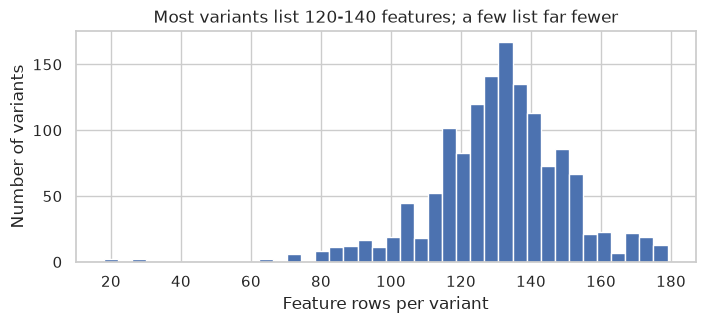

In [19]:
rows_per_variant = features.groupby(KEY).size().rename("feature_rows")
print(rows_per_variant.describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(rows_per_variant, bins=40, color="#4C72B0")
ax.set_xlabel("Feature rows per variant")
ax.set_ylabel("Number of variants")
ax.set_title("Most variants list 120-140 features; a few list far fewer")
plt.show()

In [20]:
rows_per_variant.sort_values().head(8).to_frame()

feature_rows
company    model             variant                                      
Porsche    Cayenne Electric  Turbo                                      18
                             Standard                                   18
Land Rover Discovery         3.0 Diesel Metropolitan Edition            28
                             3.0 Diesel Dynamic HSE                     29
           Range Rover Sport 3.0l Autobiography Petrol                  64
                             3.0 l Petrol Dynamic HSE                   64
                             3.0l Autobiography Diesel                  69
                             3.0 l Diesel Dynamic HSE                   71

Half of all variants list between 121 and 141 features. Four list far fewer: the two Porsche Cayenne Electric variants (18 each) and two Land Rover Discovery variants (28 and 29). After them comes a big gap, up to 64.

Is this a scraping error? The scraper wrote a log for every page it visited. Let's check it for the 8 shortest variants.

In [21]:
scrape_log = pd.read_csv(DATA_DIR / "new_variant_features_log.csv", dtype=str)
print("Status of all scraped pages:", scrape_log["status"].value_counts().to_dict())

shortest = rows_per_variant.sort_values().head(8).reset_index()
shortest.merge(scrape_log, on=KEY)[KEY + ["feature_rows", "page_heading", "error"]]

Status of all scraped pages: {'ok': 1399}


,company,model,variant,feature_rows,page_heading,error
0,Porsche,Cayenne Electric,Turbo,18,Cayenne Electric Turbo specifications & features,NaN
1,Porsche,Cayenne Electric,Standard,18,Cayenne Electric Standard specifications & features,NaN
2,Land Rover,Discovery,3.0 Diesel Metropolitan Edition,28,Discovery 3.0 Diesel Metropolitan Edition specifications & features,NaN
3,Land Rover,Discovery,3.0 Diesel Dynamic HSE,29,Discovery 3.0 Diesel Dynamic HSE specifications & features,NaN
4,Land Rover,Range Rover Sport,3.0l Autobiography Petrol,64,Range Rover Sport 3.0L Petrol Autobiography specifications & features,CarDekho renamed this page; features taken from final_url
5,Land Rover,Range Rover Sport,3.0 l Petrol Dynamic HSE,64,Range Rover Sport 3.0L Petrol HSE specifications & features,CarDekho renamed this page; features taken from final_url
6,Land Rover,Range Rover Sport,3.0l Autobiography Diesel,69,Range Rover Sport 3.0L Diesel Autobiography specifications & features,CarDekho renamed this page; features taken from final_url
7,Land Rover,Range Rover Sport,3.0 l Diesel Dynamic HSE,71,Range Rover Sport 3.0L Diesel HSE specifications & features,CarDekho renamed this page; features taken from final_url


Every page was scraped successfully, and each page's heading names the right variant. A few Range Rover Sport pages were renamed by CarDekho, and the scraper followed them to the new address. So the scraper saved everything on these pages: **CarDekho simply lists fewer features for them.**

**Decision:**
- Keep all 1,399 variants. The app can still show their prices and the features we do know.
- Flag the variants with fewer than 60 feature rows as `few_features`. The gap between 29 and 64 is a natural place to cut, and the flag catches the 4 shortest ones.
- Step 4 decides whether to leave flagged variants out of the price model, once we know which features the model uses.

In [22]:
FEW_FEATURES_CUTOFF = 60

variants = prices.merge(rows_per_variant.reset_index(), on=KEY, how="left", validate="one_to_one")
variants["few_features"] = variants["feature_rows"] < FEW_FEATURES_CUTOFF
variants.loc[variants["few_features"], KEY + ["feature_rows"]]

,company,model,variant,feature_rows
1335,Land Rover,Discovery,3.0 Diesel Dynamic HSE,29
1336,Land Rover,Discovery,3.0 Diesel Metropolitan Edition,28
1386,Porsche,Cayenne Electric,Standard,18
1387,Porsche,Cayenne Electric,Turbo,18


### 1.8 Result of Step 1

In [23]:
print(f"features: {len(features):,} rows (one row per feature of a variant)")
print(f"variants: {len(variants):,} rows (one row per variant, with its prices)")
print()
count_variants(variants)
print(f"Variants without an ex-showroom price: {variants['ex_showroom_price'].isna().sum()}")
print(f"Variants flagged few_features:         {variants['few_features'].sum()}")

assert len(variants) == 1399 and variants[KEY].duplicated().sum() == 0

features: 182,834 rows (one row per feature of a variant)
variants: 1,399 rows (one row per variant, with its prices)

Brands:   25
Models:   136
Variants: 1,399
Variants without an ex-showroom price: 0
Variants flagged few_features:         4


We now have two clean tables:
- **`features`**: every feature of every variant, with the 7 duplicate rows removed.
- **`variants`**: one row per variant with all its prices, its number of feature rows, and the `few_features` flag.

All 1,399 variants are matched. Step 2 turns `features` into one row per variant and joins it to `variants`.

What Step 1 found, and what it means later on:

| Finding | What we did / what it means later |
|---|---|
| 3 Mercedes variant names ("200", "300", "680") were read as numbers, so the join missed them | Read all names as text |
| 7 feature rows were listed twice | Dropped the copies |
| 10 feature values are empty | Left for Step 2's missing-value rules |
| `others` is the 1% TCS on cars above ₹10 lakh | A missing `others` means "no charge" |
| The on-road price includes optional accessories | The app shows accessories as optional |
| 2 variants have no on-road price | The app shows "not available" |
| All prices are from New Delhi, 20 Nov 2026 | A limit, stated in Step 7 |
| 4 variants list fewer than 60 features | Flagged; Step 4 decides about the price model |

## Step 2: Clean the features

**Why the app needs this:** the app can only search, filter and compare features that are written the same way for every car. The price model and the Finder also need real numbers and clear YES/NO values, not raw text.

This step has seven parts:
1. Merge feature names that mean the same thing.
2. Decide what a missing feature means.
3. Turn text into numbers.
4. Make values consistent.
5. Make one row per variant.
6. Write a data dictionary.
7. Spot-check a few variants, then save.

### 2.1 Merge feature names that mean the same thing

First, every feature name, grouped by section. "Additional Features" is left out, because it's a free-text note rather than a feature.

In [24]:
named = features[features["feature_name"] != "Additional Features"]
print(f"Feature names: {named['feature_name'].nunique()}")
for section, names in named.groupby("category")["feature_name"]:
    unique_names = sorted(names.unique())
    print(f"\n{section} ({len(unique_names)}): " + ", ".join(unique_names))

Feature names: 309

ADAS Feature (18): Adaptive Cruise Control, Adaptive High Beam Assist, Automatic Emergency Braking, Autonomous Parking, Blind Spot Collision Avoidance Assist, Blind Spot Monitor, Driver Attention Warning, Forward Collision Warning, Lane Departure Prevention Assist, Lane Departure Warning, Lane Keep Assist, Leading Vehicle Departure Alert, Oncoming Lane Mitigation, Rear Cross Traffic Alert, Rear Cross Traffic Collision-Avoidance Assist, Road Departure Mitigation System, Speed Assist System, Traffic Sign Recognition

Advance Internet Feature (33): Crash Notification, Digital Car Key, E-Call & I-Call, E-Manual, Engine Start Alarm, Geo-fence Alert, Google / Alexa Connectivity, Hinglish Voice Commands, In Car Remote Control App, Inbuilt APPs, Inbuilt Assistant, Insurance Expiry, Live Location, Live Weather, Navigation with Live Traffic, Over Speeding Alert, Over the Air (OTA) Updates, PUC Expiry, RSA, Remote AC On/Off, Remote Boot Open, Remote Door Lock/Unlock, Remote Im

That's too many names to compare reliably by eye. Two signals help:
- **The names look alike** (similar spelling, or most of their words shared).
- **They never appear on the same variant.** If two names are the same feature, a CarDekho page uses one or the other, never both.

The code below finds every pair of similar names and counts the variants that list both.

In [25]:
variants_with = named.groupby("feature_name")[KEY].apply(lambda g: set(map(tuple, g.values)))

def words(name):
    return set(re.sub(r"[^a-z0-9]+", " ", name.lower()).split())

similar_pairs = []
for a, b in itertools.combinations(variants_with.index, 2):
    spelling = difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()
    shared_words = len(words(a) & words(b)) / len(words(a) | words(b))
    if spelling >= 0.75 or shared_words >= 0.5:
        similar_pairs.append({"name_a": a, "name_b": b,
                              "variants_a": len(variants_with[a]), "variants_b": len(variants_with[b]),
                              "together": len(variants_with[a] & variants_with[b])})
similar_pairs = pd.DataFrame(similar_pairs)
print(f"Pairs of similar names:                    {len(similar_pairs)}")
print(f"... of which never appear on one variant:  {(similar_pairs['together'] == 0).sum()}")
similar_pairs[similar_pairs["together"] == 0].sort_values(["name_a", "name_b"]).reset_index(drop=True)

Pairs of similar names:                    106
... of which never appear on one variant:  31


,name_a,name_b,variants_a,variants_b,together
0,0-100Kmph (Tested),0-100kmph,4,124,0
1,0-100Kmph (Tested),Acceleration 0-100kmph,4,109,0
2,0-100kmph,Acceleration 0-100kmph,124,109,0
3,Adjustable Headrest,Adjustable Seats,1305,1,0
4,Antenna,Power Antenna,1169,11,0
5,Bharat NCAP Child Safety Rating,EURO NCAP Safety Rating,527,7,0
6,Bharat NCAP Safety Rating,EURO NCAP Safety Rating,615,7,0
7,Braking (100-0kmph),Braking (60-0 kmph),11,1,0
8,CNG Fuel Tank Capacity,Diesel Fuel Tank Capacity,62,374,0
9,CNG Fuel Tank Capacity,Petrol Fuel Tank Capacity,62,726,0


The pairs that never appear together fall into three groups:
- **The same feature under another name:**
  - Sun Roof / Sunroof
  - Petrol Fuel Tank Capacity (Litres) / Petrol Fuel Tank Capacity
  - Reported Ground Clearance (Unladen) / Ground Clearance Unladen
  - 0-100kmph / Acceleration 0-100kmph
- **The same measurement for different fuels,** e.g. Petrol / Diesel / CNG Mileage ARAI, and Petrol / Diesel / CNG Fuel Tank Capacity. They never appear together because a car has one main fuel. We'll combine each into one column in 2.3.
- **Different things with similar names,** e.g. Exterior vs Interior Camera, Ground Clearance (Laden) vs Unladen, EURO vs Global NCAP rating, Antenna vs Power Antenna, and 0-100Kmph (Tested), which is CarDekho's own road test on 4 variants. These stay separate.

Reading the full list also suggests pairs the spelling search can't catch, because their names look different. For each one, we check how often both appear on the same variant, and whether their values agree when they do:

In [26]:
named_wide = named.drop_duplicates(KEY + ["feature_name"]).pivot(index=KEY, columns="feature_name", values="feature_details")

def compare_names(a, b):
    both = named_wide[a].notna() & named_wide[b].notna()
    return {"name_a": a, "name_b": b,
            "variants_a": named_wide[a].notna().sum(), "variants_b": named_wide[b].notna().sum(),
            "together": both.sum(),
            "same value when together": (named_wide.loc[both, a] == named_wide.loc[both, b]).sum()}

extra_pairs = [
    ("Acceleration", "0-100kmph"),
    ("EBD", "Electronic Brakeforce Distribution (EBD)"),
    ("Heated Wing Mirror", "Heated Outside Rear View Mirror"),
    ("SOS Button", "SOS / Emergency Assistance"),
    ("Exterior Camera", "360 View Camera"),
    ("Power Boot", "Boot Opening"),
    ("Leather Seats", "Upholstery"),
    ("Fog Lights - Front", "Fog Lights"),
    ("Reported Boot Space", "Boot Space"),
    ("Motor Power", "Max Power"),
]
pd.DataFrame([compare_names(a, b) for a, b in extra_pairs])

,name_a,name_b,variants_a,variants_b,together,same value when together
0,Acceleration,0-100kmph,124,124,124,124
1,EBD,Electronic Brakeforce Distribution (EBD),2,1314,0,0
2,Heated Wing Mirror,Heated Outside Rear View Mirror,19,202,3,3
3,SOS Button,SOS / Emergency Assistance,577,382,225,225
4,Exterior Camera,360 View Camera,77,1093,11,0
5,Power Boot,Boot Opening,17,1023,0,0
6,Leather Seats,Upholstery,20,1286,1,0
7,Fog Lights - Front,Fog Lights,24,941,1,0
8,Reported Boot Space,Boot Space,255,979,74,62
9,Motor Power,Max Power,153,1382,153,0


In [27]:
print("Values of 'Exterior Camera':", named_wide["Exterior Camera"].value_counts().to_dict())
print("Examples of 'Motor Power':  ", named_wide["Motor Power"].dropna().unique()[:4].tolist())
ev_no_power = (named_wide["Fuel Type"] == "Electric") & named_wide["Max Power"].isna()
print(f"EVs with no Max Power: {ev_no_power.sum()}, and of those with a Motor Power: {named_wide.loc[ev_no_power, 'Motor Power'].notna().sum()}")

Values of 'Exterior Camera': {'360° Camera': 40, 'Rear View Camera': 24, '540° Camera': 7, 'Front and Rear Only': 5, 'NO': 1}
Examples of 'Motor Power':   ['240', '150 kW', '170 kW', '390 kW']
EVs with no Max Power: 16, and of those with a Motor Power: 0


**Decisions:**

| Names | Decision | Reason |
|---|---|---|
| Sun Roof → Sunroof | merge | never on the same variant |
| Petrol Fuel Tank Capacity (Litres) → Petrol Fuel Tank Capacity | merge | never on the same variant |
| Reported Ground Clearance (Unladen) → Ground Clearance Unladen | merge | never on the same variant |
| Acceleration 0-100kmph → 0-100kmph | merge | never on the same variant |
| EBD → Electronic Brakeforce Distribution (EBD) | merge | never on the same variant |
| Heated Wing Mirror → Heated Outside Rear View Mirror | merge | the 3 variants with both agree |
| Acceleration | drop | an exact copy of 0-100kmph on every variant |
| SOS Button + SOS / Emergency Assistance | combine into one SOS column (2.5) | they always agree when both appear |
| Exterior Camera | fills 360 View Camera and Rear Camera when those are missing (2.5) | its values name the camera type |
| Power Boot | fills Boot Opening = "Powered" when missing (2.5) | never on the same variant |
| Leather Seats | fills Upholstery = "Leather" when missing (2.5) | appears with Upholstery on only 1 variant |
| Fog Lights - Front | fills Fog Lights when missing (2.5) | appears with Fog Lights on only 1 variant |
| Reported Boot Space | fills Boot Space when missing (2.3) | agrees for 62 of the 74 variants with both |
| Motor Power | not used | it's in kW (one value in hp), and it doesn't fill any EV's missing power |

In [28]:
RENAME = {
    "Sun Roof": "Sunroof",
    "Petrol Fuel Tank Capacity (Litres)": "Petrol Fuel Tank Capacity",
    "Reported Ground Clearance (Unladen)": "Ground Clearance Unladen",
    "Acceleration 0-100kmph": "0-100kmph",
    "EBD": "Electronic Brakeforce Distribution (EBD)",
    "Heated Wing Mirror": "Heated Outside Rear View Mirror",
}
DROP = ["Acceleration"]

features["feature_name"] = features["feature_name"].replace(RENAME)
features = features[~features["feature_name"].isin(DROP)]

# A merge can leave one variant with the same feature twice (only Heated Wing Mirror can, see above).
repeated = features.duplicated(KEY + ["feature_name"]) & (features["feature_name"] != "Additional Features")
print(f"Rows repeated after merging: {repeated.sum()}")
features = features[~repeated].reset_index(drop=True)
print(f"Feature names now: {features.loc[features['feature_name'] != 'Additional Features', 'feature_name'].nunique()}")

Rows repeated after merging: 3
Feature names now: 302


### 2.2 Decide what a missing feature means

Some features are written as "NO", and some are simply missing. Here are some important ones:

In [29]:
wide_text = (features[features["feature_name"] != "Additional Features"]
             .pivot(index=KEY, columns="feature_name", values="feature_details"))

KEY_FEATURES = ["Sunroof", "Ventilated Seats", "360 View Camera", "Alloy Wheels", "Automatic Emergency Braking",
                "Wireless Phone Charging", "Cruise Control", "Paddle Shifters", "Heads-Up Display (HUD)", "Rear Camera"]

def value_summary(name):
    s = wide_text[name]
    return {"feature": name, "YES": (s == "YES").sum(), "NO": (s == "NO").sum(),
            "other value": (s.notna() & ~s.isin(["YES", "NO"])).sum(), "missing": s.isna().sum()}

pd.DataFrame([value_summary(n) for n in KEY_FEATURES])

,feature,YES,NO,other value,missing
0,Sunroof,43,249,902,205
1,Ventilated Seats,601,521,12,265
2,360 View Camera,641,452,0,306
3,Alloy Wheels,755,99,0,545
4,Automatic Emergency Braking,285,425,0,689
5,Wireless Phone Charging,839,481,0,79
6,Cruise Control,1111,237,0,51
7,Paddle Shifters,538,493,0,368
8,Heads-Up Display (HUD),135,303,0,961
9,Rear Camera,1,149,1100,149


Missing values are common: for example, 961 variants don't list a heads-up display at all. Does missing mean "NO"? To find out, look at how CarDekho lists features **within one model**. If it lists a feature for every variant of a model, writing "NO" on the variants without it, then a missing feature means something else.

In [30]:
variants_per_model = wide_text.groupby(level=["company", "model"]).size()
listed_share = wide_text.notna().groupby(level=["company", "model"]).mean()   # share of a model's variants listing each feature
shares = listed_share[variants_per_model >= 2].stack()
shares = shares[shares > 0]   # only features the model lists at least once

print(f"Model + feature pairs (models with 2+ variants): {len(shares):,}")
print(f"... where the feature is listed for every variant of the model: {(shares == 1).mean():.0%}")

Model + feature pairs (models with 2+ variants): 13,364
... where the feature is listed for every variant of the model: 91%


In 91% of cases, a model lists a feature for **all** its variants or for none. So CarDekho uses one feature list per model, and the cheaper variants get an explicit "NO". That splits missing values into two kinds:
- **Whole-model gap:** no variant of the model lists the feature. CarDekho simply doesn't track it for that model.
- **Partial gap:** other variants of the same model do list it.

If missing meant "NO", partial gaps should sit at the cheap end of a model's range, like the real NOs do. Below, a variant's **price position** is its place in its own model's range, from about 0 (cheapest) to 1 (most expensive).

In [31]:
in_model = wide_text.notna().groupby(level=["company", "model"]).transform("any")   # does any variant of the model list it?
price = variants.set_index(KEY)["ex_showroom_price"].reindex(wide_text.index)
price_position = price.groupby(level=["company", "model"]).rank(pct=True)

rows = []
for name in KEY_FEATURES:
    s = wide_text[name]
    whole_gap = s.isna() & ~in_model[name]
    partial_gap = s.isna() & in_model[name]
    rows.append({"feature": name, "missing": s.isna().sum(),
                 "whole-model gaps": whole_gap.sum(), "partial gaps": partial_gap.sum(),
                 "price position of YES": price_position[s == "YES"].mean(),
                 "price position of NO": price_position[s == "NO"].mean(),
                 "price position of partial gaps": price_position[partial_gap].mean()})
pd.DataFrame(rows).round(2)

,feature,missing,whole-model gaps,partial gaps,price position of YES,price position of NO,price position of partial gaps
0,Sunroof,205,203,2,0.73,0.29,0.83
1,Ventilated Seats,265,251,14,0.70,0.35,0.42
2,360 View Camera,306,301,5,0.68,0.35,0.85
3,Alloy Wheels,545,526,19,0.60,0.22,0.50
4,Automatic Emergency Braking,689,662,27,0.72,0.41,0.49
5,Wireless Phone Charging,79,75,4,0.67,0.32,0.75
6,Cruise Control,51,41,10,0.59,0.33,0.61
7,Paddle Shifters,368,363,5,0.66,0.41,0.73
8,Heads-Up Display (HUD),961,955,6,0.79,0.45,0.33
9,Rear Camera,149,140,9,0.50,0.28,0.54


- **Almost every missing value is a whole-model gap.** For example, 955 of the 961 missing heads-up display values.
- **The few partial gaps don't look like "NO".** Real NOs sit low in their model's range, at about 0.2–0.45. Partial gaps are spread out, and for sunroof, 360° camera and wireless charging they sit near the top. They look more like page errors than missing equipment.

The biggest whole-model gap is ADAS (driver-assistance features such as automatic emergency braking). Many models have no ADAS section on CarDekho at all. Are those simply cars without ADAS? Compare by price:

In [32]:
adas_features = sorted(features.loc[features["category"] == "ADAS Feature", "feature_name"].unique())
has_adas_section = wide_text[adas_features].notna().any(axis=1)
has_some_adas = wide_text[adas_features].eq("YES").any(axis=1)

band = pd.cut(price, [0, 10e5, 20e5, 50e5, 100e5, np.inf],
              labels=["up to ₹10 lakh", "₹10-20 lakh", "₹20-50 lakh", "₹50 lakh-₹1 crore", "over ₹1 crore"])
adas_by_band = pd.DataFrame({
    "variants": band.value_counts(sort=False),
    "with an ADAS section": has_adas_section.groupby(band, observed=False).sum(),
    "... and some ADAS": (has_adas_section & has_some_adas).groupby(band, observed=False).sum(),
    "with no ADAS section": (~has_adas_section).groupby(band, observed=False).sum(),
})
adas_by_band["share with ADAS, where listed"] = (adas_by_band["... and some ADAS"] / adas_by_band["with an ADAS section"]).round(2)
adas_by_band

,variants,with an ADAS section,... and some ADAS,with no ADAS section,"share with ADAS, where listed"
ex_showroom_price,,,,,
up to ₹10 lakh,185,103,15,82,0.15
₹10-20 lakh,709,547,207,162,0.38
₹20-50 lakh,362,348,273,14,0.78
₹50 lakh-₹1 crore,52,41,38,11,0.93
over ₹1 crore,91,56,52,35,0.93


In [33]:
no_section = (~has_adas_section).groupby(level=["company", "model"]).all()
models_without = price.groupby(level=["company", "model"]).median()[no_section].sort_values()
print(f"Models with no ADAS section on any variant: {no_section.sum()} of {len(no_section)}\n")
print("Cheapest 6:      ", ", ".join(f"{b} {m}" for b, m in models_without.index[:6]))
print("Most expensive 6:", ", ".join(f"{b} {m}" for b, m in models_without.index[-6:]))

Models with no ADAS section on any variant: 37 of 136

Cheapest 6:       Renault Kiger, Nissan Magnite, Mahindra Bolero, Toyota Taisor, Mahindra Bolero Neo, Skoda Kylaq
Most expensive 6: Porsche Cayenne Electric, Toyota Land Cruiser 300, Audi RS Q8, BMW XM, Mercedes-Benz G-Class, Mercedes-Benz G-Class Electric


Where CarDekho does list ADAS, the share of cars with some of it rises steeply with price: 15% up to ₹10 lakh, 93% above ₹50 lakh. So the expensive models with no ADAS section, such as the Mercedes-Benz G-Class and Toyota Land Cruiser 300, most likely do have ADAS features and CarDekho just doesn't list them. For cheap models like the Nissan Magnite or Mahindra Bolero, "no ADAS" is plausible, but the data can't prove it.

**Decision: a missing feature means "unknown", not "NO".** There are three exceptions, each backed by evidence:
1. **A detail of something the car doesn't have.** If a car has no touchscreen, its screen size is missing. That's not unknown: the size is 0. The check below confirms this pattern.
2. **Fuel-specific features.** A diesel car has no petrol mileage. These are "not applicable", and they disappear when we combine each measurement into one column (2.3).
3. **Filled from a related feature.** These are the pairs decided in 2.1 (Exterior Camera, Power Boot, Leather Seats, Fog Lights - Front, Reported Boot Space).

**What this means for the app:**
- The Finder only shows a car as having a feature when CarDekho says YES.
- The variant page shows "not listed" for unknown features, not "no".

In [34]:
for parent, detail in [("Touchscreen", "Touchscreen Size"), ("Speakers", "No. of Speakers"), ("Digital Cluster", "Digital Cluster Size")]:
    partial_gap = wide_text[detail].isna() & in_model[detail]
    print(f"{detail}: {partial_gap.sum()} partial gaps. Value of '{parent}' on those variants: "
          f"{wide_text.loc[partial_gap, parent].value_counts(dropna=False).to_dict()}")

Touchscreen Size: 66 partial gaps. Value of 'Touchscreen' on those variants: {'NO': 55, 'YES': 7, nan: 4}


No. of Speakers: 63 partial gaps. Value of 'Speakers' on those variants: {'NO': 48, 'Front & Rear': 9, nan: 4, 'Front Only': 2}
Digital Cluster Size: 54 partial gaps. Value of 'Digital Cluster' on those variants: {nan: 36, 'Analogue with MID': 9, 'NO': 8, 'YES': 1}


For touchscreen size and number of speakers, most partial gaps are cars where the parent feature is "NO". That supports exception 1: no touchscreen means a size of 0, and no speakers means 0 speakers.

For the digital cluster size the pattern is weaker: most of its partial gaps have no Digital Cluster value at all. So only an explicit "NO" gets a size of 0 there. We apply all of this in 2.3.

### 2.3 Turn text into numbers

Most number features are written with units, e.g. `118.27bhp@5500rpm` or `622 Litres`. We take the first number in each value, then check two things: which values failed to convert, and whether the smallest and largest results make sense.

In [35]:
def first_number(text):
    """Pull the first number out of each text value, e.g. '118.27bhp@5500rpm' -> 118.27."""
    return pd.to_numeric(text.str.extract(r"(\d+(?:\.\d+)?)", expand=False), errors="coerce")

NUMBER_FEATURES = {   # CarDekho feature name -> clean column name
    "Max Power": "power_bhp", "Max Torque": "torque_nm", "Displacement": "engine_cc", "No. of Cylinders": "cylinders",
    "Length": "length_mm", "Width": "width_mm", "Height": "height_mm", "Wheel Base": "wheelbase_mm",
    "Ground Clearance Unladen": "ground_clearance_mm", "Boot Space": "boot_litres", "Seating Capacity": "seats",
    "Touchscreen Size": "touchscreen_in", "Digital Cluster Size": "cluster_in", "No. of Speakers": "speakers",
    "No. of Airbags": "airbags", "Wheel Size": "wheel_in", "Battery Capacity": "battery_kwh", "Range": "range_km",
    "Petrol Mileage ARAI": "petrol_kmpl", "Diesel Mileage ARAI": "diesel_kmpl", "CNG Mileage ARAI": "cng_km_per_kg",
    "Petrol Fuel Tank Capacity": "petrol_tank_l", "Diesel Fuel Tank Capacity": "diesel_tank_l",
    "Top Speed": "top_speed_kmph", "0-100kmph": "accel_0_100_s",
    "Bharat NCAP Safety Rating": "bharat_ncap_stars", "Global NCAP Safety Rating": "global_ncap_stars",
}

numbers = pd.DataFrame(index=wide_text.index)
report = []
for name, column in NUMBER_FEATURES.items():
    text = wide_text[name]
    numbers[column] = first_number(text)
    failed = text.notna() & numbers[column].isna()
    report.append({"feature": name, "column": column, "values": text.notna().sum(), "failed": failed.sum(),
                   "failed examples": ", ".join(text[failed].unique()[:3]),
                   "min": numbers[column].min(), "max": numbers[column].max()})
pd.DataFrame(report)

,feature,column,values,failed,failed examples,min,max
0,Max Power,power_bhp,1382,0,,68.00,649.00
1,Max Torque,torque_nm,1381,0,,95.20,1500.00
2,Displacement,engine_cc,1221,0,,998.00,5000.00
3,No. of Cylinders,cylinders,1220,0,,3.00,8.00
4,Length,length_mm,1398,0,,3830.00,5358.00
5,Width,width_mm,1395,0,,1645.00,2230.00
6,Height,height_mm,1395,0,,1550.00,1995.00
7,Wheel Base,wheelbase_mm,1379,0,,2080.00,3264.00
8,Ground Clearance Unladen,ground_clearance_mm,581,0,,1.00,254.00
9,Boot Space,boot_litres,979,0,,123.00,1131.00


Almost everything converts. What needs fixing:
- **Touchscreen Size** fails on "No inch" and **Digital Cluster Size** on "NO": there's no screen, so the size is 0. Following the rule from 2.2, a car whose Touchscreen, Speakers or Digital Cluster is "NO" also gets 0 for the size or count.
- **Ground clearance** has a minimum of 1 mm, which is impossible.
- **Range** sometimes gives two numbers, e.g. "335-355 km". Taking only the first undersells the car, so we use the middle.

Everything else is within sensible limits: power from 68 to 649 bhp, length from 3,830 to 5,358 mm.

In [36]:
print("Ground clearance values under 100 mm:")
print(wide_text.loc[numbers["ground_clearance_mm"] < 100, "Ground Clearance Unladen"].to_string())
print("\nRange values with two numbers:", wide_text["Range"][wide_text["Range"].str.contains("-", na=False)].unique().tolist())

Ground clearance values under 100 mm:
company  model  variant             
Hyundai  Creta  S (O)                   1 mm
                S (O) Summer Edition    1 mm

Range values with two numbers: ['335-355 km', '260-275 km']


In [37]:
# Screens and speakers the car doesn't have: size or count is 0 (rule 1 from 2.2).
numbers.loc[wide_text["Touchscreen Size"].str.contains("no", case=False, na=False), "touchscreen_in"] = 0
numbers.loc[wide_text["Digital Cluster Size"].eq("NO"), "cluster_in"] = 0
for parent, column in [("Touchscreen", "touchscreen_in"), ("Speakers", "speakers"), ("Digital Cluster", "cluster_in")]:
    numbers.loc[wide_text[parent].eq("NO") & numbers[column].isna(), column] = 0

# Impossible ground clearance: unknown.
numbers.loc[numbers["ground_clearance_mm"] < 100, "ground_clearance_mm"] = np.nan

# Range given as "low-high": use the middle.
two_numbers = wide_text["Range"].str.extract(r"(\d+)\s*-\s*(\d+)").astype(float)
numbers["range_km"] = numbers["range_km"].where(two_numbers[0].isna(), two_numbers.mean(axis=1))

Two columns can be filled from related features:
- **Boot space** from "Reported Boot Space" (decided in 2.1).
- **Wheel size** from the tyre size: the "R17" in "215/60 R17" is the wheel size in inches. First we check that the two agree where both are known.

In [38]:
tyre_rim = pd.to_numeric(wide_text["Tyre Size"].str.extract(r"R\s*(\d{2})", expand=False), errors="coerce")
both = tyre_rim.notna() & numbers["wheel_in"].notna()
print(f"Wheel size and tyre rim both known: {both.sum()}; they agree for {(tyre_rim[both] == numbers.loc[both, 'wheel_in']).sum()}")

filled_wheels = numbers["wheel_in"].isna() & tyre_rim.notna()
numbers["wheel_in"] = numbers["wheel_in"].fillna(tyre_rim)
reported_boot = first_number(wide_text["Reported Boot Space"])
filled_boot = numbers["boot_litres"].isna() & reported_boot.notna()
numbers["boot_litres"] = numbers["boot_litres"].fillna(reported_boot)
print(f"Wheel size filled from tyre size: {filled_wheels.sum()}")
print(f"Boot space filled from Reported Boot Space: {filled_boot.sum()}")

Wheel size and tyre rim both known: 808; they agree for 799
Wheel size filled from tyre size: 469
Boot space filled from Reported Boot Space: 181


They agree for almost all variants, so filling is safe.

Finally, the fuel-specific columns become one column per measurement, picked by the car's fuel:
- **`mileage_kmpl`**: petrol or diesel ARAI mileage.
- **`fuel_tank_l`**: petrol or diesel tank size.
- CNG mileage is in km per kg, a different unit, so it stays in its own column.

In [39]:
fuel = wide_text["Fuel Type"]
numbers["mileage_kmpl"] = np.where(fuel == "Diesel", numbers["diesel_kmpl"], numbers["petrol_kmpl"])
numbers["fuel_tank_l"] = np.where(fuel == "Diesel", numbers["diesel_tank_l"], numbers["petrol_tank_l"])
numbers.loc[fuel == "Electric", ["mileage_kmpl", "fuel_tank_l"]] = np.nan
numbers = numbers.drop(columns=["petrol_kmpl", "diesel_kmpl", "petrol_tank_l", "diesel_tank_l"])

print("Mileage known, by fuel type:")
print(numbers["mileage_kmpl"].notna().groupby(fuel).agg(["sum", "size"]).rename(columns={"sum": "known", "size": "variants"}).to_string())

Mileage known, by fuel type:
           known  variants
Fuel Type                 
CNG            0        62
Diesel       175       392
Electric       0       178
Petrol       514       767


### 2.4 Make values consistent

Some features use several words for the same thing. The raw values:

In [40]:
MULTI_VALUE = ["Sunroof", "Drive Type", "Electric Adjustable Seats", "Upholstery", "Parking Sensors", "Boot Opening",
               "Ventilated Seats", "Rear Camera", "Turbo Charger", "Android Auto", "Apple CarPlay", "Fog Lights",
               "Digital Cluster", "Rear Brake Type", "Hybrid Type"]
for name in MULTI_VALUE:
    print(f"{name}: {wide_text[name].value_counts().to_dict()}")

Sunroof: {'Panoramic': 677, 'NO': 249, 'Single Pane': 185, 'YES': 43, 'Dual Pane': 39, 'Dual Sunroof': 1}
Drive Type: {'FWD': 983, 'AWD': 158, 'RWD': 133, '2WD': 66, '4WD': 50, '4x4': 4, 'RWD(with MTT)': 1}
Electric Adjustable Seats: {'NO': 365, 'Front': 324, 'Driver Seat Only': 142, 'Front Only': 121, 'Front & Rear': 37, 'Front and Rear': 2}
Upholstery: {'Leatherette': 695, 'Fabric': 450, 'Leather': 109, 'Semi-Leatherette': 23, 'Vinyl': 9}
Parking Sensors: {'Rear': 764, 'Front & Rear': 628, 'YES': 1, 'Front': 1}
Boot Opening: {'Electronic': 428, 'Manual': 282, 'Hands-Free': 149, 'Powered': 145, 'Automatic': 19}
Ventilated Seats: {'YES': 601, 'NO': 521, 'Front Only': 12}
Rear Camera: {'With Guidedlines': 1086, 'NO': 149, 'Without Guidedlines': 14, 'YES': 1}
Turbo Charger: {'YES': 822, 'NO': 179, 'twin': 12, 'Twin': 10}
Android Auto: {'YES': 1128, 'Wireless': 169, 'NO': 71, 'Wired': 7}
Apple CarPlay: {'YES': 1133, 'Wireless': 137, 'NO': 67, 'Wired': 38}
Fog Lights: {'Front': 347, 'NO': 

**Decisions:**
- **Sunroof:** None / Single / Panoramic. "Dual Pane" and "Dual Sunroof" count as Panoramic, because they cover both rows. "YES" (from the merged "Sun Roof" name) becomes "Yes, type not listed".
- **Drive:** 2WD (FWD, RWD, 2WD) or 4x4/AWD (AWD, 4WD, 4x4).
- **Electric seats:** None / Driver only / Front / Front & Rear. "Front" and "Front Only" are the same; so are "Front & Rear" and "Front and Rear".
- **Upholstery:** Fabric (including Vinyl), Leatherette (including Semi-Leatherette) and Leather. The groups follow price and feel: vinyl is basic, and semi-leatherette is mostly leatherette.
- **Yes-like values become YES:**
  - ventilated seats "Front Only";
  - rear camera "With/Without Guidedlines" (CarDekho's spelling);
  - turbo "twin"/"Twin";
  - Android Auto and Apple CarPlay "Wireless"/"Wired". We also keep a separate flag for wireless.
- **Fog lights:** we keep front fog lamps (Front, Front & Rear) as YES. "Rear" only counts as no front fog lamps.
- **Digital cluster:** fully digital (YES, Full, "Fully Digital…") is YES. Semi, Analog with MID and MID are NO.
- **Rear brakes:** disc (any kind) is YES, drum is NO.
- **Hybrid type:** Mild / Strong / Plug-in.
- **"Optional" values** (e.g. Roof Rails) become NO, because the feature isn't included in the listed price.

In [41]:
def snake(name):
    """'Heads-Up Display (HUD)' -> 'heads_up_display_hud'."""
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

CATEGORY_MAPS = {
    "Sunroof": ("sunroof", {"NO": "None", "Single Pane": "Single", "Panoramic": "Panoramic", "Dual Pane": "Panoramic",
                            "Dual Sunroof": "Panoramic", "YES": "Yes, type not listed"}),
    "Drive Type": ("drive", {"FWD": "2WD", "RWD": "2WD", "2WD": "2WD", "RWD(with MTT)": "2WD",
                             "AWD": "4x4/AWD", "4WD": "4x4/AWD", "4x4": "4x4/AWD"}),
    "Electric Adjustable Seats": ("electric_seats", {"NO": "None", "Driver Seat Only": "Driver only", "Front": "Front",
                                                     "Front Only": "Front", "Front & Rear": "Front & Rear", "Front and Rear": "Front & Rear"}),
    "Upholstery": ("upholstery", {"Fabric": "Fabric", "Vinyl": "Fabric", "Leatherette": "Leatherette",
                                  "Semi-Leatherette": "Leatherette", "Leather": "Leather"}),
    "Parking Sensors": ("parking_sensors", {"Rear": "Rear", "Front & Rear": "Front & Rear", "Front": "Front", "YES": "Yes, position not listed"}),
    "Boot Opening": ("boot_opening", {"Manual": "Manual", "Electronic": "Electronic", "Powered": "Powered",
                                      "Automatic": "Powered", "Hands-Free": "Hands-free"}),
    "Hybrid Type": ("hybrid_type", {"Mild Hybrid": "Mild", "Mild Hybrid(Electric + Petrol)": "Mild", "Strong Hybrid": "Strong",
                                    "Strong Hybrid(Electric + Petrol)": "Strong", "Plug-in Hybrid": "Plug-in"}),
}

def yes_unless(text, no_values=("NO",)):
    """1 for any listed value except the 'no' values, 0 for those, empty (unknown) when missing."""
    return np.where(text.isna(), np.nan, np.where(text.isin(no_values), 0, 1))

YES_LIKE = {   # feature -> (column, values that mean NO)
    "Ventilated Seats": ("has_ventilated_seats", ["NO"]),
    "Rear Camera": ("has_rear_camera", ["NO"]),
    "Turbo Charger": ("has_turbo", ["NO"]),
    "Android Auto": ("has_android_auto", ["NO"]),
    "Apple CarPlay": ("has_apple_carplay", ["NO"]),
    "Fog Lights": ("has_front_fog_lamps", ["NO", "Rear"]),
    "Digital Cluster": ("has_digital_cluster", ["NO", "Semi", "Analog with MID", "Analogue with MID", "ANALOG WITH MID", "MID"]),
    "Rear Brake Type": ("has_rear_disc_brakes", ["Drum", "drum"]),
    "Electric Adjustable Seats": ("has_electric_seats", ["NO"]),
    "Heated Seats": ("has_heated_seats", ["NO"]),
    "KeyLess Entry": ("has_keyless_entry", ["NO"]),
    "Roof Rails": ("has_roof_rails", ["NO", "Optional"]),
    "Height Adjustable Driver Seat": ("has_height_adjustable_driver_seat", ["NO", "Optional"]),
    "Side Stepper": ("has_side_stepper", ["NO", "Optional"]),
}

categories = pd.DataFrame(index=wide_text.index)
for name, (column, mapping) in CATEGORY_MAPS.items():
    categories[column] = wide_text[name].map(mapping)
    unmapped = wide_text[name].notna() & categories[column].isna()
    assert not unmapped.any(), f"{name}: values not mapped: {wide_text.loc[unmapped, name].unique()}"
categories["has_sunroof"] = np.where(categories["sunroof"].isna(), np.nan, (categories["sunroof"] != "None").astype(float))
for name, (column, no_values) in YES_LIKE.items():
    categories[column] = yes_unless(wide_text[name], no_values)
categories["has_wireless_phone_projection"] = np.where(
    wide_text["Android Auto"].isna() & wide_text["Apple CarPlay"].isna(), np.nan,
    (wide_text["Android Auto"].eq("Wireless") | wide_text["Apple CarPlay"].eq("Wireless")).astype(float))

print(categories["sunroof"].value_counts(dropna=False).to_string())

sunroof
Panoramic               717
None                    249
NaN                     205
Single                  185
Yes, type not listed     43


**Gearbox type.** The `Gearbox` text mixes the number of gears with the gearbox type, written in 57 different ways. We sort it into types that matter to a buyer and to the price:
- **Manual**
- **AMT:** an automated manual, the cheapest kind of automatic.
- **CVT**
- **DCT:** includes DSG, DCA and PDK, which are brand names for dual-clutch gearboxes.
- **Torque-converter AT:** includes the brand names TRONIC, Steptronic and TCT.
- **Hybrid:** e-CVT and DHT, the gearboxes of strong hybrids.
- **Single-speed (EV)**

Many automatics only say "8-Speed". Those get "Automatic, type not listed" rather than a guess.

In [42]:
def gearbox_type(gearbox, transmission, fuel_type):
    text = str(gearbox).lower()
    if transmission == "Manual":
        return "Manual"
    if fuel_type == "Electric" or re.search(r"single speed|1-speed|1 gear", text):
        return "Single-speed (EV)"
    if "amt" in text:
        return "AMT"
    if re.search(r"dct|dca|dsg|pdk", text):
        return "DCT"
    if re.search(r"e-cvt|dht", text):
        return "Hybrid"
    if re.search(r"cvt|ivt", text):
        return "CVT"
    if re.search(r"\bat\b|tronic|sequential|tct", text):
        return "Torque-converter AT"
    return "Automatic, type not listed"

basics = pd.DataFrame(index=wide_text.index)
basics["fuel_type"] = wide_text["Fuel Type"]
basics["transmission"] = wide_text["Transmission Type"]
basics["gearbox_type"] = [gearbox_type(g, t, f) for g, t, f in
                          zip(wide_text["Gearbox"], wide_text["Transmission Type"], wide_text["Fuel Type"])]
basics["gears"] = first_number(wide_text["Gearbox"])
basics.loc[basics["gearbox_type"].isin(["CVT", "Hybrid"]), "gears"] = np.nan
basics.loc[basics["gearbox_type"] == "Single-speed (EV)", "gears"] = 1

pd.crosstab(basics["gearbox_type"], basics["transmission"])

transmission,Automatic,Manual
gearbox_type,,
AMT,35,0
"Automatic, type not listed",338,0
CVT,48,0
DCT,92,0
Hybrid,26,0
Manual,0,553
Single-speed (EV),178,0
Torque-converter AT,129,0


In [43]:
sample = wide_text["Gearbox"].dropna().drop_duplicates()
check = pd.DataFrame({"Gearbox text": sample.values,
                      "type": [gearbox_type(g, t, f) for g, t, f in zip(sample, wide_text.loc[sample.index, "Transmission Type"],
                                                                         wide_text.loc[sample.index, "Fuel Type"])]})
for kind, texts in check.groupby("type")["Gearbox text"]:
    print(f"{kind}: {', '.join(sorted(texts))}\n")

AMT: 5-Speed AMT, 6-Speed AMT, Smart auto AMT, easy-R AMT

Automatic, type not listed: 10-Speed, 4-Speed, 7 Speed, 7-Speed, 8-Speed, 8-speed, 9-Speed

CVT: 6-Speed iVT, CVT, iVT, x-tronic CVT

DCT: 6-Speed DCT, 7 - Speed DCT, 7-Speed DCA, 7-Speed DCT, 7-Speed DSG, 7-Speed PDK, 7-speed DCT, 7-speed DSG, 8-Speed DCT

Hybrid: 8-Speed DHT, E-CVT

Manual: 5 Speed, 5-Speed, 5-Speed MT, 5-speed, 6 - Speed, 6 Speed, 6-Speed, 6-Speed iMT, 6-speed

Single-speed (EV): 1-Speed, Automatic 1 Gear, Shift-by-wire AT, Single Speed

Torque-converter AT: 10-Speed AT, 6 - Speed AT, 6 -Speed AT, 6-Speed AT, 6-Speed with Sequential Shift, 7-Speed AT, 7-Speed Steptronic, 8 -Speed AT, 8 Speed AT, 8-Speed AT, 8-Speed Steptronic, 9-Speed AT, 9-Speed TCT AMG, 9-Speed TRONIC, 9-Speed TRONIC AT, 9-Speed Tronic, 9-speed AT, 9G-TRONIC



### 2.5 Make one row per variant

Now we put it all together. Every remaining feature whose only values are YES and NO becomes a 0/1 column named `has_<feature>`; an empty value means unknown. Then the fills decided in 2.1 are applied, and the result is joined to the prices from Step 1.

In [44]:
handled = set(NUMBER_FEATURES) | set(CATEGORY_MAPS) | set(YES_LIKE) | {"Fuel Type", "Transmission Type", "Gearbox"}
yes_no_only = [name for name in wide_text.columns
               if name not in handled and set(wide_text[name].dropna().unique()) <= {"YES", "NO"}]
binary = pd.DataFrame({f"has_{snake(name)}": wide_text[name].map({"YES": 1, "NO": 0}) for name in yes_no_only}).copy()
binary = binary.loc[:, ~binary.columns.isin(categories.columns)]
print(f"YES/NO features turned into 0/1 columns: {binary.shape[1]}")

# Fills and combinations decided in 2.1
filled = {}
camera = wide_text["Exterior Camera"]
fill_360 = binary["has_360_view_camera"].isna() & camera.isin(["360° Camera", "540° Camera"])
binary.loc[fill_360, "has_360_view_camera"] = 1
fill_rear = categories["has_rear_camera"].isna() & camera.isin(["Rear View Camera", "Front and Rear Only", "360° Camera", "540° Camera"])
categories.loc[fill_rear, "has_rear_camera"] = 1
fill_boot = categories["boot_opening"].isna() & wide_text["Power Boot"].eq("YES")
categories.loc[fill_boot, "boot_opening"] = "Powered"
fill_leather = categories["upholstery"].isna() & wide_text["Leather Seats"].eq("YES")
categories.loc[fill_leather, "upholstery"] = "Leather"
fill_fog = categories["has_front_fog_lamps"].isna() & wide_text["Fog Lights - Front"].notna()
categories.loc[fill_fog, "has_front_fog_lamps"] = wide_text.loc[fill_fog, "Fog Lights - Front"].map({"YES": 1, "NO": 0})
sos = wide_text[["SOS Button", "SOS / Emergency Assistance"]]
binary["has_sos"] = np.where(sos.isna().all(axis=1), np.nan, sos.eq("YES").any(axis=1).astype(float))
binary = binary.drop(columns=["has_sos_button", "has_sos_emergency_assistance"]).copy()

# One summary flag for ADAS: 1 = some ADAS, 0 = ADAS section listed but all NO, empty = no ADAS section
binary["has_adas"] = np.where(has_adas_section, has_some_adas.astype(float), np.nan)

for label, mask in [("360 View Camera from Exterior Camera", fill_360), ("Rear Camera from Exterior Camera", fill_rear),
                    ("Boot Opening from Power Boot", fill_boot), ("Upholstery from Leather Seats", fill_leather),
                    ("Fog Lights from Fog Lights - Front", fill_fog)]:
    print(f"Filled {label}: {mask.sum()}")

YES/NO features turned into 0/1 columns: 164
Filled 360 View Camera from Exterior Camera: 45
Filled Rear Camera from Exterior Camera: 67
Filled Boot Opening from Power Boot: 17
Filled Upholstery from Leather Seats: 19
Filled Fog Lights from Fog Lights - Front: 23


In [45]:
scrape_links = (scrape_log.assign(cardekho_url=scrape_log["final_url"].fillna(scrape_log["url"]))[KEY + ["cardekho_url"]])
specs = pd.concat([basics, numbers, categories, binary.copy()], axis=1).reset_index()

variants_clean = (variants
                  .merge(scrape_links, on=KEY, how="left", validate="one_to_one")
                  .merge(specs, on=KEY, how="left", validate="one_to_one")
                  .copy())
variants_clean["on_road_without_accessories"] = variants_clean["on_road_price"] - variants_clean["optional_accessories"].fillna(0)

print(f"Rows: {len(variants_clean):,}   Columns: {variants_clean.shape[1]}")
assert len(variants_clean) == 1399 and not variants_clean[KEY].duplicated().any()
variants_clean.head(3)

Rows: 1,399   Columns: 232


,company,model,variant,ex_showroom_price,registration_charges,insurance,others,optional_accessories,on_road_price,on_road_city,emi_per_month,price_date,feature_rows,few_features,cardekho_url,fuel_type,transmission,gearbox_type,gears,power_bhp,torque_nm,engine_cc,cylinders,length_mm,width_mm,height_mm,wheelbase_mm,ground_clearance_mm,boot_litres,seats,...,has_save_route_place,has_send_poi_to_vehicle_from_app,has_side_airbag,has_side_airbag_rear,has_side_impact_beams,has_smart_key_band,has_smartwatch_app,has_speed_assist_system,has_super_charge,has_tinted_glass,has_touchscreen,has_tow_away_alert,has_traction_control,has_traffic_sign_recognition,has_tyre_pressure_monitoring_system_tpms,has_usb_auxiliary_input,has_unauthorised_vehicle_entry,has_valet_mode,has_vechicle_to_vehicle_charging,has_vehicle_stability_control_system,has_vehicle_to_load_charging,has_voice_commands,has_voice_assisted_sunroof,has_wheel_covers,has_wi_fi_connectivity,has_wireless_charging,has_wireless_phone_charging,has_sos,has_adas,on_road_without_accessories
0,Tata,Sierra,Accomplished Plus Diesel AT,2129000,292215.0,91107.0,21290.0,22100.0,2555712.0,New Delhi,58106.0,2026-11-20,146,False,https://www.cardekho.com/overview/Tata_Sierra/Tata_Sierra_Accomplished_Plus_Diesel_AT.htm,Diesel,Automatic,"Automatic, type not listed",6.0,116.0,280.0,1497.0,4.0,4340.0,1841.0,1715.0,2730.0,205.0,622.0,5,...,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,1.0,1.0,1.0,2533612.0
1,Tata,Sierra,Smart Plus,1149000,119700.0,55041.0,11490.0,22500.0,1357731.0,New Delhi,30869.0,2026-11-20,138,False,https://www.cardekho.com/overview/Tata_Sierra/Tata_Sierra_Smart_Plus.htm,Petrol,Manual,Manual,6.0,105.0,145.0,1498.0,4.0,4340.0,1841.0,1715.0,2730.0,205.0,622.0,5,...,NaN,NaN,1.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,1335231.0
2,Tata,Sierra,Smart Plus L,1199000,124700.0,56881.0,11990.0,NaN,1392571.0,New Delhi,31674.0,2026-11-20,139,False,https://www.cardekho.com/overview/Tata_Sierra/Tata_Sierra_Smart_Plus_L.htm,Petrol,Manual,Manual,6.0,105.0,145.0,1498.0,4.0,4340.0,1841.0,1715.0,2730.0,205.0,622.0,5,...,NaN,NaN,1.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,1392571.0


### 2.6 Data dictionary

What each column of the clean table means, its unit, and where it came from. The many `has_…` columns are described as one group.

In [46]:
DICTIONARY = [
    ("company, model, variant", "the variant's name", "", "feature files"),
    ("ex_showroom_price", "list price at the dealer", "₹", "prices file"),
    ("registration_charges, insurance", "road tax and registration; first-year insurance", "₹", "prices file"),
    ("others", "1% tax collected at source (TCS), cars above ₹10 lakh only (Step 1.6)", "₹", "prices file"),
    ("optional_accessories", "accessories the buyer can refuse", "₹", "prices file"),
    ("on_road_price", "CarDekho's total, including optional accessories", "₹", "prices file"),
    ("on_road_without_accessories", "on-road price minus optional accessories", "₹", "calculated"),
    ("emi_per_month, on_road_city, price_date", "CarDekho's example loan payment; city; date of prices", "₹ / text / date", "prices file"),
    ("feature_rows, few_features", "number of feature rows; flag for fewer than 60 (Step 1.7)", "count / True-False", "calculated"),
    ("cardekho_url", "the CarDekho page the features came from", "link", "scrape log"),
    ("fuel_type, transmission", "Petrol/Diesel/Electric/CNG; Manual/Automatic", "", "Fuel Type, Transmission Type"),
    ("gearbox_type, gears", "gearbox kind (2.4); number of gears", "/ count", "Gearbox"),
    ("hybrid_type", "Mild / Strong / Plug-in; empty if not listed as a hybrid", "", "Hybrid Type"),
    ("drive", "2WD or 4x4/AWD", "", "Drive Type"),
    ("power_bhp, torque_nm", "maximum power and torque", "bhp, Nm", "Max Power, Max Torque"),
    ("engine_cc, cylinders", "engine size; cylinders (empty for EVs)", "cc, count", "Displacement, No. of Cylinders"),
    ("length_mm, width_mm, height_mm, wheelbase_mm", "body size", "mm", "Length, Width, Height, Wheel Base"),
    ("ground_clearance_mm", "ground clearance, unladen", "mm", "Ground Clearance Unladen"),
    ("boot_litres", "boot space", "litres", "Boot Space, Reported Boot Space"),
    ("seats", "seating capacity", "count", "Seating Capacity"),
    ("touchscreen_in, cluster_in", "touchscreen and digital cluster size; 0 = none", "inches", "Touchscreen Size, Digital Cluster Size"),
    ("speakers, airbags", "number of speakers (0 = none) and airbags", "count", "No. of Speakers, No. of Airbags"),
    ("wheel_in", "wheel size", "inches", "Wheel Size, Tyre Size"),
    ("battery_kwh, range_km", "EV battery size and claimed range", "kWh, km", "Battery Capacity, Range"),
    ("mileage_kmpl, cng_km_per_kg", "ARAI fuel economy (petrol or diesel; CNG separately)", "km/litre, km/kg", "Mileage ARAI"),
    ("fuel_tank_l", "petrol or diesel tank size", "litres", "Fuel Tank Capacity"),
    ("top_speed_kmph, accel_0_100_s", "top speed; 0-100 km/h time", "km/h, seconds", "Top Speed, 0-100kmph"),
    ("bharat_ncap_stars, global_ncap_stars", "adult crash-test rating, where tested", "stars (1-5)", "Bharat / Global NCAP Safety Rating"),
    ("sunroof, upholstery, electric_seats, parking_sensors, boot_opening", "standardised categories (2.4)", "", "same-named features"),
    ("has_… (yes-like, 2.4)", "e.g. has_ventilated_seats, has_turbo, has_front_fog_lamps", "1 / 0 / empty = unknown", "same-named features"),
    ("has_sos, has_adas", "SOS from either SOS feature; ADAS = any ADAS feature YES (empty = no ADAS section)", "1 / 0 / empty", "calculated"),
    (f"has_… ({binary.shape[1] - 2} more)", "every other YES/NO feature", "1 / 0 / empty = unknown", "same-named features"),
]
pd.DataFrame(DICTIONARY, columns=["column(s)", "meaning", "unit", "source"])

,column(s),meaning,unit,source
0,"company, model, variant",the variant's name,,feature files
1,ex_showroom_price,list price at the dealer,₹,prices file
2,"registration_charges, insurance",road tax and registration; first-year insurance,₹,prices file
3,others,"1% tax collected at source (TCS), cars above ₹10 lakh only (Step 1.6)",₹,prices file
4,optional_accessories,accessories the buyer can refuse,₹,prices file
5,on_road_price,"CarDekho's total, including optional accessories",₹,prices file
6,on_road_without_accessories,on-road price minus optional accessories,₹,calculated
7,"emi_per_month, on_road_city, price_date",CarDekho's example loan payment; city; date of prices,₹ / text / date,prices file
8,"feature_rows, few_features",number of feature rows; flag for fewer than 60 (Step 1.7),count / True-False,calculated
9,cardekho_url,the CarDekho page the features came from,link,scrape log


### 2.7 Spot-check and save

To check the cleaning, we pick 5 random variants and show "raw text → clean value" for a few columns ("nan" means missing). Each variant's CarDekho page (`cardekho_url`) can be opened to compare by eye.

In [47]:
SPOT_CHECK = [("Max Power", "power_bhp"), ("Gearbox", "gearbox_type"), ("Drive Type", "drive"), ("Sunroof", "sunroof"),
              ("Boot Space", "boot_litres"), ("Touchscreen Size", "touchscreen_in"), ("Ventilated Seats", "has_ventilated_seats"),
              ("Upholstery", "upholstery"), ("Petrol Mileage ARAI", "mileage_kmpl"), ("Automatic Emergency Braking", "has_automatic_emergency_braking")]
picked = variants_clean.sample(5, random_state=RANDOM_SEED)
clean_indexed = variants_clean.set_index(KEY)
checks = {}
for _, row in picked.iterrows():
    key = tuple(row[KEY])
    checks[f"{key[1]} {key[2]}"] = [f"{wide_text.loc[key, raw_name]}  →  {clean_indexed.loc[key, column]}"
                                    for raw_name, column in SPOT_CHECK]
pd.DataFrame(checks, index=[f"{raw} → {column}" for raw, column in SPOT_CHECK])

,Creta EX(O) iVT,Urban Cruiser Hyryder Hyryder V Aero Black Edition AT,Nexon Creative CNG,Jimny Alpha,Safari Petrol Adventure X Plus DARK
Max Power → power_bhp,113.18bhp@6300rpm → 113.18,101.64bhp@6000rpm → 101.64,99bhp@5000rpm → 99.0,103bhp@6000rpm → 103.0,167.62bhp@5000rpm → 167.62
Gearbox → gearbox_type,6-Speed iVT → CVT,"6-Speed → Automatic, type not listed",6-Speed → Manual,5-Speed → Manual,6-Speed → Manual
Drive Type → drive,FWD → 2WD,FWD → 2WD,FWD → 2WD,4WD → 4x4/AWD,FWD → 2WD
Sunroof → sunroof,Panoramic → Panoramic,Panoramic → Panoramic,NO → None,nan → nan,Panoramic → Panoramic
Boot Space → boot_litres,nan → 433.0,373 Litres → 373.0,321 Litres → 321.0,211 Litres → 211.0,680 Litres → 680.0
Touchscreen Size → touchscreen_in,8 inch → 8.0,9 inch → 9.0,10.25 inch → 10.25,9 inch → 9.0,10.24 inch → 10.24
Ventilated Seats → has_ventilated_seats,NO → 0.0,NO → 0.0,NO → 0.0,nan → nan,NO → 0.0
Upholstery → upholstery,Fabric → Fabric,Leather → Leather,Fabric → Fabric,Fabric → Fabric,Leatherette → Leatherette
Petrol Mileage ARAI → mileage_kmpl,17.7 kmpl → 17.7,20.58 kmpl → 20.58,nan → nan,16.94 kmpl → 16.94,nan → nan
Automatic Emergency Braking → has_automatic_emergency_braking,nan → nan,nan → nan,NO → 0.0,nan → nan,YES → 1.0


The clean values match the raw text. Missing raw values stay empty, apart from the documented exceptions.

We save two files:
- **`variants_clean.csv`**: one row per variant. The app's search, filters, compare table and price breakdown use it, as do the later steps.
- **`spec_sheet.csv`**: every feature as CarDekho writes it, with the merged names from 2.1, grouped by section. The app's variant page shows it as the full spec sheet. (This second file wasn't in the plan; the variant page needs the original wording and sections.)

In [48]:
variants_clean.to_csv(APP_DATA_DIR / "variants_clean.csv", index=False)
spec_sheet = features[KEY + ["category", "feature_name", "feature_details"]]
spec_sheet.to_csv(APP_DATA_DIR / "spec_sheet.csv", index=False)

for name in ["variants_clean.csv", "spec_sheet.csv"]:
    path = APP_DATA_DIR / name
    print(f"Saved {name}: {len(pd.read_csv(path)):,} rows, {path.stat().st_size / 1e6:.1f} MB")

Saved variants_clean.csv: 1,399 rows, 1.1 MB
Saved spec_sheet.csv: 182,707 rows, 13.9 MB


**Result of Step 2:**
- `variants_clean` has 1,399 rows, one per variant: prices, numbers, standardised categories and 0/1 features. "Unknown" is kept as empty and never turned into "NO".
- The rules behind it are visible above: which names were merged (2.1), what missing means (2.2), how text became numbers (2.3) and how values were standardised (2.4).

## Step 3: A quick look at the data

**Why the app needs this:** before building models, we need to know which features are reliable enough to use. This step looks only at what Steps 4–6 need, and ends with two lists: the features for the price model and the options a buyer can tick in the Finder.

### 3.1 How prices are spread

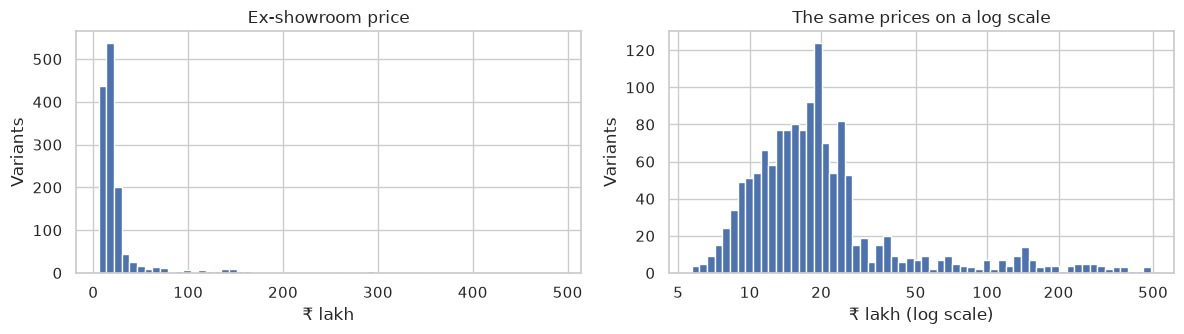

Middle (median) price: ₹17.67 lakh
Half of all variants cost between ₹12.61 lakh and ₹24.00 lakh


In [49]:
lakh_prices = variants_clean["ex_showroom_price"] / 1_00_000
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(lakh_prices, bins=60, color="#4C72B0")
axes[0].set_title("Ex-showroom price")
axes[0].set_xlabel("₹ lakh")
axes[1].hist(np.log10(lakh_prices), bins=60, color="#4C72B0")
axes[1].set_title("The same prices on a log scale")
axes[1].set_xlabel("₹ lakh (log scale)")
ticks = [5, 10, 20, 50, 100, 200, 500]
axes[1].set_xticks(np.log10(ticks), [str(t) for t in ticks])
for ax in axes:
    ax.set_ylabel("Variants")
plt.tight_layout()
plt.show()
print(f"Middle (median) price: {lakh(variants_clean['ex_showroom_price'].median())}")
print(f"Half of all variants cost between {lakh(variants_clean['ex_showroom_price'].quantile(0.25))} and {lakh(variants_clean['ex_showroom_price'].quantile(0.75))}")

On the normal scale, almost everything is squeezed into the left edge, with a long tail of luxury cars. On a log scale, the shape is much more even.

**Why the model uses log price:** prices go from ₹5.7 lakh to ₹4.9 crore. On a log scale, a 10% difference looks the same for a cheap car and an expensive one. So the model works with **percentage** differences, e.g. "a sunroof adds about 4%", rather than one rupee amount that can't fit both a ₹6 lakh car and a ₹2 crore car.

### 3.2 Price by brand

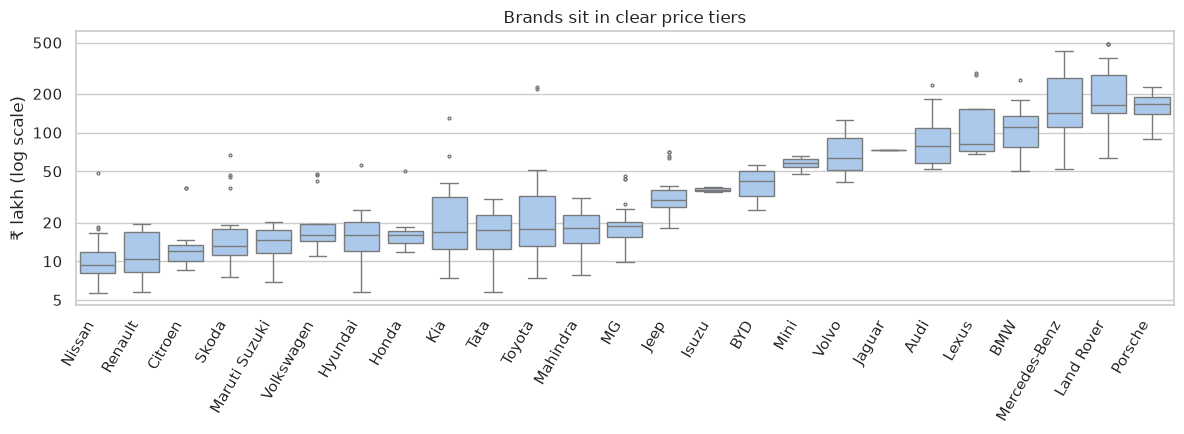

Brands with a median price below ₹20 lakh: 13  (Nissan, Renault, Citroen, Skoda, Maruti Suzuki, Volkswagen, Hyundai, Honda, Kia, Tata, Toyota, Mahindra, MG)
Brands between ₹20 and ₹50 lakh:            3  (Jeep, Isuzu, BYD)
Brands above ₹50 lakh:                      9  (Mini, Volvo, Jaguar, Audi, Lexus, BMW, Mercedes-Benz, Land Rover, Porsche)


In [50]:
brand_order = variants_clean.groupby("company")["ex_showroom_price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=variants_clean.assign(price_lakh=lakh_prices), x="company", y="price_lakh",
            order=brand_order, color="#A1C9F4", fliersize=2, ax=ax)
ax.set_yscale("log")
ax.set_yticks(ticks, [str(t) for t in ticks])
ax.set_xlabel("")
ax.set_ylabel("₹ lakh (log scale)")
ax.set_title("Brands sit in clear price tiers")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()
brand_median = variants_clean.groupby("company")["ex_showroom_price"].median() / 1_00_000
print(f"Brands with a median price below ₹20 lakh: {(brand_median < 20).sum()}  ({', '.join(brand_median[brand_median < 20].sort_values().index)})")
print(f"Brands between ₹20 and ₹50 lakh:            {brand_median.between(20, 50).sum()}  ({', '.join(brand_median[brand_median.between(20, 50)].sort_values().index)})")
print(f"Brands above ₹50 lakh:                      {(brand_median > 50).sum()}  ({', '.join(brand_median[brand_median > 50].sort_values().index)})")

Brands fall into clear tiers: 13 mass-market brands with a median price below ₹20 lakh, 3 in between (Jeep, Isuzu, BYD), and 9 luxury brands above ₹50 lakh. Brand alone explains a large part of price, so the model has to take brand into account. Otherwise every feature that luxury cars happen to have would look hugely valuable.

### 3.3 How often each feature is known

A feature can only go into the price model if it's known for most variants. The candidates are the clean number columns, the categories and the `has_…` columns from Step 2.

In [51]:
NUMBER_COLUMNS = ["power_bhp", "torque_nm", "engine_cc", "cylinders", "length_mm", "width_mm", "height_mm", "wheelbase_mm",
                  "ground_clearance_mm", "boot_litres", "seats", "touchscreen_in", "cluster_in", "speakers", "airbags",
                  "wheel_in", "battery_kwh", "range_km", "mileage_kmpl", "fuel_tank_l", "top_speed_kmph", "accel_0_100_s", "gears"]
CATEGORY_COLUMNS = ["fuel_type", "gearbox_type", "hybrid_type", "drive", "sunroof", "upholstery", "electric_seats",
                    "parking_sensors", "boot_opening"]
HAS_COLUMNS = [c for c in variants_clean.columns if c.startswith("has_")]

known = variants_clean[NUMBER_COLUMNS + CATEGORY_COLUMNS + HAS_COLUMNS].notna().mean()
print(f"Candidate columns: {len(known)}")
print(f"Known for at least 50% of variants: {(known >= 0.5).sum()}")
print("\nNumber columns, share known:")
print(known[NUMBER_COLUMNS].sort_values(ascending=False).round(2).to_string())

Candidate columns: 212
Known for at least 50% of variants: 106

Number columns, share known:
seats                  1.00
length_mm              1.00
width_mm               1.00
height_mm              1.00
airbags                0.99
power_bhp              0.99
torque_nm              0.99
wheelbase_mm           0.99
touchscreen_in         0.96
speakers               0.95
gears                  0.93
wheel_in               0.92
engine_cc              0.87
cylinders              0.87
boot_litres            0.83
cluster_in             0.81
fuel_tank_l            0.79
mileage_kmpl           0.49
ground_clearance_mm    0.41
top_speed_kmph         0.24
accel_0_100_s          0.17
range_km               0.13
battery_kwh            0.13


Most number columns are known for over 80% of variants. Four are not, for clear reasons:
- **Ground clearance (41%), mileage (49%), top speed and 0-100 km/h:** CarDekho lists them for only some models.
- **Battery and range (13%):** they only apply to EVs, which are 13% of variants.

Mileage would be useful to buyers, but at 49% it can't go into the price model. Battery size is a special case: it's known for every EV, so it can be used for EVs only.

`hybrid_type` is mostly empty by design: only hybrids have one. Every category column except it is known for at least 70% of variants:

In [52]:
print(known[CATEGORY_COLUMNS].round(2).to_string())

fuel_type          1.00
gearbox_type       1.00
hybrid_type        0.03
drive              1.00
sunroof            0.85
upholstery         0.93
electric_seats     0.71
parking_sensors    1.00
boot_opening       0.74


### 3.4 Features that hardly change

A YES/NO feature that almost every car has, or almost none has, can't explain price differences. We keep `has_…` columns that are known for at least 50% of variants **and** are YES for between 5% and 95% of the variants where they're known.

In [53]:
share_yes = variants_clean[HAS_COLUMNS].mean()
has_table = pd.DataFrame({"known": known[HAS_COLUMNS], "share_yes": share_yes}).round(2)
has_table["passes"] = (has_table["known"] >= 0.5) & has_table["share_yes"].between(0.05, 0.95)
print(f"has_ columns: {len(has_table)}")
print(f"... known for under 50%:               {(has_table['known'] < 0.5).sum()}")
print(f"... known, but YES for over 95% or under 5%: {((has_table['known'] >= 0.5) & ~has_table['passes']).sum()}")
print(f"... pass both rules:                   {has_table['passes'].sum()}")
print("\nKnown, but YES for over 95% of variants:",
      ", ".join(has_table[(has_table["known"] >= 0.5) & (has_table["share_yes"] > 0.95)].index))

has_ columns: 180
... known for under 50%:               98
... known, but YES for over 95% or under 5%: 25
... pass both rules:                   57

Known, but YES for over 95% of variants: has_keyless_entry, has_accessory_power_outlet, has_adjustable_headlamps, has_adjustable_headrest, has_air_conditioner, has_anti_theft_alarm, has_anti_lock_braking_system_abs, has_bluetooth_connectivity, has_brake_assist, has_central_locking, has_child_safety_locks, has_driver_airbag, has_electronic_brakeforce_distribution_ebd, has_electronic_stability_control_esc, has_engine_immobilizer, has_glove_box, has_heater, has_hill_assist, has_isofix_child_seat_mounts, has_passenger_airbag, has_power_steering, has_radio, has_rear_ac_vents, has_side_airbag, has_touchscreen


The features that almost every car has are basics: ABS, airbags for driver and passenger, ISOFIX child-seat mounts, power steering, air conditioning. They're on the variant page, but they can't explain why one variant costs more than another.

### 3.5 Features that move together

If two features almost always come together, the model can't tell their effects apart, so we keep one from each group. We look for pairs with a correlation above 0.85 among the features that passed so far. Correlation measures how closely two columns move together, from 0 (not at all) to 1 (always together).

In [54]:
passing_has = has_table.index[has_table["passes"]].tolist()
NUMBERS_TO_CHECK = ["power_bhp", "torque_nm", "engine_cc", "length_mm", "width_mm", "height_mm", "wheelbase_mm",
                    "boot_litres", "seats", "touchscreen_in", "cluster_in", "speakers", "airbags", "wheel_in", "fuel_tank_l"]
corr = variants_clean[NUMBERS_TO_CHECK + passing_has].corr()

# Join features into groups: any pair above 0.85 goes in the same group.
groups = {c: {c} for c in corr.columns}
for a, b in itertools.combinations(corr.columns, 2):
    if abs(corr.loc[a, b]) > 0.85 and groups[a] is not groups[b]:
        merged = groups[a] | groups[b]
        for c in merged:
            groups[c] = merged
together = {frozenset(g) for g in groups.values() if len(g) > 1}
for g in sorted(together, key=len, reverse=True):
    print(sorted(g))

['has_adaptive_high_beam_assist', 'has_adas', 'has_automatic_emergency_braking', 'has_blind_spot_monitor', 'has_driver_attention_warning', 'has_forward_collision_warning', 'has_lane_departure_warning', 'has_lane_keep_assist']
['has_google_alexa_connectivity', 'has_live_location', 'has_over_the_air_ota_updates', 'has_remote_vehicle_status_check', 'has_sos']
['engine_cc', 'fuel_tank_l', 'power_bhp', 'torque_nm']
['has_rear_window_washer', 'has_rear_window_wiper']
['has_front_fog_lamps', 'has_led_fog_lamps']
['has_alloy_wheels', 'has_wheel_covers']
['has_android_auto', 'has_apple_carplay']
['length_mm', 'wheelbase_mm']
['has_electric_seats', 'has_ventilated_seats']


Nine groups. From each we keep the one buyers understand best:
- **ADAS:** emergency braking, collision warning, lane keeping, adaptive high beams, driver attention warning and blind-spot monitor come as one package. → keep **`has_adas`** (any ADAS).
- **Connected-car app:** live location, remote status check, over-the-air updates, Google/Alexa and SOS come together. → keep **`has_remote_vehicle_status_check`**, called "connected-car app" in the app.
- **Engine:** power, torque, engine size and fuel-tank size (bigger engines come with bigger tanks). → keep **`power_bhp`**.
- **Length and wheelbase.** → keep **`length_mm`**.
- **Alloy wheels and wheel covers:** these move in opposite directions, because covers go on steel wheels. → keep **`has_alloy_wheels`**.
- **Ventilated and electric seats.** → keep **`has_ventilated_seats`**.
- **Android Auto and Apple CarPlay:** both are on about 95% of cars. → keep neither; use **`has_wireless_phone_projection`** (the wireless version) instead.
- **Fog lamps:** front fog lamps and LED fog lamps. → keep **`has_front_fog_lamps`**.
- **Rear window:** rear wiper and rear washer. → keep neither, because both are basic.

### 3.6 Variants per model

In [55]:
per_model = variants_clean.groupby(["company", "model"]).size()
print(f"Models: {len(per_model)}")
print(f"Models with only one variant: {(per_model == 1).sum()}")
print(f"Models with 10 or more variants: {(per_model >= 10).sum()}")
single_price = variants_clean.groupby(["company", "model"])["ex_showroom_price"].median()[per_model == 1]
print(f"One-variant models priced above ₹40 lakh: {(single_price > 40_00_000).sum()} of {len(single_price)}")
print("\nMost variants:")
print(per_model.sort_values(ascending=False).head(5).to_string())

Models: 136
Models with only one variant: 30
Models with 10 or more variants: 45
One-variant models priced above ₹40 lakh: 29 of 30

Most variants:
company  model  
Tata     Nexon      82
         Safari     72
         Sierra     59
         Harrier    57
Hyundai  Creta      54


30 models have only one variant, so the Trim Picker has nothing to show for them. 29 of the 30 cost over ₹40 lakh: luxury models sold in one version. At the other end, mass-market models like the Tata Nexon (82 variants) have long trim ladders. Those are the buyers who need the Trim Picker most.

### 3.7 Price against a few key features

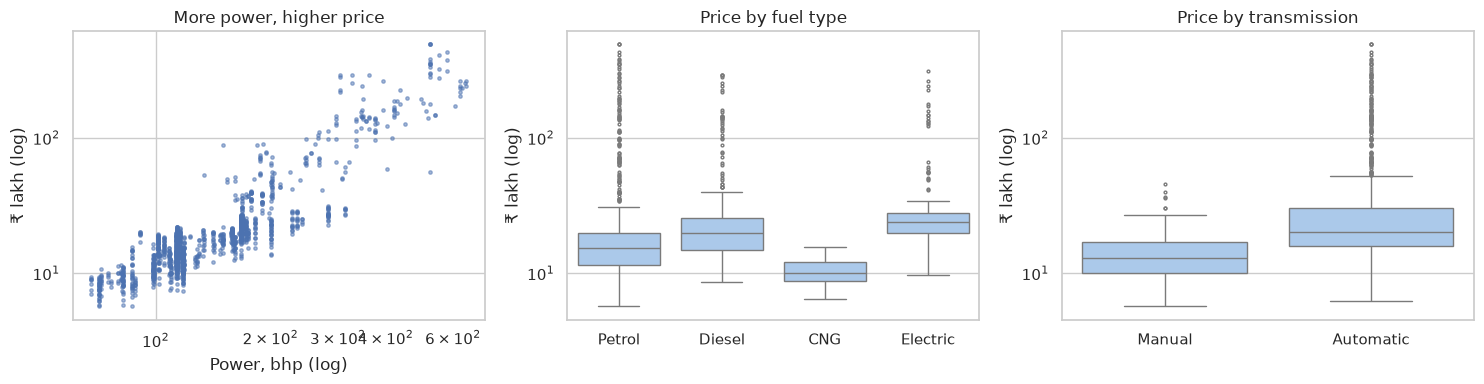

Correlation of log power with log price: 0.89
Median price by transmission: {'Automatic': '₹20.29 lakh', 'Manual': '₹13.04 lakh'}


In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data = variants_clean.assign(price_lakh=lakh_prices)
axes[0].scatter(data["power_bhp"], data["price_lakh"], s=6, alpha=0.5, color="#4C72B0")
axes[0].set(xscale="log", yscale="log", xlabel="Power, bhp (log)", ylabel="₹ lakh (log)", title="More power, higher price")
sns.boxplot(data=data, x="fuel_type", y="price_lakh", order=["Petrol", "Diesel", "CNG", "Electric"], color="#A1C9F4", fliersize=2, ax=axes[1])
axes[1].set(yscale="log", xlabel="", ylabel="₹ lakh (log)", title="Price by fuel type")
sns.boxplot(data=data, x="transmission", y="price_lakh", order=["Manual", "Automatic"], color="#A1C9F4", fliersize=2, ax=axes[2])
axes[2].set(yscale="log", xlabel="", ylabel="₹ lakh (log)", title="Price by transmission")
plt.tight_layout()
plt.show()
print(f"Correlation of log power with log price: {np.corrcoef(np.log(data['power_bhp'].dropna()), np.log(data.loc[data['power_bhp'].notna(), 'price_lakh']))[0, 1]:.2f}")
print("Median price by transmission:", data.groupby("transmission")["ex_showroom_price"].median().map(lakh).to_dict())

Power is the strongest single signal: on log scales it's close to a straight line (correlation 0.89). Automatics cost more than manuals, but part of that is because luxury cars are all automatic. The model in Step 4 separates the gearbox from everything else.

### 3.8 The two lists

**List 1: features for the price model (Step 4).** These are the features that passed 3.3–3.5, minus a few left out on purpose:
- small items that are on nearly every car anyway, such as LED tail-lights, rear spoiler and roof rails;
- features already covered by another one, e.g. Android Auto is covered by `has_wireless_phone_projection`.

Battery size is added for EVs only (3.3).

In [57]:
MODEL_FEATURES = {
    # numbers
    "power_bhp": "engine or motor power (stands for the engine group)",
    "length_mm": "size (stands for length and wheelbase)",
    "width_mm": "size",
    "height_mm": "size",
    "seats": "number of seats",
    "airbags": "number of airbags",
    "wheel_in": "wheel size",
    "touchscreen_in": "touchscreen size",
    "boot_litres": "boot space",
    "speakers": "number of speakers",
    "battery_kwh": "EV battery size (EVs only)",
    # categories
    "fuel_type": "petrol / diesel / CNG / electric",
    "hybrid_type": "mild / strong hybrid",
    "gearbox_type": "manual / AMT / CVT / DCT / torque-converter AT / hybrid",
    "drive": "2WD or 4x4/AWD",
    "sunroof": "none / single / panoramic",
    "upholstery": "fabric / leatherette / leather",
    # YES/NO features
    "has_adas": "ADAS package (stands for the ADAS group)",
    "has_360_view_camera": "360° camera",
    "has_ventilated_seats": "ventilated seats (stands for electric seats too)",
    "has_wireless_phone_charging": "wireless phone charging",
    "has_wireless_phone_projection": "wireless Android Auto / Apple CarPlay",
    "has_paddle_shifters": "paddle shifters",
    "has_cruise_control": "cruise control",
    "has_led_headlamps": "LED headlamps",
    "has_projector_headlamps": "projector headlamps",
    "has_automatic_headlamps": "automatic headlamps",
    "has_front_fog_lamps": "front fog lamps (stands for the fog-lamp group)",
    "has_digital_cluster": "fully digital instrument cluster",
    "has_rear_disc_brakes": "rear disc brakes",
    "has_turbo": "turbocharged engine",
    "has_automatic_climate_control": "automatic climate control",
    "has_air_quality_control": "air purifier",
    "has_rain_sensing_wiper": "rain-sensing wipers",
    "has_leather_wrapped_steering_wheel": "leather-wrapped steering wheel",
    "has_hill_descent_control": "hill descent control",
    "has_alloy_wheels": "alloy wheels",
    "has_remote_vehicle_status_check": "connected-car app (stands for the connected-car group)",
    "has_tyre_pressure_monitoring_system_tpms": "tyre pressure monitor",
    "has_rear_camera": "rear camera",
    "has_side_airbag_rear": "rear side airbags",
    "has_rear_seat_centre_arm_rest": "rear centre armrest",
    "has_engine_start_stop_button": "push-button start",
    "has_voice_commands": "voice commands",
}
model_list = pd.DataFrame({"reason / meaning": MODEL_FEATURES})
model_list["known"] = variants_clean[list(MODEL_FEATURES)].notna().mean().round(2)
print(f"Price-model features: {len(MODEL_FEATURES)}")
model_list

Price-model features: 44


,reason / meaning,known
power_bhp,engine or motor power (stands for the engine group),0.99
length_mm,size (stands for length and wheelbase),1.00
width_mm,size,1.00
height_mm,size,1.00
seats,number of seats,1.00
airbags,number of airbags,0.99
wheel_in,wheel size,0.92
touchscreen_in,touchscreen size,0.96
boot_litres,boot space,0.83
speakers,number of speakers,0.95


**List 2: options a buyer can tick in the Finder (Step 6),** written in plain words. Each option is a rule on the clean table. Only a confirmed YES counts, so unknown never shows as "has it" (Step 2.2).

In [58]:
v = variants_clean
FINDER_OPTIONS = {
    "Automatic": v["transmission"].eq("Automatic"),
    "Diesel": v["fuel_type"].eq("Diesel"),
    "Electric": v["fuel_type"].eq("Electric"),
    "CNG": v["fuel_type"].eq("CNG"),
    "Strong hybrid": v["hybrid_type"].eq("Strong"),
    "Any sunroof": v["has_sunroof"].eq(1),
    "Panoramic sunroof": v["sunroof"].eq("Panoramic"),
    "ADAS (automatic emergency braking)": v["has_automatic_emergency_braking"].eq(1),
    "Adaptive cruise control": v["has_adaptive_cruise_control"].eq(1),
    "Cruise control": v["has_cruise_control"].eq(1),
    "360° camera": v["has_360_view_camera"].eq(1),
    "7 or more seats": v["seats"].ge(7),
    "4x4 / AWD": v["drive"].eq("4x4/AWD"),
    "150+ bhp": v["power_bhp"].ge(150),
    "Ventilated seats": v["has_ventilated_seats"].eq(1),
    "Electric driver seat": v["electric_seats"].isin(["Driver only", "Front", "Front & Rear"]),
    "Leather or leatherette seats": v["upholstery"].isin(["Leather", "Leatherette"]),
    "Wireless phone charging": v["has_wireless_phone_charging"].eq(1),
    "Wireless Android Auto / Apple CarPlay": v["has_wireless_phone_projection"].eq(1),
    "6 or more airbags": v["airbags"].ge(6),
    "Automatic climate control": v["has_automatic_climate_control"].eq(1),
    "Digital instrument cluster": v["has_digital_cluster"].eq(1),
    "10-inch or bigger touchscreen": v["touchscreen_in"].ge(10),
    "LED headlamps": v["has_led_headlamps"].eq(1),
    "Alloy wheels": v["has_alloy_wheels"].eq(1),
    "Rear disc brakes": v["has_rear_disc_brakes"].eq(1),
    "Paddle shifters": v["has_paddle_shifters"].eq(1),
    "Heads-up display": v["has_heads_up_display_hud"].eq(1),
    "Powered or hands-free boot": v["boot_opening"].isin(["Powered", "Hands-free"]),
    "400+ litre boot": v["boot_litres"].ge(400),
    "Front parking sensors": v["parking_sensors"].eq("Front & Rear"),
    "5-star crash rating (Bharat or Global NCAP)": v["bharat_ncap_stars"].eq(5) | v["global_ncap_stars"].eq(5),
}
finder_flags = pd.DataFrame({name: np.asarray(rule, dtype=bool) for name, rule in FINDER_OPTIONS.items()})
finder_summary = pd.DataFrame({"variants with it": finder_flags.sum(), "share": finder_flags.mean().round(2)})
print(f"Finder options: {len(FINDER_OPTIONS)}")
finder_summary.sort_values("share", ascending=False)

Finder options: 32


,variants with it,share
6 or more airbags,1354,0.97
Digital instrument cluster,1168,0.83
Automatic climate control,1160,0.83
LED headlamps,1107,0.79
Cruise control,1111,0.79
10-inch or bigger touchscreen,990,0.71
Any sunroof,945,0.68
Rear disc brakes,935,0.67
Automatic,846,0.60
Wireless phone charging,839,0.60


**Result of Step 3:**
- **Prices** are modelled on a log scale, so the model works with percentage differences.
- **Brand** must be in the model.
- **44 features** go into the price model. Each passed the coverage (3.3), variation (3.4) and overlap (3.5) checks, or is a deliberate special case (battery size for EVs).
- **32 plain-word options** are ready for the Finder.
- **Mileage and ground clearance** are left out of the model, because they're known for under half the variants. The variant page still shows them where known.

## Step 4: Fair Price research

**Why the app needs this:** the Fair Price page shows three things:
1. what each feature adds to the price;
2. whether a variant is fairly priced for what it offers;
3. similar variants that are better value.

The Trim Picker (Step 5) also uses the feature prices from here.

The parts:
- **4a** builds the price model.
- **4b** tests it fairly.
- **4c** turns it into feature prices.
- **4d** sets the "overpriced / fair / good value" badge.
- **4e** finds similar cars.

### 4a. Build the price model

**What we predict:** log(ex-showroom price). We use the ex-showroom price rather than on-road, because on-road adds Delhi taxes and insurance, which have nothing to do with the car's features.

**Which variants:** Step 1 flagged 4 variants that list very few features. How many of the 44 model features do they have?

In [59]:
model_data = variants_clean.copy()
model_data["model_id"] = model_data["company"] + " " + model_data["model"]
share_known = model_data[list(MODEL_FEATURES)].notna().mean(axis=1)

print(model_data.loc[model_data["few_features"], KEY].assign(model_features_known=share_known[model_data["few_features"]].round(2)).to_string())
print(f"\nAll other variants: median share of model features known = {share_known[~model_data['few_features']].median():.2f}")

         company             model                          variant  model_features_known
1335  Land Rover         Discovery           3.0 Diesel Dynamic HSE                  0.25
1336  Land Rover         Discovery  3.0 Diesel Metropolitan Edition                  0.25
1386     Porsche  Cayenne Electric                         Standard                  0.18
1387     Porsche  Cayenne Electric                            Turbo                  0.18

All other variants: median share of model features known = 0.84


Those 4 variants are missing most of the model's features, so their price would be explained by guesses. **Decision:** leave them out when fitting the model. The app shows "not enough data" instead of a badge for them.

In [60]:
fit = model_data[~model_data["few_features"]].reset_index(drop=True)
y = np.log(fit["ex_showroom_price"].to_numpy())
groups = fit["model_id"]
print(f"Variants used to fit the model: {len(fit):,} from {groups.nunique()} models")

Variants used to fit the model: 1,395 from 135 models


**Turning the features into model columns.** Categories become 0/1 columns, e.g. `fuel_diesel` = 1 for diesel cars, with petrol as the baseline. Power goes in as log(power), so a 10% increase means the same for a small car and a big one.

**Unknown values.** A model can't use empty values, so we fill them, and we say how:
1. **A gap inside a model** gets the average of that model's other variants. CarDekho lists features per model (Step 2.2), so a variant's siblings are the best guide.
2. **A whole-model gap** gets the average of all variants, plus an `…_unknown` flag column (1 = this value was filled in). That lets the model tell a filled-in value from a real one. Flags are added for features unknown for over 5% of variants.

In [61]:
GEARBOXES = ["AMT", "CVT", "DCT", "Torque-converter AT", "Automatic, type not listed", "Hybrid"]
NUMBER_INPUTS = ["length_mm", "width_mm", "height_mm", "seats", "airbags", "wheel_in", "touchscreen_in", "boot_litres", "speakers"]
YES_NO_INPUTS = [c for c in MODEL_FEATURES if c.startswith("has_") and c != "has_sunroof"]

def make_features(df):
    """Turn clean columns into model columns (one row per variant)."""
    X = pd.DataFrame(index=df.index)
    X["log_power"] = np.log(df["power_bhp"])
    for c in NUMBER_INPUTS:
        X[c] = df[c]
    X["ev_battery_kwh"] = df["battery_kwh"].where(df["fuel_type"].eq("Electric"), 0)
    for fuel in ["Diesel", "CNG", "Electric"]:
        X[f"fuel_{fuel.lower()}"] = df["fuel_type"].eq(fuel).astype(float)
    for hybrid in ["Mild", "Strong"]:
        X[f"hybrid_{hybrid.lower()}"] = df["hybrid_type"].eq(hybrid).astype(float)
    for g in GEARBOXES:
        X[f"gearbox_{snake(g)}"] = df["gearbox_type"].eq(g).astype(float)
    X["drive_4x4"] = df["drive"].eq("4x4/AWD").astype(float).where(df["drive"].notna())
    X["has_sunroof"] = df["has_sunroof"]
    X["panoramic_sunroof"] = df["sunroof"].eq("Panoramic").astype(float).where(df["sunroof"].notna() & df["sunroof"].ne("Yes, type not listed"))
    X["leatherette"] = df["upholstery"].eq("Leatherette").astype(float).where(df["upholstery"].notna())
    X["leather"] = df["upholstery"].eq("Leather").astype(float).where(df["upholstery"].notna())
    for c in YES_NO_INPUTS:
        X[c] = df[c]
    return X

def fill_unknowns(X, groups, overall_mean):
    """Gap inside a model -> that model's average; whole-model gap -> overall average + an _unknown flag."""
    unknown = X.isna()
    filled = X.groupby(groups.to_numpy()).transform("mean").where(unknown, X)
    filled = filled.fillna(overall_mean)
    flag_columns = unknown.columns[unknown.mean() > 0.05]
    flags = unknown[flag_columns].astype(float).add_suffix("_unknown")
    return filled, flags

X_raw = make_features(fit)
X_filled, X_flags = fill_unknowns(X_raw, groups, X_raw.mean())
print(f"Model columns: {X_filled.shape[1]} feature columns + {X_flags.shape[1]} unknown flags")

Model columns: 54 feature columns + 28 unknown flags


**Check for features that move together (VIF).** The VIF (variance inflation factor) measures how well a column can be predicted from all the others. Above 10 means the model can't separate its effect from the rest.

In [62]:
def vif_table(X):
    Z = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Z.to_numpy(), i) for i in range(1, Z.shape[1])], index=X.columns).sort_values(ascending=False)

print(vif_table(X_filled).head(6).round(1).to_string())

fuel_electric     13.5
ev_battery_kwh    12.6
log_power          9.1
length_mm          7.8
width_mm           4.6
speakers           4.1


Two columns are above 10: `fuel_electric` and `ev_battery_kwh`. That's expected: battery size is non-zero only for EVs, so the two columns say almost the same thing, "this is an EV".

**Fix:** measure the battery **relative to the average EV** (e.g. +10 kWh = 10 kWh bigger than average). Then `fuel_electric` carries "is an EV" and the battery column carries "how big a battery", and the two no longer overlap.

In [63]:
EV_BATTERY_AVERAGE = fit.loc[fit["fuel_type"].eq("Electric"), "battery_kwh"].mean()

def make_model_columns(df, groups, overall_mean=None):
    X = make_features(df)
    X["ev_battery_kwh"] = (X["ev_battery_kwh"] - EV_BATTERY_AVERAGE).where(df["fuel_type"].eq("Electric"), 0)
    filled, flags = fill_unknowns(X, groups, X.mean() if overall_mean is None else overall_mean)
    return filled, flags

X_filled, X_flags = make_model_columns(fit, groups)
FILL_MEANS = make_features(fit).assign(
    ev_battery_kwh=lambda X: (X["ev_battery_kwh"] - EV_BATTERY_AVERAGE).where(fit["fuel_type"].eq("Electric"), 0)).mean()
print(f"Average EV battery: {EV_BATTERY_AVERAGE:.1f} kWh\n")
print(vif_table(X_filled).head(5).round(1).to_string())

Average EV battery: 63.4 kWh



log_power    9.1
length_mm    7.8
width_mm     4.6
speakers     4.1
wheel_in     3.9


All VIFs are now below 10.

**Two versions of the model** (from the plan):
- **Version 1: brand + features.** It compares cars across the whole market. Brand is included because Step 3.2 showed brands sit in price tiers. Without brand, features that luxury cars happen to have would look hugely valuable. Version 1 gives the **fair price**.
- **Version 2: model + features.** It compares variants **of the same model** with each other, e.g. Creta vs Creta. The cars are otherwise identical, so this is the cleanest answer to "what does a sunroof add?". Version 2 gives the **feature prices**.

### 4b. Test the model fairly

We use **5-fold cross-validation**: split the data into 5 parts, train on 4 and test on the 5th, five times over. Every variant gets a price estimate from a model that never saw it.

**All variants of one model stay in the same part** (`GroupKFold`). Variants of one model are near-copies, so if some Nexon variants were in training and others in testing, the test would be far too easy. The comparison below shows how much easier.

In [64]:
group_folds = list(GroupKFold(n_splits=5).split(X_filled, y, groups=groups))
random_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(X_filled))
brands = pd.get_dummies(fit["company"], prefix="brand", dtype=float)

def out_of_fold(estimator, X, folds):
    """Price estimate for every variant from a model trained without it (log scale)."""
    pred = np.zeros(len(y))
    for train, test in folds:
        estimator.fit(X.iloc[train], y[train])
        pred[test] = estimator.predict(X.iloc[test])
    return pred

def errors(name, pred):
    pct_error = np.exp(pred - y) - 1   # estimate vs real price
    return {"model": name, "typical error": f"{np.median(np.abs(pct_error)):.1%}",
            "within ±10%": f"{np.mean(np.abs(pct_error) <= 0.10):.0%}",
            "within ±20%": f"{np.mean(np.abs(pct_error) <= 0.20):.0%}"}

X_v1 = pd.concat([X_filled, X_flags, brands], axis=1)
baseline_cols = ["log_power", "fuel_diesel", "fuel_cng", "fuel_electric", "seats"] + list(brands.columns)

lasso_search = make_pipeline(StandardScaler(), LassoCV(cv=group_folds, alphas=50, max_iter=50_000)).fit(X_v1, y)
LASSO_ALPHA = lasso_search[-1].alpha_
lasso = make_pipeline(StandardScaler(), Lasso(alpha=LASSO_ALPHA, max_iter=50_000))

pred_baseline = out_of_fold(LinearRegression(), X_v1[baseline_cols], group_folds)
pred_ols = out_of_fold(LinearRegression(), X_v1, group_folds)
pred_lasso = out_of_fold(lasso, X_v1, group_folds)
pred_lasso_random = out_of_fold(lasso, X_v1, random_folds)
X_boost = pd.concat([make_features(fit), brands], axis=1)   # boosting handles empty values itself
pred_boost = out_of_fold(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_SEED), X_boost, group_folds)

pd.DataFrame([
    errors("Baseline: power, fuel, seats, brand (plain regression)", pred_baseline),
    errors("Version 1, all features (plain regression)", pred_ols),
    errors("Version 1, all features (Lasso)", pred_lasso),
    errors("Gradient boosting, all features", pred_boost),
    errors("Version 1 Lasso, but tested with random folds (too easy)", pred_lasso_random),
])

,model,typical error,within ±10%,within ±20%
0,"Baseline: power, fuel, seats, brand (plain regression)",16.9%,33%,57%
1,"Version 1, all features (plain regression)",12.6%,40%,74%
2,"Version 1, all features (Lasso)",9.0%,54%,83%
3,"Gradient boosting, all features",8.7%,55%,77%
4,"Version 1 Lasso, but tested with random folds (too easy)",5.6%,73%,93%


**Typical error** is the middle error: half of the estimates are closer than this, half further away.
- The **baseline** gets within ±20% for about half of the variants.
- **Adding all features** helps, and **Lasso** helps further. Lasso shrinks unhelpful columns to zero, which stops the model chasing noise in models it hasn't seen.
- **Gradient boosting** is a far more flexible model, but it isn't better overall: its typical error is slightly smaller, but fewer of its estimates are within ±20%.
- **Random folds** make the typical error look much smaller (5.6% instead of 9.0%). That gap is how much near-copy variants would flatter the result, so the honest numbers are the grouped ones.

In [65]:
kept = pd.Series(lasso_search[-1].coef_, index=X_v1.columns)
print(f"Lasso strength chosen by cross-validation: {LASSO_ALPHA:.4f}")
print(f"Columns kept: {(kept != 0).sum()} of {len(kept)}")
print("Dropped feature columns (not flags or brands):", ", ".join(c for c in kept.index[kept == 0] if not c.endswith("_unknown") and not c.startswith("brand_")))

Lasso strength chosen by cross-validation: 0.0043
Columns kept: 71 of 107
Dropped feature columns (not flags or brands): width_mm, boot_litres, ev_battery_kwh, fuel_electric, has_sunroof, leatherette, has_adas, has_ventilated_seats, has_cruise_control, has_digital_cluster, has_turbo, has_air_quality_control, has_leather_wrapped_steering_wheel, has_voice_commands


Many dropped columns overlap with something kept, e.g. sunroof with panoramic sunroof, or ADAS with the 360° camera. That's how Lasso deals with overlap: it keeps one and drops the rest, which is fine for predicting.

**What does the complex model see?** SHAP values show how much each column moves the boosting model's estimate. Below is the average size of that push per column, for the 15 strongest:

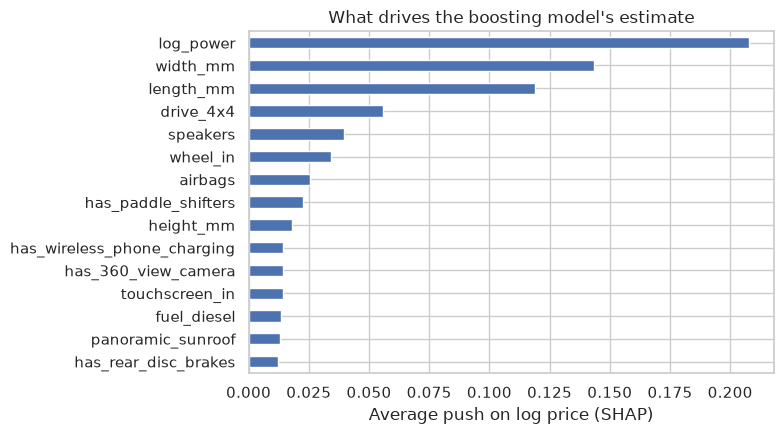

In [66]:
booster = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_SEED).fit(X_boost, y)
shap_values = shap.TreeExplainer(booster).shap_values(X_boost)
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_boost.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 4.5))
importance[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Average push on log price (SHAP)")
ax.set_title("What drives the boosting model's estimate")
plt.tight_layout()
plt.show()

The boosting model leans on the same things as the linear model: power, size, brand and the big features. It finds no hidden pattern that the simple model misses, which is why it isn't more accurate.

**Decision:** use **Version 1 with Lasso** for the fair price. It's as accurate as the complex model, and it can show a clear, explainable price for each feature, which the app needs. Boosting goes into "tried and not used" (Step 7).

### 4c. Turn the model into feature prices

For feature prices we use **Version 2**: compare variants of the same model. In practice we subtract each model's average from its variants, for both price and features ("demeaning"). What's left is how each variant differs from its siblings.

Some features are the same for every variant of a model, e.g. length, or being an EV. Those drop out, because Version 2 can't price what never changes within a model. That's fine: the Trim Picker only needs features that change between trims.

In [67]:
TRIM_COLUMNS = [c for c in X_filled.columns if c not in ["length_mm", "width_mm", "height_mm", "boot_litres"]]
demeaned_X = X_filled[TRIM_COLUMNS] - X_filled[TRIM_COLUMNS].groupby(groups.to_numpy()).transform("mean")
demeaned_y = y - pd.Series(y).groupby(groups.to_numpy()).transform("mean").to_numpy()

changes_within = demeaned_X.columns[(demeaned_X.abs() > 1e-9).any()]
print("Never change within a model (dropped):", ", ".join(sorted(set(TRIM_COLUMNS) - set(changes_within))))

trim_lasso = make_pipeline(StandardScaler(), LassoCV(cv=group_folds, alphas=50, max_iter=50_000)).fit(demeaned_X[changes_within], demeaned_y)
TRIM_FEATURES = [c for c, b in zip(changes_within, trim_lasso[-1].coef_) if b != 0]
print(f"\nColumns that change within models: {len(changes_within)}; kept by Lasso: {len(TRIM_FEATURES)}")
print("Dropped by Lasso:", ", ".join(c for c in changes_within if c not in TRIM_FEATURES))

within_ols = sm.OLS(demeaned_y, demeaned_X[TRIM_FEATURES]).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
print(f"\nShare of within-model price differences explained (R²): {within_ols.rsquared:.2f}")

Never change within a model (dropped): fuel_electric, has_side_airbag_rear, hybrid_mild

Columns that change within models: 47; kept by Lasso: 41
Dropped by Lasso: airbags, has_wireless_phone_projection, has_projector_headlamps, has_rain_sensing_wiper, has_leather_wrapped_steering_wheel, has_voice_commands

Share of within-model price differences explained (R²): 0.87


Features explain most of the price differences between trims of the same model.

**Turning numbers into prices.** On a log scale, a coefficient `b` means the feature multiplies the price by `e^b`, i.e. adds `(e^b − 1) × 100`%. For power, we show the effect of 10% more power. For counts (airbags, speakers, inches of screen or wheel), the effect is per extra unit.

**How sure are we? (bootstrap)** We refit the model 1,000 times. Each time we use whole models picked at random (some twice, some not at all), never single variants. The middle 95% of the 1,000 results is the likely range.

In [68]:
model_codes = pd.factorize(groups)[0]
rows_of_model = [np.where(model_codes == m)[0] for m in range(model_codes.max() + 1)]
A, b_target = demeaned_X[TRIM_FEATURES].to_numpy(), demeaned_y

boot_rng = np.random.default_rng(RANDOM_SEED)
boot_coefs = []
for _ in range(1000):
    picked = boot_rng.integers(0, len(rows_of_model), len(rows_of_model))
    rows = np.concatenate([rows_of_model[m] for m in picked])
    boot_coefs.append(np.linalg.lstsq(A[rows], b_target[rows], rcond=None)[0])
boot_coefs = np.array(boot_coefs)

def as_percent(column, coef):
    """Price effect in % for one unit (10% more for power)."""
    return (1.1 ** coef - 1) if column == "log_power" else (np.exp(coef) - 1)

MEDIAN_PRICE = fit["ex_showroom_price"].median()
feature_prices = pd.DataFrame({
    "column": TRIM_FEATURES,
    "pct_added": [as_percent(c, b) for c, b in zip(TRIM_FEATURES, within_ols.params)],
    "low_pct": [as_percent(c, np.percentile(boot_coefs[:, i], 2.5)) for i, c in enumerate(TRIM_FEATURES)],
    "high_pct": [as_percent(c, np.percentile(boot_coefs[:, i], 97.5)) for i, c in enumerate(TRIM_FEATURES)],
})
feature_prices["rupees_at_median_price"] = (feature_prices["pct_added"] * MEDIAN_PRICE).round(-2)
feature_prices["clear"] = (feature_prices["low_pct"] > 0) | (feature_prices["high_pct"] < 0)
print(f"Median price used for rupee amounts: {lakh(MEDIAN_PRICE)}")
feature_prices.sort_values("pct_added", ascending=False).assign(
    pct_added=lambda d: d["pct_added"].map("{:+.1%}".format),
    low_pct=lambda d: d["low_pct"].map("{:+.1%}".format),
    high_pct=lambda d: d["high_pct"].map("{:+.1%}".format)).reset_index(drop=True)

Median price used for rupee amounts: ₹17.60 lakh


,column,pct_added,low_pct,high_pct,rupees_at_median_price,clear
0,gearbox_hybrid,+17.6%,-2.8%,+24.4%,310100.0,False
1,fuel_cng,+13.4%,+9.4%,+18.4%,235400.0,True
2,gearbox_torque_converter_at,+10.3%,+7.7%,+12.2%,180700.0,True
3,gearbox_cvt,+9.7%,+6.2%,+13.4%,171500.0,True
4,drive_4x4,+8.1%,+3.8%,+11.6%,141900.0,True
5,hybrid_strong,+8.0%,-0.0%,+16.9%,140500.0,False
6,gearbox_automatic_type_not_listed,+7.5%,+5.2%,+9.7%,132100.0,True
7,fuel_diesel,+6.8%,+5.2%,+9.1%,119600.0,True
8,has_engine_start_stop_button,+6.1%,+2.9%,+8.0%,106600.0,True
9,gearbox_dct,+5.9%,+2.8%,+9.2%,103400.0,True


**Do the results make sense?**
- The biggest clear effects are what you'd expect from trim ladders: CNG (+13%), every kind of automatic gearbox (+5% to +10%), 4x4 (+8%) and diesel (+7%).
- Push-button start (+6%) is surprisingly large. It's likely standing in for the step from a base trim to the next one, which brings several upgrades CarDekho doesn't list separately.
- Comfort and tech features each add a few percent. Rupee amounts are for a car at the median price; in the app they're scaled to the selected car's own price.
- Features whose range includes zero are marked `clear = False`. The data can't tell their price apart from nothing, so **the app won't show a price for them**. The only negative estimate (one more seat, −0.7%) is in this group.
- Is any estimate clearly negative? That would need a closer look:

In [69]:
clear_negative = feature_prices[feature_prices["clear"] & (feature_prices["pct_added"] < 0)]
print(clear_negative[["column", "pct_added", "low_pct", "high_pct"]].round(3).to_string(index=False) if len(clear_negative) else "None")

None


In [70]:
LABELS = {
    "log_power": "10% more power", "seats": "one more seat", "airbags": "one more airbag", "wheel_in": "one inch bigger wheels",
    "touchscreen_in": "one inch bigger touchscreen", "speakers": "one more speaker", "ev_battery_kwh": "1 kWh bigger EV battery",
    "fuel_diesel": "diesel engine (vs petrol)", "fuel_cng": "CNG (vs petrol)", "hybrid_mild": "mild hybrid", "hybrid_strong": "strong hybrid",
    "drive_4x4": "4x4 / AWD", "has_sunroof": "sunroof", "panoramic_sunroof": "panoramic (vs single) sunroof",
    "leatherette": "leatherette seats (vs fabric)", "leather": "leather seats (vs fabric)",
    **{f"gearbox_{snake(g)}": f"{g} gearbox (vs manual)" for g in GEARBOXES},
    **{c: MODEL_FEATURES[c] for c in YES_NO_INPUTS},
}
feature_prices["label"] = feature_prices["column"].map(LABELS)
feature_prices["shown_in_app"] = feature_prices["clear"] & (feature_prices["pct_added"] > 0)
print(f"Feature prices: {len(feature_prices)}; clear enough to show in the app: {feature_prices['shown_in_app'].sum()}")

Feature prices: 41; clear enough to show in the app: 17


### 4d. Decide "overpriced / fair / good value"

Each variant's **fair price** is the model's estimate from the cross-validation in 4b. It comes from a model that never saw the variant or any of its siblings, so no car is judged by a model that already knows its price.

First, the extremes from the Version 1 Lasso model as it stands:

In [71]:
def show_extremes(d, n=10):
    show = lambda part: part[KEY].assign(price=part["ex_showroom_price"].map(lakh), fair=part["fair_price"].map(lakh),
                                         difference=part["difference_pct"].map("{:+.0%}".format))
    print("Most overpriced:")
    print(show(d.nlargest(n, "difference_pct")).to_string(index=False))
    print("\nBest value:")
    print(show(d.nsmallest(n, "difference_pct")).to_string(index=False))

fit["fair_price"] = np.exp(pred_lasso)
fit["difference_pct"] = fit["ex_showroom_price"] / fit["fair_price"] - 1   # + = costs more than its features suggest
show_extremes(fit)

Most overpriced:
      company            model                         variant        price         fair difference
Mercedes-Benz          G-Class    AMG G 63 Collector's Edition ₹430.00 lakh ₹184.82 lakh      +133%
   Land Rover      Range Rover 4.4L SV Sawai Jaisalmer Edition ₹490.00 lakh ₹211.94 lakh      +131%
   Land Rover      Range Rover   4.4L SV Sawai Jodhpur Edition ₹490.00 lakh ₹211.94 lakh      +131%
       Toyota Land Cruiser 300                            GR-S ₹224.93 lakh ₹102.44 lakh      +120%
       Nissan          X-Trail                             STD  ₹48.20 lakh  ₹22.16 lakh      +118%
        Lexus               LX                  500d Overtrail ₹292.66 lakh ₹137.62 lakh      +113%
Mercedes-Benz      Maybach GLS         600 Celebration Edition ₹410.00 lakh ₹193.01 lakh      +112%
   Land Rover      Range Rover    4.4L SV Sawai Jaipur Edition ₹490.00 lakh ₹235.99 lakh      +108%
       Toyota Land Cruiser 300                              ZX ₹217.75 lakh ₹107.10

**Checking these by hand shows a problem the error numbers in 4b didn't.** The whole best-value list is Nissan: every Magnite and Tekton variant comes out about 50% below its fair price. Meanwhile, Nissan's third model, the X-Trail, is among the most overpriced. A whole brand being half price is not believable. Is it a brand effect? Below is the middle difference per brand, with each brand's number of models:

In [72]:
brand_check = (fit.groupby("company")
               .agg(models=("model", "nunique"), median_difference=("difference_pct", "median"))
               .sort_values("median_difference"))
print(pd.concat([brand_check.head(4), brand_check.tail(4)]).assign(median_difference=lambda d: d["median_difference"].map("{:+.0%}".format)).to_string())

               models median_difference
company                                
Nissan              3              -45%
Honda               2              -25%
Lexus               3              -20%
Renault             2              -12%
Mercedes-Benz      11              +10%
Audi                7              +12%
Land Rover          7              +28%
Jaguar              1              +36%


The brands at both ends have **few models, and very different ones**. Nissan's 3 models are two cheap compact SUVs (Magnite, Tekton) and one expensive import (X-Trail).

Remember how the test works: all variants of a model are held out together. When the Magnite is held out, the model learns what "Nissan" means from the Tekton and the X-Trail alone, so it expects a Nissan to be expensive and the Magnite looks like a bargain. When the X-Trail is held out, "Nissan" means cheap, so the X-Trail looks hugely overpriced.

**A brand effect can only be trusted when the brand has enough models.** Four ways to handle brand, all tested the same way as in 4b:
1. **A brand column for every brand** (as above).
2. **No brand at all.**
3. **Only a luxury flag:** 1 for the 9 brands whose median price is above ₹50 lakh in Step 3.2 (Mini, Volvo, Jaguar, Audi, Lexus, BMW, Mercedes-Benz, Land Rover, Porsche).
4. **The luxury flag, plus a brand column only for brands with 4 or more models.**

Besides the error, we measure how much the brands' median differences vary (lower = fewer brand-wide distortions like Nissan's).

In [73]:
LUXURY_BRANDS = ["Mini", "Volvo", "Jaguar", "Audi", "Lexus", "BMW", "Mercedes-Benz", "Land Rover", "Porsche"]
models_per_brand = fit.groupby("company")["model"].nunique()
BIG_BRANDS = models_per_brand[models_per_brand >= 4].index.tolist()
luxury = fit["company"].isin(LUXURY_BRANDS).astype(float).rename("luxury_brand")

def lasso_out_of_fold(X):
    alpha = make_pipeline(StandardScaler(), LassoCV(cv=group_folds, alphas=50, max_iter=50_000)).fit(X, y)[-1].alpha_
    return out_of_fold(make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50_000)), X, group_folds), alpha

options = {
    "1. brand column for every brand": X_v1,
    "2. no brand": pd.concat([X_filled, X_flags], axis=1),
    "3. luxury flag only": pd.concat([X_filled, X_flags, luxury], axis=1),
    "4. luxury flag + brand for brands with 4+ models": pd.concat([X_filled, X_flags, luxury, brands[[f"brand_{b}" for b in BIG_BRANDS]]], axis=1),
}
comparison, predictions = [], {}
for name, X in options.items():
    pred, _ = lasso_out_of_fold(X)
    predictions[name] = pred
    diff = pd.Series(fit["ex_showroom_price"].to_numpy() / np.exp(pred) - 1)
    comparison.append({**errors(name, pred),
                       "spread of brand medians": round(diff.groupby(fit["company"]).median().std(), 2),
                       "Nissan median": f"{diff[fit['company'].eq('Nissan')].median():+.0%}"})
print(f"Brands with 4+ models ({len(BIG_BRANDS)}): {', '.join(BIG_BRANDS)}")
pd.DataFrame(comparison)

Brands with 4+ models (15): Audi, BMW, Hyundai, Jeep, Kia, Land Rover, MG, Mahindra, Maruti Suzuki, Mercedes-Benz, Porsche, Skoda, Tata, Toyota, Volvo


,model,typical error,within ±10%,within ±20%,spread of brand medians,Nissan median
0,1. brand column for every brand,9.0%,54%,83%,0.16,-45%
1,2. no brand,11.1%,47%,73%,0.19,+3%
2,3. luxury flag only,9.2%,54%,84%,0.14,+2%
3,4. luxury flag + brand for brands with 4+ models,8.2%,58%,89%,0.09,-1%


**Option 4 is best on every measure:**
- the smallest typical error (8.2%);
- the most estimates within ±20% (89%);
- the least brand-wide distortion (spread 0.09);
- Nissan's median difference falls from −45% to −1%.

It keeps a brand effect where there's enough evidence for one (the 15 brands with 4+ models), and uses the luxury flag for everyone else.

**Decision:** option 4 is the final fair-price model. One caution: we picked it from four options using the same test, so its error may be very slightly optimistic.

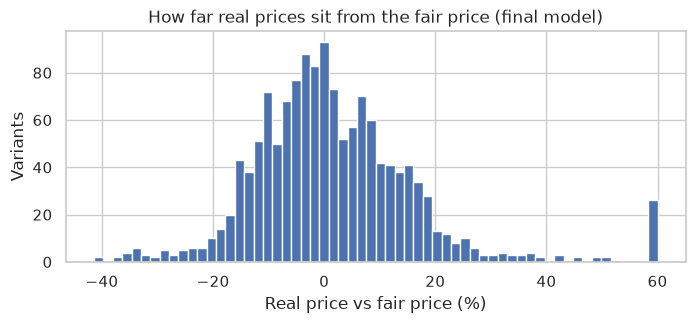

{'model': 'Final model', 'typical error': '8.2%', 'within ±10%': '58%', 'within ±20%': '89%'}
Spread of the difference: {'10% of variants below': '-14%', '25% of variants below': '-7%', '50% of variants below': '-0%', '75% of variants below': '+9%', '90% of variants below': '+18%'}


In [74]:
X_final = options["4. luxury flag + brand for brands with 4+ models"]
pred_final, FINAL_ALPHA = lasso_out_of_fold(X_final)
fit["fair_price"] = np.exp(pred_final)
fit["difference_pct"] = fit["ex_showroom_price"] / fit["fair_price"] - 1

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(fit["difference_pct"].clip(-0.6, 0.6) * 100, bins=60, color="#4C72B0")
ax.set_xlabel("Real price vs fair price (%)")
ax.set_ylabel("Variants")
ax.set_title("How far real prices sit from the fair price (final model)")
plt.show()
print(errors("Final model", pred_final))
print("Spread of the difference:", {f"{q:.0%} of variants below": f"{fit['difference_pct'].quantile(q):+.0%}" for q in [0.1, 0.25, 0.5, 0.75, 0.9]})

The final model's typical error is 8.2%, so small differences are just noise. **Decision:** a variant gets a badge only when it's **more than 15% away** from its fair price, almost twice the typical error.
- **Overpriced:** more than 15% above the fair price.
- **Fair:** within ±15%.
- **Good value:** more than 15% below.

In [75]:
BADGE_CUTOFF = 0.15
fit["badge"] = np.select([fit["difference_pct"] > BADGE_CUTOFF, fit["difference_pct"] < -BADGE_CUTOFF],
                         ["Overpriced", "Good value"], "Fair")
print(fit["badge"].value_counts().to_string(), "\n")
show_extremes(fit)

badge
Fair          1091
Overpriced     191
Good value     113 

Most overpriced:
      company            model                         variant        price         fair difference
       Toyota Land Cruiser 300                            GR-S ₹224.93 lakh  ₹91.32 lakh      +146%
   Land Rover      Range Rover 4.4L SV Sawai Jaisalmer Edition ₹490.00 lakh ₹207.86 lakh      +136%
   Land Rover      Range Rover   4.4L SV Sawai Jodhpur Edition ₹490.00 lakh ₹207.86 lakh      +136%
       Nissan          X-Trail                             STD  ₹48.20 lakh  ₹21.12 lakh      +128%
       Toyota Land Cruiser 300                              ZX ₹217.75 lakh  ₹95.44 lakh      +128%
   Land Rover      Range Rover    4.4L SV Sawai Jaipur Edition ₹490.00 lakh ₹224.85 lakh      +118%
Mercedes-Benz          G-Class    AMG G 63 Collector's Edition ₹430.00 lakh ₹200.22 lakh      +115%
Mercedes-Benz      Maybach GLS         600 Celebration Edition ₹410.00 lakh ₹203.54 lakh      +101%
      Hyundai     

**Checking the extremes by hand.** The Nissan problem is gone, and what's left makes sense:
- **Most overpriced:** limited editions (Range Rover SV "Sawai", G 63 Collector's Edition, Maybach Celebration Edition), and cars imported whole into India, which pay heavy import duty (e.g. Land Cruiser 300, X-Trail, EV9).
- **Best value:** mostly luxury SUVs assembled in India (e.g. Volvo XC90, BMW X7, Mercedes-Benz GLS and GLE, Audi Q5), plus the dual-motor Tata Harrier EV.

The model knows nothing about import duty, local assembly or exclusivity, so these cars sit far from their "feature value". That's a real limit, and it goes into Step 7. Whether a car is imported or assembled locally would be a valuable feature to collect next.

So the badge means **"for its listed features, brand tier and brand"**. It doesn't mean "a good car" or "a bad car".

**Missing features.** For the Fair Price page, we also list what most cars at a variant's price have and this one lacks. The peers are all variants within ±10% of its price, and a feature counts if at least 70% of them have it. Only a confirmed "NO" counts as lacking, never an unknown.

In [76]:
PEER_FEATURES = {**{c: MODEL_FEATURES[c] for c in YES_NO_INPUTS}, "has_sunroof": "sunroof"}
prices_all = model_data["ex_showroom_price"].to_numpy()
has_matrix = model_data[list(PEER_FEATURES)].to_numpy()   # 1 / 0 / nan

missing_lists = []
for i in range(len(model_data)):
    peers = (np.abs(prices_all / prices_all[i] - 1) <= 0.10)
    peers[i] = False
    common = np.nanmean(has_matrix[peers] == 1, axis=0) >= 0.70 if peers.any() else np.zeros(len(PEER_FEATURES), bool)
    lacks = common & (has_matrix[i] == 0)
    missing_lists.append("; ".join(np.array(list(PEER_FEATURES.values()))[lacks]))
model_data["missing_vs_price_peers"] = missing_lists
print(f"Variants missing at least one feature that most cars at their price have: {(model_data['missing_vs_price_peers'] != '').sum():,}")
model_data.loc[model_data["missing_vs_price_peers"] != "", KEY + ["missing_vs_price_peers"]].sample(5, random_state=RANDOM_SEED)

Variants missing at least one feature that most cars at their price have: 530


,company,model,variant,missing_vs_price_peers
404,Maruti Suzuki,e Vitara,Zeta,cruise control
1002,Mahindra,Bolero Neo Plus,P4,automatic climate control; rear camera; push-button start
7,Tata,Sierra,Pure L Dark,rear centre armrest
860,Mahindra,Scorpio N,Z8S Diesel MT,automatic climate control; tyre pressure monitor; push-button start
848,Mahindra,Thar OG,Thar 2.0L ZXT 4WD Petrol AT,fully digital instrument cluster


### 4e. Find similar cars

**Gower distance** compares two cars feature by feature and averages the results:
- **Numbers** are compared by how far apart they are, as a share of the full range. E.g. a 300 mm length difference out of a 1,528 mm range is 0.2.
- **Categories and YES/NO** are 0 if the same, 1 if different.
- A feature that's unknown for either car is skipped.

The result is 0 for identical cars and 1 for completely different ones. **Price is left out**, so the app can find similar cars that cost less.

We write a small function ourselves, so the weights (how much each feature counts) are visible.

In [77]:
SIM_NUMBERS = ["power_bhp", "length_mm", "width_mm", "height_mm", "wheelbase_mm", "seats", "boot_litres", "ground_clearance_mm"]
SIM_CATEGORIES = ["fuel_type", "transmission", "drive"]
SIM_FEATURES = ["has_sunroof", "has_adas", "has_360_view_camera", "has_ventilated_seats", "has_wireless_phone_charging",
                "has_cruise_control", "has_led_headlamps", "has_digital_cluster", "has_alloy_wheels", "has_paddle_shifters",
                "has_automatic_climate_control", "has_rear_disc_brakes", "has_turbo"]

def gower_distance(df, weights):
    """Weighted Gower distance between every pair of rows (price not included)."""
    n = len(df)
    total, weight_sum = np.zeros((n, n)), np.zeros((n, n))
    for column, w in weights.items():
        if column in SIM_NUMBERS:
            x = df[column].to_numpy(dtype=float)
            if column == "power_bhp":
                x = np.log(x)
            d = np.abs(x[:, None] - x[None, :]) / (np.nanmax(x) - np.nanmin(x))
        else:
            codes = pd.factorize(df[column].astype(object))[0].astype(float)
            codes[df[column].isna().to_numpy()] = np.nan
            d = (codes[:, None] != codes[None, :]).astype(float)
            d[np.isnan(codes)[:, None] | np.isnan(codes)[None, :]] = np.nan
        known_pair = ~np.isnan(d)
        total += np.where(known_pair, d * w, 0)
        weight_sum += known_pair * w
    return total / np.where(weight_sum > 0, weight_sum, np.nan)

**Checking the weights against rivals everyone agrees on.** We list 18 pairs of models that car buyers and reviewers commonly compare, including a few "twins" sold by two brands. For each model, we find the 3 other models that show up most often among its variants' 5 nearest neighbours. A pair passes if either model is in the other's top 3.

We compare three sets of weights:
- **Equal:** every feature counts the same.
- **Weighted:** size, seats, power and fuel count 2–3 times.
- **Size-heavy:** like weighted, with length counting 5 times and the 13 YES/NO features half as much.

In [78]:
KNOWN_RIVALS = [("Hyundai Creta", "Kia Seltos"), ("Hyundai Venue", "Kia Sonet"), ("Tata Nexon", "Maruti Suzuki Brezza"),
                ("Tata Nexon", "Mahindra XUV 3XO"), ("Tata Harrier", "MG Hector"), ("Tata Safari", "Mahindra XUV 7XO"),
                ("Tata Safari", "Hyundai Alcazar"), ("Maruti Suzuki Grand Vitara", "Toyota Urban Cruiser Hyryder"),
                ("Maruti Suzuki FRONX", "Toyota Taisor"), ("Renault Kiger", "Nissan Magnite"), ("Skoda Kushaq", "Volkswagen Taigun"),
                ("Toyota Fortuner", "Isuzu MU-X"), ("Tata Punch", "Hyundai Exter"), ("Maruti Suzuki Jimny", "Mahindra Thar OG"),
                ("BMW X5", "Mercedes-Benz GLE"), ("Tata Nexon EV", "Mahindra XUV400 EV"), ("Hyundai Creta Electric", "Tata Curvv EV"),
                ("Mahindra Scorpio N", "Tata Safari")]

model_names = model_data["model_id"].to_numpy(dtype=object)
same_model = model_names[:, None] == model_names[None, :]

def nearest_other_models(distance, k=5):
    d = np.where(same_model, np.inf, distance)
    np.fill_diagonal(d, np.inf)
    return np.argsort(np.nan_to_num(d, nan=np.inf), axis=1)[:, :k]

def rival_check(weights):
    nearest = nearest_other_models(gower_distance(model_data, weights))
    top3 = {m: pd.Series(model_names[nearest[model_names == m].ravel()]).value_counts().head(3).index.tolist()
            for m in np.unique(model_names)}
    passed = [a in top3[b] or b in top3[a] for a, b in KNOWN_RIVALS]
    return sum(passed), top3

equal = {c: 1 for c in SIM_NUMBERS + SIM_CATEGORIES + SIM_FEATURES}
weighted = {**equal, "power_bhp": 3, "length_mm": 3, "width_mm": 2, "wheelbase_mm": 2, "seats": 3, "fuel_type": 3, "transmission": 2, "drive": 2}
size_heavy = {**weighted, "length_mm": 5, "wheelbase_mm": 3, **{c: 0.5 for c in SIM_FEATURES}}

results = {}
for name, weights in [("equal", equal), ("weighted", weighted), ("size-heavy", size_heavy)]:
    results[name] = rival_check(weights)
    print(f"{name:11} weights: {results[name][0]} of {len(KNOWN_RIVALS)} known rival pairs found")

equal       weights: 11 of 18 known rival pairs found


weighted    weights: 13 of 18 known rival pairs found


size-heavy  weights: 15 of 18 known rival pairs found


In [79]:
passes, top3 = results["size-heavy"]
for a, b in KNOWN_RIVALS:
    ok = a in top3[b] or b in top3[a]
    if not ok:
        print(f"Missed: {a} (finds {', '.join(top3[a])})  |  {b} (finds {', '.join(top3[b])})")

Missed: Tata Safari (finds Mahindra Scorpio N, Mahindra XUV 7XO, Tata Harrier)  |  Hyundai Alcazar (finds Mahindra XUV 7XO, Mahindra Scorpio N, Jeep Meridian)
Missed: Toyota Fortuner (finds Mahindra XUV 7XO, Kia Sorento, Mahindra Scorpio N)  |  Isuzu MU-X (finds Jeep Meridian, Mahindra Scorpio N, Toyota Fortuner Legender)
Missed: Hyundai Creta Electric (finds MG ZS EV, Mahindra XUV400 EV, Maruti Suzuki e Vitara)  |  Tata Curvv EV (finds MG ZS EV)


The size-heavy weights find 15 of the 18 pairs, against 11 with equal weights. The three misses are near misses:
- The Safari's list is filled by Mahindra's Scorpio N and XUV 7XO, and by its own 5-seat sibling, the Harrier.
- The Isuzu MU-X finds the Fortuner Legender, the Fortuner's own sister model.
- The Creta Electric's list is filled by other electric SUVs of a similar size.

The check list has only 18 pairs, so we stop tuning here: more tuning would just fit this one list. **Decision:** use the size-heavy weights.

In [80]:
SIM_WEIGHTS = size_heavy
distance = gower_distance(model_data, SIM_WEIGHTS)
np.fill_diagonal(distance, np.inf)
distance = np.nan_to_num(distance, nan=np.inf)
order = np.argsort(distance, axis=1)[:, :10]

similar_rows = []
for i, neighbours in enumerate(order):
    for rank, j in enumerate(neighbours, start=1):
        similar_rows.append({**{k: model_data.at[i, k] for k in KEY}, "rank": rank,
                             **{f"similar_{k}": model_data.at[j, k] for k in KEY},
                             "distance": round(distance[i, j], 4), "same_model": model_names[i] == model_names[j]})
similar_variants = pd.DataFrame(similar_rows)
print(f"Similar-variant rows: {len(similar_variants):,} (10 per variant)")
print(f"Share of nearest neighbours from the same model: {similar_variants.loc[similar_variants['rank'] == 1, 'same_model'].mean():.0%}")

Similar-variant rows: 13,990 (10 per variant)
Share of nearest neighbours from the same model: 86%


Most nearest neighbours are siblings from the same model, which is expected. The app's **rivals list** for reviewers leaves those out.

**Better-value alternatives** for the Fair Price page come from the 10 most similar variants (any model). A candidate counts if:
- its price difference is at least 5 points better than this variant's;
- it costs no more than 10% extra.

We keep up to 3 of them, the most similar first.

In [81]:
value = model_data[KEY].merge(fit[KEY + ["fair_price", "difference_pct", "badge"]], on=KEY, how="left")
difference = value["difference_pct"].to_numpy()

alternatives = []
for i, neighbours in enumerate(order):
    picks = [j for j in neighbours
             if not np.isnan(difference[j]) and not np.isnan(difference[i])
             and difference[j] <= difference[i] - 0.05 and prices_all[j] <= prices_all[i] * 1.10][:3]
    alternatives.append(" | ".join(" ".join(model_data.loc[j, KEY]) for j in picks))
value["better_value_alternatives"] = alternatives
print(f"Variants with at least one better-value alternative: {(value['better_value_alternatives'] != '').sum():,}")

Variants with at least one better-value alternative: 999


**Save the three files for the app.**

In [82]:
fair_prices = (model_data[KEY + ["ex_showroom_price", "missing_vs_price_peers", "few_features"]]
               .merge(value, on=KEY, how="left"))
fair_prices.loc[fair_prices["few_features"], "badge"] = "Not enough data"
fair_prices = fair_prices.drop(columns="few_features")
fair_prices["difference_pct"] = fair_prices["difference_pct"].round(4)
fair_prices["fair_price"] = fair_prices["fair_price"].round(-2)

feature_prices_out = feature_prices[["column", "label", "pct_added", "low_pct", "high_pct", "rupees_at_median_price", "clear", "shown_in_app"]].round(4)
feature_prices_out.to_csv(APP_DATA_DIR / "feature_prices.csv", index=False)
fair_prices.to_csv(APP_DATA_DIR / "fair_prices.csv", index=False)
similar_variants.to_csv(APP_DATA_DIR / "similar_variants.csv", index=False)
for name in ["feature_prices.csv", "fair_prices.csv", "similar_variants.csv"]:
    print(f"Saved {name}: {len(pd.read_csv(APP_DATA_DIR / name)):,} rows")
print("\nBadges:", fair_prices["badge"].value_counts().to_dict())

Saved feature_prices.csv: 41 rows
Saved fair_prices.csv: 1,399 rows
Saved similar_variants.csv: 13,990 rows

Badges: {'Fair': 1091, 'Overpriced': 191, 'Good value': 113, 'Not enough data': 4}


**Result of Step 4:**
- **Fair price:** Version 1 Lasso, with a luxury flag and brand effects only for brands with 4+ models. Tested on models it never saw, its typical error is 8.2%, and 89% of its estimates are within ±20%.
- **Badge:** more than 15% from the fair price. 1,091 variants are fair, 191 overpriced and 113 good value. 4 get no badge ("not enough data").
- **Feature prices:** Version 2, which compares trims of the same model. 41 features are priced, and 17 are clear enough to show in the app.
- **Similar cars:** weighted Gower distance, checked against 18 known rival pairs (15 found).
- **Saved:** `feature_prices.csv`, `fair_prices.csv` and `similar_variants.csv`.

## Step 5: Trim Picker research

**Why the app needs this:** the Trim Picker shows each step up a model's range: what it costs, what it adds, whether it's worth it, and which variant is the best buy.

### 5.1 Make the ladders

A buyer usually decides the engine and gearbox first, e.g. "a petrol manual Nexon", then picks a trim. So a ladder is one **model + fuel + transmission + engine power**, sorted from cheapest to most expensive.

Engine power is in the ladder because some models sell two engines with the same fuel and gearbox. Without it, the ladder would zigzag between them, e.g. the Maruti Suzuki Brezza's 102 bhp and 109 bhp petrol versions.

In [83]:
model_data["ladder"] = (model_data["model_id"] + " | " + model_data["fuel_type"] + " | " + model_data["transmission"] + " | "
                        + model_data["power_bhp"].round(0).map(lambda p: f"{p:.0f} bhp" if pd.notna(p) else "power not listed"))
brezza = model_data[(model_data["model_id"] == "Maruti Suzuki Brezza") & (model_data["transmission"] == "Manual") & (model_data["fuel_type"] == "Petrol")]
print("Brezza petrol manual, by price:", ", ".join(f"{r.variant} ({r.power_bhp:.0f} bhp)" for r in brezza.sort_values("ex_showroom_price").itertuples()), "\n")
ladder_sizes = model_data.groupby("ladder").size()
print(f"Ladders: {len(ladder_sizes)}")
print(f"... with 2 or more variants: {(ladder_sizes >= 2).sum()}  (covering {ladder_sizes[ladder_sizes >= 2].sum():,} variants)")
print(f"... with 5 or more variants: {(ladder_sizes >= 5).sum()}")
print(f"Longest ladder: {ladder_sizes.idxmax()} ({ladder_sizes.max()} variants)")

Brezza petrol manual, by price: LXi Turbo (109 bhp), LXi (102 bhp), VXi Turbo (109 bhp), VXi (102 bhp), ZXi Turbo (109 bhp), ZXi Turbo Dual Tone (109 bhp), ZXi (102 bhp), ZXi Dual Tone (102 bhp), ZXi Plus Turbo (109 bhp), ZXi Plus Turbo Dual Tone (109 bhp) 

Ladders: 302
... with 2 or more variants: 234  (covering 1,331 variants)
... with 5 or more variants: 108
Longest ladder: Hyundai Creta Electric | Electric | Automatic | 169 bhp (23 variants)


Ladders with a single variant have nothing to choose between, so for those the app simply says "only one variant".

### 5.2–5.3 What each step adds

For every step up a ladder, we list:
- the price jump (₹ and %);
- features added and removed (removals do happen);
- number changes, e.g. bigger wheels or more power.

Only confirmed changes count. A feature going from unknown to YES isn't "added", because we can't be sure it was missing before.

In [84]:
STEP_YES_NO = {**{c: MODEL_FEATURES[c] for c in YES_NO_INPUTS}, "has_sunroof": "sunroof"}
STEP_NUMBERS = {"power_bhp": ("power", "bhp"), "wheel_in": ("wheels", "inch"), "touchscreen_in": ("touchscreen", "inch"),
                "speakers": ("speakers", ""), "airbags": ("airbags", ""), "seats": ("seats", "")}
STEP_CATEGORIES = {"sunroof": "sunroof type", "upholstery": "upholstery", "gearbox_type": "gearbox"}

def describe_step(lo, hi):
    """Confirmed differences between two variants (rows of model_data)."""
    added = [label for c, label in STEP_YES_NO.items() if lo[c] == 0 and hi[c] == 1]
    removed = [label for c, label in STEP_YES_NO.items() if lo[c] == 1 and hi[c] == 0]
    changes = [f"{label} {lo[c]:g}→{hi[c]:g}{(' ' + unit) if unit else ''}" for c, (label, unit) in STEP_NUMBERS.items()
               if pd.notna(lo[c]) and pd.notna(hi[c]) and lo[c] != hi[c]]
    changes += [f"{label}: {lo[c]} → {hi[c]}" for c, label in STEP_CATEGORIES.items()
                if pd.notna(lo[c]) and pd.notna(hi[c]) and lo[c] != hi[c]]
    return "; ".join(added), "; ".join(removed), "; ".join(changes)

steps = []
for ladder, rungs in model_data.sort_values(["ladder", "ex_showroom_price"]).groupby("ladder", sort=False):
    rows = rungs.index.tolist()
    for position, i in enumerate(rows):
        record = {"ladder": ladder, "row": i, "position": position + 1, "rungs": len(rows)}
        if position > 0:
            lo, hi = model_data.loc[rows[position - 1]], model_data.loc[i]
            record["from_row"] = rows[position - 1]
            record["price_jump"] = hi["ex_showroom_price"] - lo["ex_showroom_price"]
            record["jump_pct"] = hi["ex_showroom_price"] / lo["ex_showroom_price"] - 1
            record["features_added"], record["features_removed"], record["changes"] = describe_step(lo, hi)
        steps.append(record)
steps = pd.DataFrame(steps)
up = steps[steps["position"] > 1]
print(f"Steps up a ladder: {len(up):,}")
print(f"Typical price jump: {lakh(up['price_jump'].median())} ({up['jump_pct'].median():.1%})")
print(f"Steps that add at least one feature:    {(up['features_added'] != '').mean():.0%}")
print(f"Steps that remove at least one feature: {(up['features_removed'] != '').mean():.0%}")
print(f"Steps with no confirmed change at all:  {((up['features_added'] == '') & (up['features_removed'] == '') & (up['changes'] == '')).mean():.0%}")

Steps up a ladder: 1,097
Typical price jump: ₹0.50 lakh (3.1%)
Steps that add at least one feature:    51%
Steps that remove at least one feature: 10%
Steps with no confirmed change at all:  28%


In [85]:
example = steps[steps["ladder"].str.startswith("Tata Nexon | Petrol | Manual")].copy()
example["variant"] = model_data.loc[example["row"], "variant"].to_numpy()
example["price"] = model_data.loc[example["row"], "ex_showroom_price"].map(lakh).to_numpy()
example[["position", "variant", "price", "features_added", "features_removed", "changes"]].head(8)

,position,variant,price,features_added,features_removed,changes
1133,1,Smart,₹7.40 lakh,NaN,NaN,NaN
1134,2,Smart Plus,₹8.22 lakh,,,touchscreen 0→7 inch; speakers 0→2
1135,3,Smart Plus S,₹8.52 lakh,automatic headlamps; rain-sensing wipers; voice commands; sunroof,,sunroof type: None → Single
1136,4,Pure Plus,₹9.07 lakh,rear camera,automatic headlamps; rain-sensing wipers; voice commands; sunroof,touchscreen 7→10.25 inch; speakers 2→4; sunroof type: Single → None
1137,5,Pure Plus S,₹9.37 lakh,automatic headlamps; rain-sensing wipers; voice commands; sunroof,,sunroof type: None → Single
1138,6,Pure Plus PS,₹9.72 lakh,cruise control,voice commands,speakers 4→6; sunroof type: Single → Panoramic
1139,7,Creative,₹10.17 lakh,ADAS package (stands for the ADAS group); 360° camera; automatic climate control; alloy wheels; push-button start,automatic headlamps; rain-sensing wipers; sunroof,speakers 6→4; sunroof type: Panoramic → None
1140,8,Creative CAMO,₹10.17 lakh,,,touchscreen 10.25→12.3 inch


The Nexon petrol manual ladder shows that **ladders aren't straight lines**. CarDekho lists trims and option packs side by side. "Smart Plus S" adds a sunroof (S stands for sunroof); then the next variant up, "Pure Plus", drops it again but adds a bigger touchscreen and a rear camera. That's why 10% of steps remove a feature, and 28% change nothing we can see. The app has to show what each step takes away as well as what it gives.

### 5.4 Looks-only and paint-only variants (done first)

A quarter of steps change nothing we can see (above). Many of those are **style versions** of the same trim, which a buyer chooses alongside the trim, not as a step up. So we find them before valuing any steps. (The plan had this later, as 5.7–5.8; it moved up because it changes how the ladders should be read.)

**Looks-only:** many variant names contain words like "Dark", "Dual Tone" or "Edition". We don't trust the name alone. For each such variant, we look for the normal variant with the same name minus those words, in the same ladder, and compare their confirmed features.

In [86]:
LOOKS_WORDS = r"\b(Dark|Knight|Black|Dual Tone|DT|Stealth|Red|Night|Carbon|Summer Edition|Aero Black Edition|Black Edition|Edition)\b"

def plain_name(name):
    name = re.sub(LOOKS_WORDS, " ", name, flags=re.I)
    return re.sub(r"\s+", " ", name.replace("(", " (")).strip().lower()

model_data["looks_word"] = model_data["variant"].str.extract(LOOKS_WORDS, flags=re.I, expand=False)
print("Variant names with a looks word:", model_data["looks_word"].notna().sum())
print(model_data["looks_word"].str.title().value_counts().head(8).to_dict())

name_key = model_data["variant"].map(plain_name)
compare_cols = list(STEP_YES_NO) + list(STEP_NUMBERS) + list(STEP_CATEGORIES)
looks_rows = []
for i in model_data.index[model_data["looks_word"].notna()]:
    same = model_data.index[(model_data["ladder"] == model_data.at[i, "ladder"]) & model_data["looks_word"].isna()
                            & (name_key == name_key[i])]
    if len(same) == 0:
        looks_rows.append({"row": i, "match": None, "differences": None})
        continue
    j = same[0]
    a, b = model_data.loc[i, compare_cols], model_data.loc[j, compare_cols]
    diff = [c for c in compare_cols if pd.notna(a[c]) and pd.notna(b[c]) and a[c] != b[c]]
    looks_rows.append({"row": i, "match": j, "differences": diff,
                       "premium": model_data.at[i, "ex_showroom_price"] - model_data.at[j, "ex_showroom_price"]})
looks = pd.DataFrame(looks_rows)
matched = looks["match"].notna()
looks_only = matched & looks["differences"].map(lambda d: d == [] if isinstance(d, list) else False)
print(f"\nMatched to a normal variant: {matched.sum()} of {len(looks)}")
print(f"... with no confirmed feature difference (looks-only): {looks_only.sum()}")
print(f"Typical extra price of a looks-only variant: {lakh(looks.loc[looks_only, 'premium'].median())}")

Variant names with a looks word: 380
{'Dark': 103, 'Dt': 90, 'Edition': 54, 'Dual Tone': 30, 'Knight': 28, 'Black': 17, 'Red': 16, 'Stealth': 14}

Matched to a normal variant: 278 of 380
... with no confirmed feature difference (looks-only): 225
Typical extra price of a looks-only variant: ₹0.18 lakh


In [87]:
not_looks = looks[matched & ~looks_only]
print("Most common differences in name-flagged variants that are not looks-only:")
print(pd.Series([d for ds in not_looks["differences"] for d in ds]).value_counts().head(6).to_string())

Most common differences in name-flagged variants that are not looks-only:
wheel_in                    47
touchscreen_in               5
has_digital_cluster          3
has_hill_descent_control     2
has_360_view_camera          2
upholstery                   2


Wheel size is the most common difference: 47 name-flagged variants (often "Dark" editions) come with bigger wheels, so they're real trims, not just paint. The 225 matched variants with no difference in anything we track are looks-only.

What about "(O)" and "Opt" (optional-pack) variants?

In [88]:
opt_mask = model_data["variant"].str.contains(r"\(O\)|\bOpt\b", regex=True)
opt_key = model_data["variant"].str.replace(r"\(O\)|\bOpt\b", " ", regex=True).map(plain_name)
opt_added = []
for i in model_data.index[opt_mask]:
    same = model_data.index[(model_data["ladder"] == model_data.at[i, "ladder"]) & ~opt_mask & (opt_key == opt_key[i])]
    if len(same):
        opt_added.append(describe_step(model_data.loc[same[0]], model_data.loc[i])[0])
print(f"'(O)' / 'Opt' variants: {opt_mask.sum()}; matched to the same name without it: {len(opt_added)}")
print(f"... that add at least one confirmed feature: {np.mean([a != '' for a in opt_added]):.0%}")
print("Most common additions:", pd.Series([f for a in opt_added for f in a.split('; ') if f]).value_counts().head(5).to_dict())

'(O)' / 'Opt' variants: 122; matched to the same name without it: 65
... that add at least one confirmed feature: 95%
Most common additions: {'sunroof': 50, 'LED headlamps': 7, 'automatic headlamps': 6, 'rain-sensing wipers': 6, 'push-button start': 5}


**Paint-only:** among the variants that aren't looks-only, a variant with exactly the same confirmed features as a cheaper variant in its ladder, costing **at most 3% more**. A small extra like that usually pays for paint (e.g. dual-tone).

The 3% limit matters. A first version of this rule had no limit, and it folded whole real trims together: the Hyundai Creta's EX and E share every *tracked* feature, but EX costs about 11% more for things the data doesn't list. That version also ran before the looks-only check. The Creta's "Summer Edition" variants are ₹800 *cheaper* than the normal ones, so the normal EX, S (O) and so on were wrongly marked as paint versions of them. Looks-only is now settled first.

In [89]:
signature = model_data[compare_cols].map(str).agg("|".join, axis=1)
model_data["looks_only"] = False
model_data["paint_only"] = False
model_data["style_of"] = None   # the normal variant a looks-only / paint-only variant is a style version of
for _, r in looks[looks_only].iterrows():
    model_data.at[r["row"], "looks_only"] = True
    model_data.at[r["row"], "style_of"] = model_data.at[int(r["match"]), "variant"]

PAINT_LIMIT = 0.03
candidates = model_data[~model_data["looks_only"]]
for (ladder, sig), group in candidates.groupby([candidates["ladder"], signature[candidates.index]]):
    if len(group) > 1:
        cheapest = group["ex_showroom_price"].idxmin()
        base_price = group.at[cheapest, "ex_showroom_price"]
        dearer = group.index[(group.index != cheapest) & (group["ex_showroom_price"] > base_price)
                             & (group["ex_showroom_price"] <= base_price * (1 + PAINT_LIMIT))]
        model_data.loc[dearer, "paint_only"] = True
        model_data.loc[dearer, "style_of"] = model_data.at[cheapest, "variant"]
print(f"Paint-only variants: {model_data['paint_only'].sum()}")
print(f"Looks-only variants: {model_data['looks_only'].sum()}")
style_version = model_data["paint_only"] | model_data["looks_only"]
print(f"Flagged as either (style versions): {style_version.sum()}")
print(f"Variants left as real trims:        {(~style_version).sum():,}")

Paint-only variants: 76
Looks-only variants: 225
Flagged as either (style versions): 301
Variants left as real trims:        1,098


**301 variants are style versions** (225 looks-only, 76 paint-only), which leaves 1,098 real trims. A looks-only variant typically costs ₹18,000 more than the normal one. In the app, style versions appear next to their trim (e.g. "also available as SX DT") rather than as steps.

"(O)" / "Opt" variants are different: 95% of them add a real feature, most often a sunroof. So they stay as real trims.

### 5.5 What each step is worth

From here on, a ladder holds **real trims only**. Style versions are shown in the app next to their trim. The steps are rebuilt the same way as in 5.2–5.3.

The Step 4 model (Version 2) prices the change between two trims. For each step we add up the effect of every model column that changes, on the log scale, and turn it into rupees at the lower variant's price:
- **Step value** = what the changes are worth.
- **Value ratio** = step value ÷ price jump. Above 1 means you get more than you pay; below 1 means you pay more than it's worth.

**Which feature prices to count?** The plan said to count only the 17 "clear" feature prices. Before deciding, compare both rules on all steps. If the model is fair, the average step should be worth about what it costs (ratio around 1), because Version 2 was fitted on exactly these price differences.

In [90]:
steps_all = steps   # every variant, kept for reference
real_trims = model_data[~style_version]
steps = []
for ladder, rungs in real_trims.sort_values(["ladder", "ex_showroom_price"]).groupby("ladder", sort=False):
    rows = rungs.index.tolist()
    for position, i in enumerate(rows):
        record = {"ladder": ladder, "row": i, "position": position + 1, "rungs": len(rows)}
        if position > 0:
            lo, hi = model_data.loc[rows[position - 1]], model_data.loc[i]
            record["from_row"] = rows[position - 1]
            record["price_jump"] = hi["ex_showroom_price"] - lo["ex_showroom_price"]
            record["jump_pct"] = hi["ex_showroom_price"] / lo["ex_showroom_price"] - 1
            record["features_added"], record["features_removed"], record["changes"] = describe_step(lo, hi)
        steps.append(record)
steps = pd.DataFrame(steps)
up = steps[steps["position"] > 1]
print(f"Steps between real trims: {len(up):,} (was {len(steps_all[steps_all['position'] > 1]):,} with style versions)")
print(f"Steps with no confirmed change at all: {((up['features_added'] == '') & (up['features_removed'] == '') & (up['changes'] == '')).mean():.0%}")

X_all, _ = make_model_columns(model_data, model_data["model_id"], FILL_MEANS)
coef = pd.Series(within_ols.params, index=TRIM_FEATURES)
clear_cols = feature_prices.loc[feature_prices["clear"], "column"].tolist()

lo_rows, hi_rows = up["from_row"].astype(int).to_numpy(), up["row"].to_numpy()
step_dx = X_all.loc[hi_rows, TRIM_FEATURES].to_numpy() - X_all.loc[lo_rows, TRIM_FEATURES].to_numpy()
lo_price = model_data.loc[lo_rows, "ex_showroom_price"].to_numpy()
jump = up["price_jump"].to_numpy()

def step_values(coefficients, columns=None):
    b = pd.Series(coefficients, index=TRIM_FEATURES)
    if columns is not None:
        b = b.where(b.index.isin(columns), 0)
    return (np.exp(step_dx @ b.to_numpy()) - 1) * lo_price

value_all = step_values(coef)
value_clear = step_values(coef, clear_cols)
priced = jump > 0
print(f"Steps with a real price jump: {priced.sum():,} (the rest cost the same as the variant below)")
for name, value in [("only the 17 clear feature prices", value_clear), ("all feature prices", value_all)]:
    ratio = value[priced] / jump[priced]
    print(f"Counting {name:33}: median value ratio {np.median(ratio):.2f}; all steps together {value[priced].sum() / jump[priced].sum():.2f}; "
          f"steps 'worth it' (ratio ≥ 1): {np.mean(ratio >= 1):.0%}")

Steps between real trims: 796 (was 1,097 with style versions)
Steps with no confirmed change at all: 9%
Steps with a real price jump: 770 (the rest cost the same as the variant below)
Counting only the 17 clear feature prices : median value ratio 0.34; all steps together 0.24; steps 'worth it' (ratio ≥ 1): 15%
Counting all feature prices               : median value ratio 0.77; all steps together 0.43; steps 'worth it' (ratio ≥ 1): 40%


**Counting only the clear prices,** the typical step looks worth a third of its price (median 0.34), and only 15% of steps look worth it. That isn't believable: it throws most of the features away.

**Counting all prices,** a typical step's features explain 77% of its price, and 43% over all steps together.

**Decision: count all feature prices** (a change from the plan). A single unclear price shouldn't be shown on its own, but leaving it out of a step's total makes every step look worse than it is. The uncertainty isn't ignored: the stability test below redraws every price from its bootstrap range.

The ratio is still below 1 for most steps. Is that because of how the prices were estimated? The next cell refits them using only differences within each ladder.

In [91]:
# Check: are the feature prices the reason? Refit them using only differences *within each ladder*.
fit_ladder = (fit["model_id"] + " | " + fit["fuel_type"] + " | " + fit["transmission"]).to_numpy()
lad_X = X_filled[TRIM_FEATURES] - X_filled[TRIM_FEATURES].groupby(fit_ladder).transform("mean")
lad_y = y - pd.Series(y).groupby(fit_ladder).transform("mean").to_numpy()
ladder_coef = np.linalg.lstsq(lad_X.to_numpy(), lad_y, rcond=None)[0]
value_ladder = step_values(ladder_coef)
ratio_ladder = value_ladder[priced] / jump[priced]
print(f"Feature prices fitted within ladders: median value ratio {np.median(ratio_ladder):.2f}; all steps together {value_ladder[priced].sum() / jump[priced].sum():.2f}")

Feature prices fitted within ladders: median value ratio 0.76; all steps together 0.43


The result is almost the same (0.76 and 0.43), so the estimation method isn't the reason. Part of each step's price pays for things the data doesn't list: better materials, small extras, and the brand's own positioning of its top trims. Bigger steps near the top of a ladder carry more of this, which is why the all-steps figure (43%) is lower than the median (77%).

So the value ratio is best read as **how much of the price jump our feature prices explain**:
- **1.2** means the step gives more listed features than its price suggests.
- **0.3** means most of the money goes on things that aren't listed features.

In [92]:
up = up.assign(step_value=value_all.round(-2),
               value_ratio=np.where(priced, value_all / np.where(priced, jump, 1), np.nan))
unclear_labels = feature_prices.loc[~feature_prices["clear"], "label"].tolist()
print("Feature prices that are less certain (shown as 'price unclear' in the app):", ", ".join(unclear_labels[:8]), "...")

Feature prices that are less certain (shown as 'price unclear' in the app): one more seat, one inch bigger wheels, 1 kWh bigger EV battery, strong hybrid, Hybrid gearbox (vs manual), sunroof, panoramic (vs single) sunroof, ADAS package (stands for the ADAS group) ...


### 5.6 The sweet spot, and how stable it is

Two simple rules:
- **Rule A, "stop at the first bad step":** walk up the ladder while each step's value ratio is at least 1. The sweet spot is where you stop.
- **Rule B, "most net value":** for each variant, add up (value gained − money paid) since the base variant. The sweet spot is the variant where that total is largest. Unlike Rule A, it can climb past one poor step if the next steps make up for it.

**Stability test:** redo every ladder 200 times, each time with a different set of feature prices from Step 4's bootstrap. A good rule gives the same sweet spot in most runs.

In [93]:
step_ladder = up["ladder"].to_numpy()
ladders_with_steps = pd.unique(step_ladder)

def sweet_spots(values):
    """Sweet-spot position (1 = base) for each ladder, under both rules."""
    result = {}
    net = values - jump
    ratio = np.where(priced, values / np.where(priced, jump, 1), np.inf)
    for ladder in ladders_with_steps:
        idx = np.where(step_ladder == ladder)[0]
        a = 1
        for k in idx:
            if ratio[k] >= 1:
                a += 1
            else:
                break
        totals = np.concatenate([[0], np.cumsum(net[idx])])
        result[ladder] = (a, int(np.argmax(totals)) + 1)
    return result

main = sweet_spots(value_all)
draws = boot_rng.choice(len(boot_coefs), 200, replace=False)
runs = [sweet_spots(step_values(boot_coefs[d])) for d in draws]

stability = pd.DataFrame({
    "rule_a": {l: np.mean([r[l][0] == main[l][0] for r in runs]) for l in ladders_with_steps},
    "rule_b": {l: np.mean([r[l][1] == main[l][1] for r in runs]) for l in ladders_with_steps},
})
print("Share of the 200 runs giving the same sweet spot (median over ladders):")
print(f"  Rule A: {stability['rule_a'].median():.0%}    ladders stable in at least 80% of runs: {(stability['rule_a'] >= 0.8).mean():.0%}")
print(f"  Rule B: {stability['rule_b'].median():.0%}    ladders stable in at least 80% of runs: {(stability['rule_b'] >= 0.8).mean():.0%}")
position_share = pd.DataFrame({rule: [main[l][k] / (up["ladder"].eq(l).sum() + 1) for l in ladders_with_steps]
                               for k, rule in [(0, "rule_a"), (1, "rule_b")]})
print(f"\nSweet spot is the base variant:  Rule A {np.mean([main[l][0] == 1 for l in ladders_with_steps]):.0%}, Rule B {np.mean([main[l][1] == 1 for l in ladders_with_steps]):.0%}")
print(f"Sweet spot is the top variant:   Rule A {np.mean([main[l][0] == up['ladder'].eq(l).sum() + 1 for l in ladders_with_steps]):.0%}, "
      f"Rule B {np.mean([main[l][1] == up['ladder'].eq(l).sum() + 1 for l in ladders_with_steps]):.0%}")

creta = "Hyundai Creta | Petrol | Manual | 113 bhp"
creta_steps = steps[steps["ladder"] == creta].sort_values("position")
names = model_data.loc[creta_steps["row"], "variant"].tolist()
ratios = up.set_index("row").loc[creta_steps["row"].iloc[1:], "value_ratio"].round(2).tolist()
print(f"\nExample, {creta}:")
print("  value ratio of each step:", ", ".join(f"{n} {r}" for n, r in zip(names[1:], ratios)))
print(f"  Rule A picks {names[main[creta][0] - 1]}; Rule B picks {names[main[creta][1] - 1]}")

Share of the 200 runs giving the same sweet spot (median over ladders):
  Rule A: 98%    ladders stable in at least 80% of runs: 76%
  Rule B: 93%    ladders stable in at least 80% of runs: 66%

Sweet spot is the base variant:  Rule A 60%, Rule B 45%
Sweet spot is the top variant:   Rule A 9%, Rule B 15%

Example, Hyundai Creta | Petrol | Manual | 113 bhp:
  value ratio of each step: EX 1.4, EX (O) 0.68, S (O) 1.15, S (O) Knight 0.6, S(O) Knight Summer Edition nan, SX 1.12, SX Premium 1.2, King 0.14
  Rule A picks EX; Rule B picks SX Premium


- **Rule A is more stable** (98% vs 93%), but mainly because it stops early: it picks the base variant in 60% of ladders, since one weak step ends the walk. In the Creta example above, Rule A stops at EX because the next step (EX (O)) is poor value. It never sees S (O), SX and SX Premium, each of which is good value.
- **Rule B looks at the whole ladder.** Its sweet spot is the base variant in 45% of ladders, the top variant in 15%, and a middle trim in the other 40%. That also answers one of the project's questions: the base is the most common best buy, a middle trim is a close second, and the top trim rarely is.

**Decision: Rule B.** For ladders where its sweet spot is the same in under 80% of runs, the app shows two good choices; the second is the next most common sweet spot across the 200 runs.

In [94]:
RULE = 1   # 0 = Rule A, 1 = Rule B (decision above)
alternative = {}
for l in ladders_with_steps:
    counts = pd.Series([r[l][RULE] for r in runs]).value_counts(normalize=True)
    second = counts.drop(main[l][RULE], errors="ignore")
    alternative[l] = second.index[0] if (stability.loc[l, ["rule_a", "rule_b"][RULE]] < 0.8 and len(second)) else np.nan

steps["sweet_spot"] = [main.get(l, (1, 1))[RULE] == p for l, p in zip(steps["ladder"], steps["position"])]
steps["also_good"] = [alternative.get(l, np.nan) == p for l, p in zip(steps["ladder"], steps["position"])]
steps["sweet_spot_stability"] = steps["ladder"].map(stability[["rule_a", "rule_b"][RULE]])
print(f"Ladders where the app shows two good choices (sweet spot stable in under 80% of runs): {pd.notna(pd.Series(alternative)).sum()}")

Ladders where the app shows two good choices (sweet spot stable in under 80% of runs): 74


### 5.7 Split the automatic's extra cost

For each model, we pair a manual and an automatic variant with the same fuel and the same trim name, e.g. "Smart Plus" and "Smart Plus AMT". Gearbox words (AT, AMT, iVT, DCT, …) are removed from the names before matching.

The price gap is then split in two:
- **extra features:** what Version 2 says the automatic's other differences are worth;
- **the gearbox itself:** the rest of the gap.

In [95]:
GEARBOX_WORDS = r"\b(AT|AMT|iVT|IVT|DCT|DCA|CVT|MT|iMT|TC|Automatic|DSG)\b"
trim_key = model_data["variant"].str.replace(GEARBOX_WORDS, " ", regex=True).map(plain_name)
non_gearbox = [c for c in TRIM_FEATURES if not c.startswith("gearbox_")]
pairs = []
for (model_id, fuel), group in model_data.groupby(["model_id", "fuel_type"]):
    manual = group[group["transmission"] == "Manual"]
    for i, auto in group[group["transmission"] == "Automatic"].iterrows():
        match = manual.index[trim_key[manual.index] == trim_key[i]]
        if len(match) == 0:
            continue
        j = match[0]
        gap = auto["ex_showroom_price"] - model_data.at[j, "ex_showroom_price"]
        dx = X_all.loc[i, non_gearbox] - X_all.loc[j, non_gearbox]
        features_part = (np.exp((dx * coef[non_gearbox]).sum()) - 1) * model_data.at[j, "ex_showroom_price"]
        pairs.append({"company": auto["company"], "model": auto["model"], "fuel_type": fuel,
                      "manual_variant": model_data.at[j, "variant"], "automatic_variant": auto["variant"],
                      "gearbox_type": auto["gearbox_type"], "price_gap": gap,
                      "extra_features_part": round(features_part, -2), "gearbox_part": round(gap - features_part, -2)})
automatic_premium = pd.DataFrame(pairs)
print(f"Manual/automatic pairs found: {len(automatic_premium)} across {automatic_premium[['company', 'model']].drop_duplicates().shape[0]} models")
print(f"Typical price gap: {lakh(automatic_premium['price_gap'].median())}; of which the gearbox itself: "
      f"{lakh(automatic_premium['gearbox_part'].median())}")
by_gearbox = automatic_premium.groupby("gearbox_type").agg(pairs=("price_gap", "size"), price_gap=("price_gap", "median"),
                                                          gearbox_part=("gearbox_part", "median"))
by_gearbox[["price_gap", "gearbox_part"]] = by_gearbox[["price_gap", "gearbox_part"]].map(lakh)
by_gearbox.sort_values("pairs", ascending=False)

Manual/automatic pairs found: 333 across 43 models
Typical price gap: ₹1.36 lakh; of which the gearbox itself: ₹1.11 lakh


,pairs,price_gap,gearbox_part
gearbox_type,,,
"Automatic, type not listed",197,₹1.47 lakh,₹1.22 lakh
Torque-converter AT,40,₹1.32 lakh,₹1.19 lakh
CVT,34,₹1.33 lakh,₹1.10 lakh
AMT,31,₹0.65 lakh,₹0.51 lakh
DCT,31,₹1.30 lakh,₹1.00 lakh


In [96]:
by_brand = (automatic_premium.groupby("company")
            .agg(pairs=("price_gap", "size"), gearbox_part=("gearbox_part", "median"))
            .query("pairs >= 5").sort_values("gearbox_part"))
by_brand.assign(gearbox_part=by_brand["gearbox_part"].map(lakh))

,pairs,gearbox_part
company,,
Nissan,12,₹0.60 lakh
Skoda,10,₹0.80 lakh
Kia,21,₹0.87 lakh
Renault,15,₹0.90 lakh
MG,5,₹1.10 lakh
Honda,5,₹1.11 lakh
Hyundai,36,₹1.14 lakh
Tata,127,₹1.15 lakh
Toyota,13,₹1.17 lakh


An automatic typically costs ₹1.36 lakh more than the same trim with a manual gearbox. About ₹1.11 lakh of that is the gearbox itself; the rest is extra features that come with it.
- **AMTs,** the simplest automatics, add only about ₹0.51 lakh for the gearbox.
- **Torque-converter, CVT and dual-clutch** gearboxes cost about ₹1.0–1.2 lakh.
- **By brand** (brands with at least 5 pairs), Nissan charges least for the gearbox itself (₹0.60 lakh) and Jeep the most (₹2.63 lakh).

### 5.8 How bare is the base variant?

For each ladder, we count the confirmed YES features of the base variant against the top variant.

In [97]:
yes_count = model_data[list(STEP_YES_NO)].eq(1).sum(axis=1)
bare = []
for ladder, rungs in model_data.groupby("ladder"):
    if len(rungs) < 2:
        continue
    base, top = rungs["ex_showroom_price"].idxmin(), rungs["ex_showroom_price"].idxmax()
    bare.append({"ladder": ladder, "base_features": yes_count[base], "top_features": yes_count[top],
                 "base_share": yes_count[base] / max(yes_count[top], 1)})
bare = pd.DataFrame(bare)
print(f"Median: the base variant has {bare['base_share'].median():.0%} of the top variant's features")
print("\nBarest base variants (ladders with 5+ variants):")
long = bare[bare["ladder"].map(ladder_sizes) >= 5].nsmallest(5, "base_share")
print(long.assign(base_share=long["base_share"].map("{:.0%}".format)).to_string(index=False))
model_data["base_feature_share"] = model_data["ladder"].map(bare.set_index("ladder")["base_share"])

Median: the base variant has 61% of the top variant's features

Barest base variants (ladders with 5+ variants):
                                       ladder  base_features  top_features base_share
Citroen Aircross X | Petrol | Manual | 81 bhp              0            12         0%
  Citroen Basalt X | Petrol | Manual | 80 bhp              0            12         0%
 Citroen Basalt X | Petrol | Manual | 109 bhp              1            13         8%
     Hyundai Exter | Petrol | Manual | 82 bhp              1            11         9%
        Hyundai Exter | CNG | Manual | 68 bhp              1            10        10%


The median base variant has 61% of its top variant's tracked features. Citroen's base variants are the barest: they list none of the tracked features as YES. The app shows this as a "how bare is the base?" bar on each ladder.

**Save the Trim Picker files.** `trim_ladders.csv` has one row per variant, in ladder order. `automatic_premium.csv` holds the manual/automatic pairs from 5.7; it wasn't in the plan, but the Trim Picker's "is the automatic worth it?" note needs it.

In [98]:
steps = steps.merge(up[["row", "step_value", "value_ratio"]], on="row", how="left")
style_rows = pd.DataFrame({"ladder": model_data.loc[style_version, "ladder"], "row": model_data.index[style_version]})
all_rows = pd.concat([steps, style_rows], ignore_index=True)
trim_ladders = pd.concat([all_rows.reset_index(drop=True),
                          model_data.loc[all_rows["row"], KEY + ["fuel_type", "transmission", "ex_showroom_price", "looks_only",
                                                                 "paint_only", "style_of", "base_feature_share"]].reset_index(drop=True)], axis=1)
trim_ladders = trim_ladders.sort_values(["ladder", "ex_showroom_price"]).reset_index(drop=True)
trim_ladders = trim_ladders[["ladder"] + KEY + ["fuel_type", "transmission", "position", "rungs", "ex_showroom_price",
                             "price_jump", "jump_pct", "features_added", "features_removed", "changes", "step_value",
                             "value_ratio", "sweet_spot", "also_good", "sweet_spot_stability", "looks_only", "paint_only",
                             "style_of", "base_feature_share"]]
trim_ladders["jump_pct"] = trim_ladders["jump_pct"].round(4)
trim_ladders["value_ratio"] = trim_ladders["value_ratio"].round(3)
trim_ladders.to_csv(APP_DATA_DIR / "trim_ladders.csv", index=False)
automatic_premium.to_csv(APP_DATA_DIR / "automatic_premium.csv", index=False)
for name in ["trim_ladders.csv", "automatic_premium.csv"]:
    print(f"Saved {name}: {len(pd.read_csv(APP_DATA_DIR / name)):,} rows")
trim_ladders[trim_ladders["ladder"].str.startswith("Hyundai Creta | Petrol | Manual")][
    ["position", "variant", "ex_showroom_price", "features_added", "value_ratio", "sweet_spot", "style_of"]].head(17)

Saved trim_ladders.csv: 1,399 rows
Saved automatic_premium.csv: 333 rows


,position,variant,ex_showroom_price,features_added,value_ratio,sweet_spot,style_of
177,1.0,E,1090700,NaN,NaN,False,None
178,NaN,EX Summer Edition,1205900,NaN,NaN,NaN,EX
179,2.0,EX,1206700,push-button start; voice commands,1.397,False,None
180,NaN,EX (O) Summer Edition,1313400,NaN,NaN,NaN,EX (O)
181,3.0,EX (O),1314200,LED headlamps; sunroof,0.683,False,None
182,NaN,S (O) Summer Edition,1419900,NaN,NaN,NaN,S (O)
183,4.0,S (O),1420700,cruise control; automatic headlamps; automatic climate control; alloy wheels; rear camera,1.150,False,None
184,5.0,S (O) Knight,1439200,,0.600,False,None
185,6.0,S(O) Knight Summer Edition,1439200,,NaN,False,None
186,NaN,SX Summer Edition,1503600,NaN,NaN,NaN,SX


**Result of Step 5:**
- **302 ladders** (model + fuel + transmission + engine power); 234 of them have 2 or more variants.
- **301 style versions** (looks-only or paint-only) are shown next to their trims, not as steps.
- **Each step** has its price jump, what it adds and removes, its value, and a value ratio (how much of the jump our feature prices explain).
- **The sweet spot** uses Rule B ("most net value"). 74 ladders get two good choices, because their sweet spot isn't stable.
- **The automatic's extra cost** is split into gearbox and features for 333 manual/automatic pairs.
- **Saved:** `trim_ladders.csv` and `automatic_premium.csv`.

## Step 6: Must-Have Finder research

**Why the app needs this:** the Finder shows three things:
1. the cheapest cars with all of a buyer's must-haves;
2. the cheapest price at which each feature is available;
3. which variants to skip because a cheaper one beats them.

### 6.1 Finder options for every variant

The 32 options from Step 3.8 are already YES/NO for every variant. Unknown counts as NO, so the app never claims a car has something we can't confirm. We save them as `finder_flags.csv`, which the app filters live as the buyer ticks boxes. (This file wasn't in the plan's list; the app needs it to search.)

In [99]:
finder = pd.concat([variants_clean[KEY + ["ex_showroom_price"]], finder_flags], axis=1)
finder.to_csv(APP_DATA_DIR / "finder_flags.csv", index=False)
print(f"Saved finder_flags.csv: {len(finder):,} variants x {finder_flags.shape[1]} options")

Saved finder_flags.csv: 1,399 variants x 32 options


### 6.2 Entry price of each option

Two answers for each option:
- **Cheapest variant with it:** the simple answer. A single unusually cheap car can set it.
- **The price at which half of all variants have it:** sturdier. A **logistic regression** of "has the option" (1/0) against log(price) draws an S-shaped curve of how the chance of having the option rises with price. We read off where the curve crosses 50%.

Some options don't get more common with price. Fuel types are an example: diesel isn't a "premium feature". For those the curve is flat or falling, and there is no 50% point.

In [100]:
log_price = np.log(finder["ex_showroom_price"].to_numpy())
price_range = (finder["ex_showroom_price"].min(), finder["ex_showroom_price"].max())

entry = []
curves = {}
for option in finder_flags.columns:
    has = finder_flags[option].to_numpy().astype(int)
    cheapest = finder.loc[finder_flags[option]].nsmallest(1, "ex_showroom_price")
    logit = sm.Logit(has, sm.add_constant(log_price)).fit(disp=0)
    a, b = logit.params
    price_50 = np.exp(-a / b) if b > 0 else np.nan
    if not (price_range[0] <= price_50 <= price_range[1]):
        price_50 = np.nan
    curves[option] = (a, b)
    entry.append({"option": option, "variants_with_it": has.sum(),
                  "cheapest_variant": " ".join(cheapest[KEY].iloc[0]) if len(cheapest) else "",
                  "cheapest_price": cheapest["ex_showroom_price"].iloc[0] if len(cheapest) else np.nan,
                  "price_at_50pct": price_50, "rises_with_price": b > 0})
entry = pd.DataFrame(entry).sort_values("price_at_50pct")
print(f"Options whose chance rises with price: {entry['rises_with_price'].sum()} of {len(entry)}")
print(f"... with a 50% point inside the price range: {entry['price_at_50pct'].notna().sum()}")
entry.assign(cheapest_price=entry["cheapest_price"].map(lakh),
             price_at_50pct=entry["price_at_50pct"].map(lambda p: lakh(p) if pd.notna(p) else "no 50% point"))[
    ["option", "variants_with_it", "cheapest_variant", "cheapest_price", "price_at_50pct"]].reset_index(drop=True)

Options whose chance rises with price: 27 of 32
... with a 50% point inside the price range: 23


,option,variants_with_it,cheapest_variant,cheapest_price,price_at_50pct
0,Automatic climate control,1160,Nissan Magnite Acenta,₹6.87 lakh,₹6.01 lakh
1,LED headlamps,1107,Tata Punch Smart,₹5.75 lakh,₹6.18 lakh
2,Cruise control,1111,Tata Punch Pure Plus,₹7.17 lakh,₹8.80 lakh
3,Any sunroof,945,Tata Punch Pure Plus S,₹7.52 lakh,₹8.82 lakh
4,Leather or leatherette seats,846,Kia Sonet HTE,₹7.45 lakh,₹12.46 lakh
5,Rear disc brakes,935,Mahindra XUV 3XO MX1,₹7.79 lakh,₹12.76 lakh
6,Wireless phone charging,839,Hyundai Exter HX8,₹8.44 lakh,₹13.44 lakh
7,Automatic,846,Nissan Magnite Visia AMT,₹6.30 lakh,₹14.46 lakh
8,Alloy wheels,755,Nissan Magnite N Connecta,₹7.50 lakh,₹16.44 lakh
9,Panoramic sunroof,717,Tata Nexon Pure Plus PS,₹9.72 lakh,₹18.19 lakh


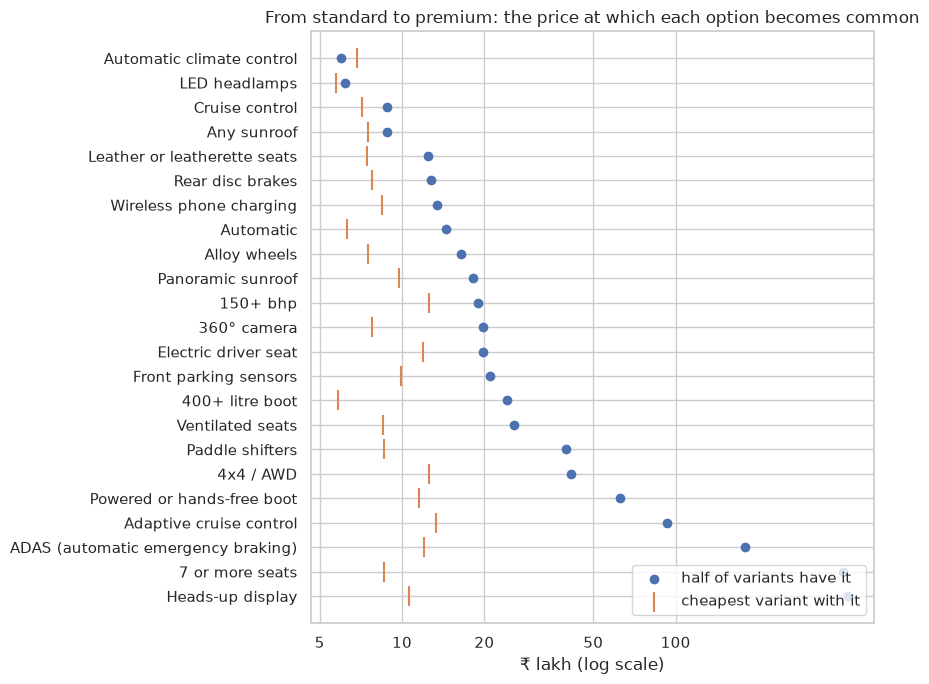

In [101]:
ranked = entry.dropna(subset=["price_at_50pct"]).sort_values("price_at_50pct")
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(ranked["price_at_50pct"] / 1e5, ranked["option"], color="#4C72B0", zorder=3, label="half of variants have it")
ax.scatter(ranked["cheapest_price"] / 1e5, ranked["option"], color="#DD8452", marker="|", s=200, zorder=3, label="cheapest variant with it")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100], ["5", "10", "20", "50", "100"])
ax.set_xlabel("₹ lakh (log scale)")
ax.set_title("From standard to premium: the price at which each option becomes common")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

The chart runs from **standard** to **premium**:
- **Common below ₹10 lakh:** automatic climate control, LED headlamps, cruise control and a sunroof. Half of all variants have them by ₹6–9 lakh.
- **Mid-market (about ₹12–15 lakh):** wireless charging, leather or leatherette seats, rear disc brakes and an automatic gearbox.
- **Common around ₹18–26 lakh:** panoramic sunroof, 150+ bhp, 360° camera, electric driver seat and ventilated seats.
- **Rare at almost every price:** ADAS, adaptive cruise control and a heads-up display. Half of all variants don't have ADAS until about ₹1.8 crore, yet the cheapest car with it costs only ₹12.03 lakh (Mahindra XUV 3XO AX5 L Turbo). That gap is exactly what the Finder is for: a buyer can get ADAS far below the price where it becomes common.

For 9 options there's no 50% point inside the price range:
- fuel types and strong hybrids, which aren't premium features;
- features already common at every price (6+ airbags, digital cluster, 10-inch screen, 5-star crash rating);
- wireless Android Auto / Apple CarPlay.

**Which brands bring features down to cheaper cars?** For each option, we find the brand that sells the cheapest variant with it, and count how often each brand comes first.

In [102]:
per_brand = []
for option in finder_flags.columns:
    with_it = finder.loc[finder_flags[option]]
    for brand, rows in with_it.groupby("company"):
        best = rows.nsmallest(1, "ex_showroom_price").iloc[0]
        per_brand.append({"option": option, "company": brand, "cheapest_variant": " ".join(best[KEY]),
                          "cheapest_price": best["ex_showroom_price"]})
per_brand = pd.DataFrame(per_brand)
first = per_brand.loc[per_brand.groupby("option")["cheapest_price"].idxmin()]
print("Brand with the cheapest variant, counted over the 32 options:")
print(first["company"].value_counts().to_string())

Brand with the cheapest variant, counted over the 32 options:
company
Tata             7
Nissan           7
Mahindra         6
Hyundai          4
Maruti Suzuki    4
Renault          3
Kia              1


Tata and Nissan most often sell the cheapest variant with an option (7 options each), followed by Mahindra (6). Tata, for example, brings a sunroof and a 360° camera to the Punch at under ₹8 lakh.

### 6.3 How the price rises as must-haves are added

The app works this out live from `finder_flags.csv`: the cheapest car that has every ticked option. Here we test one growing list.

In [103]:
def cheapest_with(options):
    mask = finder_flags[options].all(axis=1)
    if not mask.any():
        return None
    return finder.loc[mask].nsmallest(1, "ex_showroom_price").iloc[0]

wish_list = ["Automatic", "Any sunroof", "360° camera", "7 or more seats", "ADAS (automatic emergency braking)", "Diesel"]
for k in range(1, len(wish_list) + 1):
    best = cheapest_with(wish_list[:k])
    matches = finder_flags[wish_list[:k]].all(axis=1).sum()
    print(f"+ {wish_list[k - 1]:36} → cheapest: {' '.join(best[KEY]) if best is not None else 'none'} "
          f"({lakh(best['ex_showroom_price']) if best is not None else '-'}); variants with all: {matches}")

+ Automatic                            → cheapest: Nissan Magnite Visia AMT (₹6.30 lakh); variants with all: 846
+ Any sunroof                          → cheapest: Tata Punch Pure Plus S AMT (₹8.10 lakh); variants with all: 626
+ 360° camera                          → cheapest: Tata Punch Adventure S CNG AMT (₹9.72 lakh); variants with all: 422
+ 7 or more seats                      → cheapest: Tata Safari Petrol Pure X AT (₹18.35 lakh); variants with all: 88
+ ADAS (automatic emergency braking)   → cheapest: Tata Safari Petrol Adventure X Plus AT (₹19.80 lakh); variants with all: 35
+ Diesel                               → cheapest: Tata Safari Adventure X Plus AT (₹21.05 lakh); variants with all: 10


Each must-have narrows the choice:
- An automatic alone starts at ₹6.30 lakh (846 variants).
- Adding a sunroof and a 360° camera still costs under ₹10 lakh (422 variants).
- **7 seats is the big jump:** the cheapest is ₹18.35 lakh, and only 88 variants are left.
- With ADAS and diesel on top, just 10 variants remain, from ₹21.05 lakh.

This is the "what does each must-have cost me?" view the app shows.

### 6.4 Feature bundles (association rules)

Some options almost always come together. **Association rules** find them, using three measures:
- **Support:** how common it is for a car to have both A and B.
- **Confidence:** if a car has A, how often it also has B.
- **Lift:** how much more often A and B come together than chance would suggest. 1 means no link.

We use the Apriori method to find combinations with support of at least 5%. Then we keep rules with one option on each side, confidence of at least 0.9 and lift above 1.2. The app uses them for notes like "cars with ventilated seats nearly always have wireless phone charging too".

In [104]:
FUEL_AND_GEARBOX = ["Automatic", "Diesel", "Electric", "CNG", "Strong hybrid"]
basket = finder_flags.drop(columns=FUEL_AND_GEARBOX)
frequent = apriori(basket, min_support=0.05, use_colnames=True, max_len=2)
rules = association_rules(frequent, num_itemsets=len(basket), metric="confidence", min_threshold=0.9)
rules = rules[(rules["lift"] > 1.2) & (rules["antecedents"].map(len) == 1) & (rules["consequents"].map(len) == 1)].copy()
rules["if_a_car_has"] = rules["antecedents"].map(lambda s: next(iter(s)))
rules["it_usually_has"] = rules["consequents"].map(lambda s: next(iter(s)))
bundles = rules[["if_a_car_has", "it_usually_has", "support", "confidence", "lift"]].round(3).sort_values("lift", ascending=False)
print(f"Bundle rules kept: {len(bundles)}")
bundles.head(12).reset_index(drop=True)

Bundle rules kept: 32


,if_a_car_has,it_usually_has,support,confidence,lift
0,Adaptive cruise control,Electric driver seat,0.209,0.945,2.112
1,4x4 / AWD,150+ bhp,0.138,0.910,2.088
2,ADAS (automatic emergency braking),Electric driver seat,0.190,0.933,2.086
3,Adaptive cruise control,Wireless phone charging,0.214,0.965,1.608
4,Adaptive cruise control,Leather or leatherette seats,0.210,0.948,1.568
5,Ventilated seats,Wireless phone charging,0.411,0.938,1.564
6,ADAS (automatic emergency braking),Wireless phone charging,0.189,0.930,1.550
7,ADAS (automatic emergency braking),Leather or leatherette seats,0.189,0.930,1.538
8,Heads-up display,Wireless phone charging,0.088,0.911,1.519
9,Electric driver seat,Leather or leatherette seats,0.410,0.917,1.516


The strongest bundles link premium features:
- Cars with adaptive cruise control or ADAS nearly always have an electric driver seat, wireless charging, and leather or leatherette seats.
- 4x4 nearly always comes with 150+ bhp.

A confidence of 0.9 means 9 out of 10 cars with the first feature also have the second.

Fuel types and gearbox were left out of the bundles: they're choices a buyer makes, not features that come in packs.

### 6.5 Variants beaten by a cheaper one

Variant A **beats** variant B when all of these are true:
- **Same fuel, gearbox type (manual or automatic) and number of seats.** A buyer who wants a diesel won't accept a petrol, however good it is. More seats isn't automatically better either: a 6-seater with captain chairs is a deliberate choice.
- **A costs the same or less.**
- **A has every Finder option B has.**
- **A is at least as good on every key number:** power, boot space, airbags, length, touchscreen size. Where B's number is unknown it's skipped; where A's is unknown, A can't be shown to be at least as good.
- **A is better on at least one of those numbers, or at least 3% cheaper.**

Extra *options* on A don't count as "better". B's missing options may just be unknown (unknown counts as NO in the Finder), so they can't prove that A is better.

Style versions of the same trim (same model, identical options and numbers) don't count. Step 5 handles those as "also available as …".

In [105]:
NUMBERS_TO_BEAT = ["power_bhp", "boot_litres", "airbags", "length_mm", "touchscreen_in"]
opt = finder_flags.to_numpy()
num = variants_clean[NUMBERS_TO_BEAT].to_numpy(dtype=float)
price = finder["ex_showroom_price"].to_numpy(dtype=float)
group = (variants_clean["fuel_type"] + "|" + variants_clean["transmission"] + "|" + variants_clean["seats"].astype(str)).to_numpy(dtype=object)
model_of = (variants_clean["company"] + " " + variants_clean["model"]).to_numpy(dtype=object)

beaten_by = []
for b in range(len(finder)):
    candidates = np.where((group == group[b]) & (price <= price[b]))[0]
    candidates = candidates[candidates != b]
    if len(candidates) == 0:
        continue
    has_all = (opt[candidates] | ~opt[b]).all(axis=1)
    b_known = ~np.isnan(num[b])
    a_vals = num[candidates][:, b_known]
    at_least = (~np.isnan(a_vals) & (a_vals >= num[b][b_known])).all(axis=1)
    better = ((~np.isnan(a_vals) & (a_vals > num[b][b_known])).any(axis=1)
              | (price[candidates] <= price[b] * 0.97))
    style = (model_of[candidates] == model_of[b]) & (opt[candidates] == opt[b]).all(axis=1) & \
            np.array([np.array_equal(num[a], num[b], equal_nan=True) for a in candidates])
    winners = candidates[has_all & at_least & better & ~style]
    if len(winners):
        a = winners[np.argmin(price[winners])]
        beaten_by.append({**{k: variants_clean.at[b, k] for k in KEY}, "price": price[b],
                          **{f"beaten_by_{k}": variants_clean.at[a, k] for k in KEY}, "beaten_by_price": price[a],
                          "saving": price[b] - price[a], "cheaper_options": int(len(winners))})
dominated = pd.DataFrame(beaten_by)
print(f"Variants beaten by a cheaper (or equal-price, better) variant: {len(dominated)} of {len(finder):,}")
print(f"... beaten by a variant of another brand: {(dominated['company'] != dominated['beaten_by_company']).sum()}")
print(f"Typical saving by switching: {lakh(dominated['saving'].median())}")

Variants beaten by a cheaper (or equal-price, better) variant: 110 of 1,399
... beaten by a variant of another brand: 52
Typical saving by switching: ₹0.70 lakh


In [106]:
check = dominated.sample(5, random_state=RANDOM_SEED)
for _, r in check.iterrows():
    b = variants_clean.index[(variants_clean[KEY] == r[KEY].to_numpy()).all(axis=1)][0]
    a = variants_clean.index[(variants_clean[KEY] == r[[f"beaten_by_{k}" for k in KEY]].to_numpy()).all(axis=1)][0]
    extra = [o for o in finder_flags.columns if finder_flags.at[a, o] and not finder_flags.at[b, o]]
    nums = ", ".join(f"{c} {variants_clean.at[b, c]:g}→{variants_clean.at[a, c]:g}" for c in NUMBERS_TO_BEAT
                     if pd.notna(variants_clean.at[b, c]) and pd.notna(variants_clean.at[a, c]) and variants_clean.at[a, c] != variants_clean.at[b, c])
    print(f"{' '.join(r[KEY])} ({lakh(r['price'])})\n   beaten by {' '.join(r[[f'beaten_by_{k}' for k in KEY]])} ({lakh(r['beaten_by_price'])})"
          f"\n   extra options: {', '.join(extra) or 'none'}; numbers: {nums or 'same'}\n")

Skoda Kodiaq RS 2.0 TSI (₹66.99 lakh)
   beaten by Volkswagen Tayron R-Line (₹47.74 lakh)
   extra options: ADAS (automatic emergency braking), 150+ bhp, Wireless Android Auto / Apple CarPlay, Paddle shifters, Heads-up display, Powered or hands-free boot; numbers: boot_litres 281→345, length_mm 4761→4792, touchscreen_in 12.9→15

Maruti Suzuki Brezza VXi (₹9.31 lakh)
   beaten by Maruti Suzuki Brezza VXi Turbo (₹8.65 lakh)
   extra options: Alloy wheels; numbers: power_bhp 102→109

Tata Nexon Creative Plus S Dark Diesel AMT (₹12.72 lakh)
   beaten by Tata Nexon Creative Plus S CAMO Diesel AMT (₹12.52 lakh)
   extra options: none; numbers: touchscreen_in 10.25→12.3

Volkswagen Taigun Comfortline (₹11.00 lakh)
   beaten by Skoda Kushaq 1.0L Classic Plus (₹10.69 lakh)
   extra options: Any sunroof, Alloy wheels; numbers: length_mm 4221→4229

Hyundai Exter HX3 CNG (₹7.50 lakh)
   beaten by Nissan Magnite Visia Plus CNG (₹6.97 lakh)
   extra options: none; numbers: power_bhp 68→71, boot_litr

**110 variants are beaten** by a cheaper or equally priced variant, 52 of them by another brand. Switching typically saves ₹70,000.

The hand check shows sensible cases:
- The Skoda Kushaq beats its twin, the Volkswagen Taigun.
- The Volkswagen Tayron beats its close relative, the Skoda Kodiaq RS.

One case looks like a listing quirk worth checking on CarDekho: the Brezza's "Turbo" variants are listed as cheaper *and* more powerful than the non-Turbo ones.

A first version of this rule counted more seats and extra options as "better". Checking examples by hand showed that it flagged 6-seat captain-chair versions as beaten by 7-seaters, and that it counted options that were merely unknown. Both were removed (see the rule above).

The app hides beaten variants by default. A "show hidden" switch brings them back, with the reason ("beaten by …").

In [107]:
entry_out = pd.concat([
    entry.assign(scope="all brands")[["option", "scope", "cheapest_variant", "cheapest_price", "price_at_50pct"]],
    per_brand.rename(columns={"company": "scope"}).assign(price_at_50pct=np.nan)[["option", "scope", "cheapest_variant", "cheapest_price", "price_at_50pct"]],
], ignore_index=True)
entry_out["price_at_50pct"] = entry_out["price_at_50pct"].round(-3)
entry_out.to_csv(APP_DATA_DIR / "entry_prices.csv", index=False)
bundles.to_csv(APP_DATA_DIR / "bundles.csv", index=False)
dominated.to_csv(APP_DATA_DIR / "dominated_variants.csv", index=False)
for name in ["entry_prices.csv", "bundles.csv", "dominated_variants.csv"]:
    print(f"Saved {name}: {len(pd.read_csv(APP_DATA_DIR / name)):,} rows")

Saved entry_prices.csv: 681 rows
Saved bundles.csv: 32 rows
Saved dominated_variants.csv: 110 rows


**Result of Step 6:**
- **Finder flags:** all 1,399 variants × 32 options (`finder_flags.csv`).
- **Entry prices:** the cheapest variant with each option, overall and per brand, plus the price at which half of variants have it, where there is one (`entry_prices.csv`).
- **Bundles:** 32 rules for "usually comes with" notes (`bundles.csv`).
- **Beaten variants:** 110, each with the variant that beats it (`dominated_variants.csv`).

## Step 7: Limits and summary

**Why the app needs this:** the app's About page and its warnings come from here, and so does a reader's trust in the numbers.

### 7.1 What the data can't tell us

- **One city, one day.** All prices are New Delhi prices from 20 Nov 2026. On-road prices differ by city (road tax rules differ), and prices change over time. The app says this on every price.
- **List prices, not deal prices.** Buyers often get discounts that this data doesn't show.
- **Missing features are "unknown", not "no".** CarDekho doesn't list some features for whole models (Step 2.2). For example, many luxury models have no ADAS section, though they very likely have ADAS. The Finder only counts a confirmed YES, so it may miss some cars.
- **CarDekho makes mistakes too.** We found and handled several:
  - a 1 mm ground clearance (2.3);
  - the spelling "Guidedlines" (2.4);
  - a ₹4,30,00,001 placeholder price (1.6);
  - Brezza "Turbo" variants listed as cheaper and more powerful (6.5).

  There will be others.
- **The models don't know everything that sets a price.** Import duty and local assembly, exclusivity, brand image, build quality, reliability, ride comfort and service costs are all missing. Step 4d showed the biggest gaps between real and fair price come from exactly these. The badge means "for its listed features, brand tier and brand", not "a good car".
- **The value ratio only covers what we can price.** A typical trim step's listed features explain about three-quarters of its price (Step 5.5). The rest pays for things that aren't listed.
- **Small checks.** The similar-car weights were checked against 18 known rival pairs. That's useful, but not proof.
- **Not covered:** fuel economy (known for 49% of variants, Step 3.3) and crash ratings (Bharat NCAP for 615 of 1,399 variants, Step 2.3) are too patchy for their own pages yet. 4 variants list too few features for a fair price.

### 7.2 Main findings for each app page

All numbers below are printed by the next cell.

In [108]:
fp = feature_prices.set_index("column")
final_errors = errors("final", pred_final)
rule_b = [main[l][1] for l in ladders_with_steps]
rungs_per_ladder = [up["ladder"].eq(l).sum() + 1 for l in ladders_with_steps]
summary = [
    ("Fair Price", "typical error on models the model never saw", final_errors["typical error"]),
    ("Fair Price", "estimates within ±20%", final_errors["within ±20%"]),
    ("Fair Price", "badges", ", ".join(f"{k} {v}" for k, v in fair_prices["badge"].value_counts().items())),
    ("Fair Price", "torque-converter automatic adds (same model, vs manual)", f"{fp.at['gearbox_torque_converter_at', 'pct_added']:+.1%}"),
    ("Fair Price", "AMT adds", f"{fp.at['gearbox_amt', 'pct_added']:+.1%}"),
    ("Fair Price", "diesel adds (vs petrol)", f"{fp.at['fuel_diesel', 'pct_added']:+.1%}"),
    ("Fair Price", "360° camera adds", f"{fp.at['has_360_view_camera', 'pct_added']:+.1%}"),
    ("Fair Price", "feature prices clear enough to show", f"{feature_prices['shown_in_app'].sum()} of {len(feature_prices)}"),
    ("Trim Picker", "sweet spot is the base / a middle trim / the top", f"{np.mean(np.array(rule_b) == 1):.0%} / "
     f"{np.mean((np.array(rule_b) > 1) & (np.array(rule_b) < np.array(rungs_per_ladder))):.0%} / {np.mean(np.array(rule_b) == np.array(rungs_per_ladder)):.0%}"),
    ("Trim Picker", "style versions (looks-only or paint-only)", f"{int(style_version.sum())} of {len(model_data):,} variants"),
    ("Trim Picker", "typical extra for a looks-only version", lakh(looks.loc[looks_only, 'premium'].median())),
    ("Trim Picker", "automatic: typical price gap / of which the gearbox", f"{lakh(automatic_premium['price_gap'].median())} / {lakh(automatic_premium['gearbox_part'].median())}"),
    ("Finder", "cheapest variant with ADAS", f"{entry.set_index('option').at['ADAS (automatic emergency braking)', 'cheapest_variant']} "
     f"({lakh(entry.set_index('option').at['ADAS (automatic emergency braking)', 'cheapest_price'])})"),
    ("Finder", "price at which half of variants have a 360° camera", lakh(entry.set_index('option').at['360° camera', 'price_at_50pct'])),
    ("Finder", "variants beaten by a cheaper one", f"{len(dominated)} (typical saving {lakh(dominated['saving'].median())})"),
]
pd.DataFrame(summary, columns=["page", "finding", "value"])

,page,finding,value
0,Fair Price,typical error on models the model never saw,8.2%
1,Fair Price,estimates within ±20%,89%
2,Fair Price,badges,"Fair 1091, Overpriced 191, Good value 113, Not enough data 4"
3,Fair Price,"torque-converter automatic adds (same model, vs manual)",+10.3%
4,Fair Price,AMT adds,+5.2%
5,Fair Price,diesel adds (vs petrol),+6.8%
6,Fair Price,360° camera adds,+3.3%
7,Fair Price,feature prices clear enough to show,17 of 41
8,Trim Picker,sweet spot is the base / a middle trim / the top,45% / 40% / 15%
9,Trim Picker,style versions (looks-only or paint-only),"301 of 1,399 variants"


**Fair Price**
- Features, power, size and brand tier predict an SUV's list price to within about 8% in a typical case, tested on models the model never saw.
- Within the same model, the gearbox is the most expensive single choice: a torque-converter automatic adds about 10%, an AMT about 5%. Diesel adds about 7%, and a 360° camera about 3%.
- Only 17 of 41 feature prices are clear enough to show on their own. Many features always come together in trims, so their separate prices can't be told apart.
- The biggest "overpriced" cases are limited editions and imported cars; many luxury SUVs assembled in India look like good value.

**Trim Picker**
- The best buy on "most net value" is the base variant in 45% of ladders, a middle trim in 40% and the top trim in 15%.
- 301 variants are just style versions of a trim (paint, badges), typically for about ₹18,000 more.
- An automatic typically costs ₹1.36 lakh more than the same manual trim, of which about ₹1.11 lakh is the gearbox itself. AMTs are the cheapest way to get an automatic.

**Must-Have Finder**
- Many "premium" features are now common below ₹10 lakh: sunroof, cruise control, LED headlamps, automatic climate control.
- ADAS is the clearest bargain gap: the cheapest car with it costs ₹12.03 lakh, but half of all variants don't have it until about ₹1.8 crore.
- 110 variants are beaten by a cheaper variant with the same fuel, gearbox and seats. Switching typically saves ₹70,000.

### 7.3 Tried and not used

| What | Where | Why it wasn't used |
|---|---|---|
| Gradient boosting for the fair price | 4b | not more accurate than Lasso, and it can't give a clear price per feature |
| A brand column for every brand | 4d | brands with few, very different models got distorted (all Nissans looked half price) |
| Testing with random folds | 4b | near-copy variants make the error look much smaller than it really is |
| Counting only the 17 clear feature prices for trim steps | 5.5 | made every step look far worse than it is; uncertainty is handled by the stability test instead |
| Feature prices fitted within ladders | 5.5 | gave the same result as the model-level prices, so no need for a third model |
| Sweet-spot Rule A ("stop at the first bad step") | 5.6 | more stable only because it stops early; it picks the base in 60% of ladders |
| Ladders without engine power | 5.1 | ladders zigzagged between two engines (e.g. Brezza) |
| Paint-only with no price limit, checked before looks-only | 5.4 | folded real trims together (e.g. the Creta EX into E) |
| Equal and simple weights for similar cars | 4e | found fewer known rival pairs (11 and 13 of 18, against 15) |
| Counting extra seats and options as "better" for beaten variants | 6.5 | flagged 6-seat captain-chair versions, and counted unknown options as missing |

### 7.4 What could come next

- **Prices for more cities.** The price scraper can be run with other cities, which would make on-road prices local.
- **Price history.** Scraping again every month would show price changes and the best time to buy.
- **Imported or assembled locally.** This is the biggest missing driver of price (Step 4d), and it would improve the fair price most.
- **Safety and fuel-cost pages,** once crash ratings and fuel economy are known for more variants.

## Step 8: Final check

**Why the app needs this:** the app's files must be rebuilt the same way every time the data changes.

The notebook should be run with **Restart & Run All**. The check below confirms that every file in `app_data/` was written by *this* run, and that each file on disk matches the table in memory. A short fingerprint is printed for each file. Running the notebook twice should give identical fingerprints: the random seed is fixed, so the numbers can't drift.

In [109]:
APP_FILES = {
    "variants_clean.csv": (variants_clean, "One row per variant: prices, clean numbers, standardised categories and 0/1 features. Used by search, filters, compare and the price breakdown (Step 2)."),
    "spec_sheet.csv": (spec_sheet, "Every feature as CarDekho writes it, by section, with merged names. Used by the variant page's full spec sheet (Step 2)."),
    "feature_prices.csv": (feature_prices_out, "What each feature adds to the price when comparing trims of the same model, with a likely range; shown_in_app marks clear ones (Step 4c)."),
    "fair_prices.csv": (fair_prices, "Fair price, % difference, badge, missing features versus price peers, and better-value alternatives for each variant (Step 4d-4e)."),
    "similar_variants.csv": (similar_variants, "The 10 most similar variants for each variant (weighted Gower distance, price not used). Used for rivals and alternatives (Step 4e)."),
    "trim_ladders.csv": (trim_ladders, "Every variant in ladder order: price jump, features added/removed, step value, value ratio, sweet spot, style versions (Step 5)."),
    "automatic_premium.csv": (automatic_premium, "Manual/automatic pairs of the same trim, with the price gap split into gearbox and extra features (Step 5.7)."),
    "finder_flags.csv": (finder, "The 32 Finder options as True/False for every variant (unknown = False). The Finder filters this live (Step 6.1)."),
    "entry_prices.csv": (entry_out, "Cheapest variant with each option, overall and per brand, plus the price where half of variants have it (Step 6.2)."),
    "bundles.csv": (bundles, "Association rules: if a car has A it usually has B, with support, confidence and lift (Step 6.4)."),
    "dominated_variants.csv": (dominated, "Variants beaten by a cheaper variant with the same fuel, gearbox and seats, and the variant that beats each (Step 6.5)."),
}

checks = []
for name, (table, _) in APP_FILES.items():
    path = APP_DATA_DIR / name
    on_disk = pd.read_csv(path)
    checks.append({"file": name, "rows": len(on_disk), "columns": on_disk.shape[1],
                   "same as notebook table": len(on_disk) == len(table) and list(on_disk.columns) == [str(c) for c in table.columns],
                   "written by this run": path.stat().st_mtime >= RUN_STARTED,
                   "size (MB)": round(path.stat().st_size / 1e6, 2),
                   "fingerprint": hashlib.md5(path.read_bytes()).hexdigest()[:12]})
checks = pd.DataFrame(checks)
unexpected = sorted(p.name for p in APP_DATA_DIR.iterdir() if p.name not in APP_FILES and p.name != "README.md")
print(f"Files in app_data/ that no step wrote: {unexpected or 'none'}")
assert checks["same as notebook table"].all() and checks["written by this run"].all()
checks

Files in app_data/ that no step wrote: none


,file,rows,columns,same as notebook table,written by this run,size (MB),fingerprint
0,variants_clean.csv,1399,232,True,True,1.14,8e1cd6cb44fa
1,spec_sheet.csv,182707,6,True,True,13.90,331b58e9d08f
2,feature_prices.csv,41,8,True,True,0.00,861abd7ef25f
3,fair_prices.csv,1399,9,True,True,0.19,c062f3df0527
4,similar_variants.csv,13990,9,True,True,1.12,bba44b5048c1
5,trim_ladders.csv,1399,23,True,True,0.31,7a6e431e1c1b
6,automatic_premium.csv,333,9,True,True,0.03,18c82a59bdf1
7,finder_flags.csv,1399,36,True,True,0.31,1646eb018be1
8,entry_prices.csv,681,5,True,True,0.04,67e8cc5bfcf3
9,bundles.csv,32,5,True,True,0.00,a36c9a5a19f6


Every file was rebuilt by this run and matches its table. Finally, `app_data/README.md` describes each file and its columns, for whoever builds the app.

In [110]:
lines = ["# app_data", "",
         "Files written by `suv_research.ipynb`; the web app reads them. Do not edit them by hand: re-run the notebook (Restart & Run All) to rebuild them.", "",
         "- Source: CarDekho, 1,399 SUV variants, New Delhi prices collected on 20 Nov 2026.",
         "- Prices are in rupees (₹). 1 lakh = ₹1,00,000.",
         "- An empty value means unknown (CarDekho doesn't list it). It never means \"no\".",
         "- The full column meanings for `variants_clean.csv` are in the notebook's data dictionary (Step 2.6).", ""]
for name, (table, description) in APP_FILES.items():
    columns = [str(c) for c in table.columns]
    has_cols = [c for c in columns if c.startswith("has_")]
    other = [c for c in columns if not c.startswith("has_")]
    listed = ", ".join(f"`{c}`" for c in other) + (f", plus {len(has_cols)} `has_…` columns (1 / 0 / empty)" if has_cols else "")
    lines += [f"## {name}", "", description, "", f"Rows: {len(table):,}", "", f"Columns: {listed}", ""]
(APP_DATA_DIR / "README.md").write_text("\n".join(lines), encoding="utf-8")
print(f"Wrote app_data/README.md ({len(lines)} lines)")
print("\n".join(lines[:12]))

Wrote app_data/README.md (97 lines)
# app_data

Files written by `suv_research.ipynb`; the web app reads them. Do not edit them by hand: re-run the notebook (Restart & Run All) to rebuild them.

- Source: CarDekho, 1,399 SUV variants, New Delhi prices collected on 20 Nov 2026.
- Prices are in rupees (₹). 1 lakh = ₹1,00,000.
- An empty value means unknown (CarDekho doesn't list it). It never means "no".
- The full column meanings for `variants_clean.csv` are in the notebook's data dictionary (Step 2.6).

## variants_clean.csv

One row per variant: prices, clean numbers, standardised categories and 0/1 features. Used by search, filters, compare and the price breakdown (Step 2).


**The notebook is complete.** Every app file comes from a step above, with the reasoning shown, and a fresh run rebuilds them all.